# LeNet-5（1998）

- **核心原理**：卷積＋池化＋全連接
- **關鍵設計**：局部連接（local connectivity）、權重共享（weight sharing）、池化（pooling）
- **推薦資料集**：MNIST（60,000 訓練／10,000 測試，28×28 灰階手寫數字，10 類）
- **論文**：LeCun, Bottou, Bengio, Haffner (1998), *Gradient-Based Learning Applied to Document Recognition*

本章依照 README 的「每章標準流程」：EDA → Baseline → 手寫模型 → 套件實作 → 調參 → 測試集評估 → 診斷 → 本章小結。

和第 1 課（MLP）的差別：

| | 第 1 課 MLP | 本章 LeNet-5 |
| --- | --- | --- |
| 輸入 | 攤平成 784 維向量（像素沒有順序） | 保留 $1 \times 32 \times 32$ 的影像形狀（知道誰跟誰相鄰） |
| 手寫的層 | `Linear`、激活函數、softmax＋交叉熵 | 沿用第 1 課的層，**新增** `Conv2d`、`AvgPool2d`、`MaxPool2d`、`Flatten` |
| 反向傳播的新東西 | 「同一個參數被 batch 裡每一筆用到 → 梯度相加」 | 同一個參數還被**影像上每一個位置**用到（權重共享）→ 也要沿位置加總 |
| 套件實作 | `nn.Linear` | `nn.Conv2d`、`nn.MaxPool2d`；**`DataLoader` ＋影像 transform** 做資料增強 |
| 驗證方式 | 固定的 validation set（train 50,000／val 10,000） | **同一個切分**（同樣的 seed），分數可以直接跟第 1 課比 |

第 1 課最後的打亂像素實驗發現：MLP 把像素打亂後準確率完全不變 —— 它根本沒用到「哪些像素相鄰」。
本章的問題就是：**把「影像的結構」寫進模型，能換到什麼？**（更少的參數、對平移不敏感、用更少的資料學得更好）

時間估計（M4 Pro）：第 3 節 NumPy 訓練約 1–2 分鐘；第 5 節調參約 15–20 分鐘；其餘每格數秒到 1 分鐘。

---
## 1. 資料與探索性資料分析（EDA）

MNIST 的基本 EDA 在第 1 課做過了，結論重述如下（不必重做）：

- 10 類大致平衡（9.0%～11.2%），accuracy 適合當主要指標；log loss 當輔助。
- 像素值兩極化：約 81% 是 0（背景），筆畫中心接近 255，中間值只有筆畫邊緣的反鋸齒。
- 每個數字已縮放進 20×20 的框、依質心放在 28×28 的中央 → 大小、位置變化很小，主要差異是傾斜、粗細與寫法。
- 最容易混淆的是共用筆畫結構的數字：4–9、7–9、3–5–8（以及 7 → 2）。

這一章的 EDA 只看一件新的事：**像素之間的空間關係** —— 這正是 CNN 的設計依據。觀察寫在每格最上面的註解（`# 觀察：`）。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from learning_map.data import load_mnist

train_ds, test_ds = load_mnist()  # 只用來取底層的 uint8 張量（理由同第 1 課：整批運算比逐筆走 transform 快）
X_full_u8 = train_ds.data.numpy()  # (60000, 28, 28)，0–255 的整數
y_full = train_ds.targets.numpy()  # (60000,)，0–9
X_test_u8 = test_ds.data.numpy()  # (10000, 28, 28)
y_test = test_ds.targets.numpy()  # (10000,)
print("train / test：", X_full_u8.shape, X_test_u8.shape, " dtype：", X_full_u8.dtype)

100%|██████████| 28.9k/28.9k [00:00<00:00, 100kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 842kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.65MB/s]

train / test： (60000, 28, 28) (10000, 28, 28)  dtype： uint8


### 前處理：補邊到 32×32，再標準化

LeNet-5 原論文的輸入是 **32×32**：把 28×28 的數字放在 32×32 的中央，四周補 2 格背景。論文的理由是讓筆畫的端點、轉角也能落在最上層特徵偵測器的感受野中央，而不是貼在邊緣。

兩種把 28×28 變成 32×32 的方法：

| 方法 | 做法 | 數字本身 |
| --- | --- | --- |
| **補邊（padding）** ← 本章使用 | 四周各補 2 格 0（背景） | 完全不變，只是旁邊多了背景 |
| 縮放（resize） | 用內插把整張圖放大 32/28 倍 | 筆畫變粗、變模糊（內插產生新的灰階值） |

`load_mnist(image_size=32)` 用的是縮放；本章自己補邊，跟原論文一致。下一格把兩者畫出來比較。

補邊之後，標準化跟第 1 課相同：$x \leftarrow (x/255 - 0.1307)/0.3081$（所有像素共用一組平均與標準差）。
注意順序：**先在 uint8 補 0（背景），再標準化**（為什麼見 TODO 1 (3)）。

**為什麼 shape 從 $(n, 28, 28)$ 變成 $(n, 1, 32, 32)$？** 這是兩個獨立的步驟：

```python
pad32(X_u8)        # (n, 28, 28) → (n, 32, 32)     ← 補邊：每張圖多了一圈背景
X[:, None, :, :]   # (n, 32, 32) → (n, 1, 32, 32)  ← 插入一個長度 1 的「通道軸」
```

第二步看起來像「升維」，跟 PCA 之類想盡辦法「降維」的做法相反，其實兩個「維」指的是不同的東西：

| | 降維（PCA、特徵選擇）說的「維度」 | 這裡多出來的「維度」 |
| --- | --- | --- |
| 指的是 | **特徵的個數**：每筆資料用幾個數字描述 | 陣列的**軸**（axis）：同樣的數字怎麼排列 |
| 例子 | 784 個像素 → 50 個主成分 | `(32, 32)` → `(1, 32, 32)` |
| 資料量 | 變少（丟掉資訊） | **完全不變**：還是 1,024 個數字，像把 `[1, 2, 3]` 寫成 `[[1, 2, 3]]` |

`a = np.zeros((2, 32, 32))`；`a[:, None].shape` 是 `(2, 1, 32, 32)`，`a[:, None].size == a.size` 是 `True`。

**為什麼要多這個長度 1 的軸**：卷積層的輸入一律是 $(n, C, S, S)$，$C$ = 通道數，讓每一層卷積都能用同一個公式（3A 的 $\sum_c$ 加總所有輸入通道）：

| 層 | 輸入 shape | $C$ 是什麼 |
| --- | --- | --- |
| conv1 | $(n, 1, 32, 32)$ | 灰階影像只有 1 個通道（彩色 RGB 影像是 3） |
| conv2 | $(n, 6, 14, 14)$ | conv1 輸出的 6 張特徵圖 |

如果第一層的輸入沒有通道軸，`Conv2d` 就得為它寫一個特例；有了它，conv1、conv2（以及第三章 $C = 3$ 的 CIFAR-10）都是同一份程式。PyTorch 的 `nn.Conv2d` 也要求這個格式。

**資料切分**跟第 1 課完全相同（`stratify=y_full`、`random_state=42`、validation 10,000 筆）：這裡切的是**索引**，同一組索引可以同時取出標準化後的影像與原始 uint8 影像（第 5 節的資料增強要用 uint8）。

In [2]:
from sklearn.model_selection import train_test_split

MNIST_MEAN, MNIST_STD = 0.1307, 0.3081  # 與 learning_map.data.vision.STATS["mnist"] 相同
PAD = 2


def pad32(X_u8: np.ndarray) -> np.ndarray:
    """uint8 影像 (n, 28, 28) → (n, 32, 32)：四周各補 PAD 格 0（背景）。"""
    return np.pad(X_u8, ((0, 0), (PAD, PAD), (PAD, PAD)))


def preprocess(X_u8: np.ndarray) -> np.ndarray:
    """uint8 影像 (n, 28, 28) → 補邊＋標準化後的 float32 (n, 1, 32, 32)。

    第二個維度是「通道」（channel）：灰階影像只有 1 個通道（彩色影像是 RGB 3 個）。
    """
    X = (pad32(X_u8) / 255.0 - MNIST_MEAN) / MNIST_STD
    return X[:, None, :, :].astype(np.float32)


X_full = preprocess(X_full_u8)  # (60000, 1, 32, 32)
X_test = preprocess(X_test_u8)  # (10000, 1, 32, 32)
idx_tr, idx_va = train_test_split(
    np.arange(len(y_full)), test_size=10_000, stratify=y_full, random_state=42
)
X_tr, X_va = X_full[idx_tr], X_full[idx_va]
y_tr, y_va = y_full[idx_tr], y_full[idx_va]
print("train / val / test：", X_tr.shape, X_va.shape, X_test.shape)
BG = (0 / 255 - MNIST_MEAN) / MNIST_STD  # 背景像素（0）標準化後的值
print(f"背景像素標準化後的值：{BG:.4f}")

train / val / test： (50000, 1, 32, 32) (10000, 1, 32, 32) (10000, 1, 32, 32)
背景像素標準化後的值：-0.4242


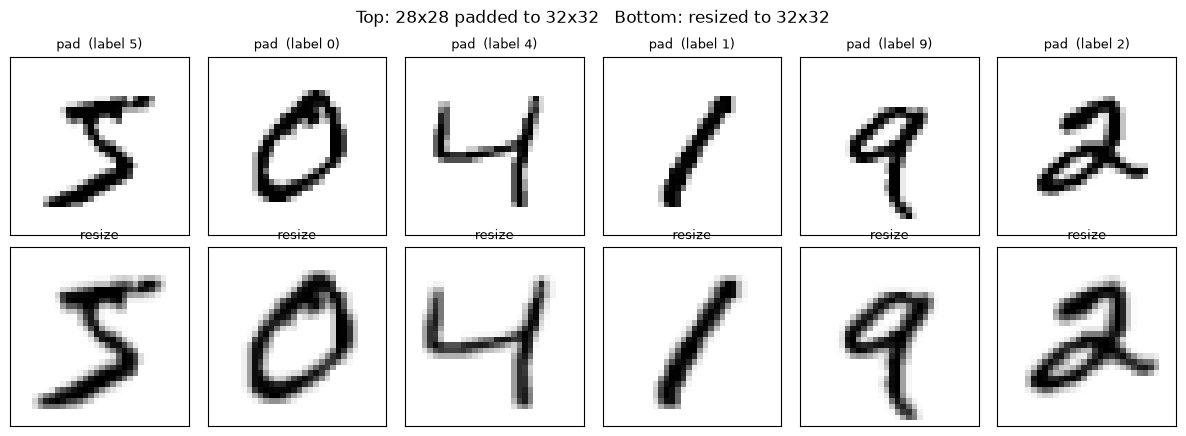

墨水到 32×32 邊界的最小距離（格）： {'min': 2.0, '25%': 4.0, '50%': 5.0, 'max': 6.0}


In [3]:
# 補邊 vs 縮放（load_mnist(image_size=32) 的做法）
train_resized, _ = load_mnist(image_size=32)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for j in range(6):
    axes[0, j].imshow(X_full[j, 0], cmap="gray_r")
    axes[0, j].set_title(f"pad  (label {y_full[j]})", fontsize=9)
    axes[1, j].imshow(train_resized[j][0].numpy()[0], cmap="gray_r")
    axes[1, j].set_title("resize", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Top: 28x28 padded to 32x32   Bottom: resized to 32x32")
fig.tight_layout()
plt.show()

# 每張圖「有墨水」的範圍離 32×32 邊界最少幾格？
ink = pad32(X_full_u8) > 0  # (60000, 32, 32)
rows_any, cols_any = ink.any(axis=2), ink.any(
    axis=1
)  # (60000, 32)：每一列／每一欄有沒有墨水
margin = np.minimum.reduce(
    [
        rows_any.argmax(axis=1),  # 上方空白列數
        cols_any.argmax(axis=1),  # 左方空白欄數
        rows_any[:, ::-1].argmax(axis=1),  # 下方
        cols_any[:, ::-1].argmax(axis=1),  # 右方
    ]
)
print(
    "墨水到 32×32 邊界的最小距離（格）：",
    pd.Series(margin).describe()[["min", "25%", "50%", "max"]].to_dict(),
)

### 空間結構 1：平移一點點，在像素空間裡差多少？

把每張影像往右平移 $d$ 格（`shift_right`：空出來的欄補背景，移出右邊界的部分丟掉；上一格顯示墨水離邊界通常有 4–6 格，平移幾格幾乎不會切到數字），
用**餘弦相似度**比較原圖與平移後的圖：$\cos(a, b) = \dfrac{a\cdot b}{\|a\|\,\|b\|}$（1 = 方向完全相同、0 = 完全沒有重疊）。
像素用 0–1 的強度計算（背景 = 0，這樣只有「墨水重疊」才會貢獻相似度）。

對照組：同一類的**另一張**影像（別人寫的同一個數字）、不同類的影像。

In [4]:
# 觀察：
#   - 平移 1、2、3 格後，與原圖的餘弦相似度各是多少？ 分別是大約原來的8成、5成、3成
#     精確：0.818、0.554、0.378（3 格比較接近 4 成）
#   - 平移幾格之後，「自己平移後的版本」就比「同一類另一個人寫的」還不像自己？ 3px
def shift_right(X: np.ndarray, d: int, fill: float = 0.0) -> np.ndarray:
    """把影像（最後兩軸是列、欄）往右平移 d 格（d < 0 往左）。空出來的欄補 fill（背景值），移出邊界的部分丟掉。"""
    out = np.roll(X, d, axis=-1)
    if d > 0:
        out[..., :d] = fill
    elif d < 0:
        out[..., d:] = fill
    return out


rng = np.random.default_rng(0)
idx = rng.choice(len(X_full_u8), size=2000, replace=False)
A = pad32(X_full_u8[idx]).astype(np.float64) / 255  # (2000, 32, 32)，0–1 強度


def cosine_rows(P: np.ndarray, Q: np.ndarray) -> np.ndarray:
    """每一列各自的餘弦相似度：P、Q 都是 (m, ...) → 回傳 (m,)。"""
    P, Q = P.reshape(len(P), -1), Q.reshape(len(Q), -1)
    return (P * Q).sum(axis=1) / (np.linalg.norm(P, axis=1) * np.linalg.norm(Q, axis=1))


rows = {}
for d in [0, 1, 2, 3, 4]:
    rows[f"shift {d} px"] = cosine_rows(A, shift_right(A, d)).mean()

y_idx = y_full[idx]
same = np.array(
    [
        rng.choice(np.flatnonzero((y_idx == y_idx[i]) & (np.arange(len(idx)) != i)))
        for i in range(len(idx))
    ]
)
diff = np.array(
    [rng.choice(np.flatnonzero(y_idx != y_idx[i])) for i in range(len(idx))]
)
rows["same class, other image"] = cosine_rows(A, A[same]).mean()
rows["different class"] = cosine_rows(A, A[diff]).mean()
sim_table = pd.Series(rows, name="mean cosine similarity").round(3)
display(sim_table.to_frame())

,mean cosine similarity
shift 0 px,1.000
shift 1 px,0.818
shift 2 px,0.554
shift 3 px,0.378
shift 4 px,0.289
"same class, other image",0.525
different class,0.383


### 空間結構 2：相鄰的像素有多相關？

對所有訓練影像，計算像素 $(r, c)$ 與它右邊第 $d$ 格 $(r, c+d)$ 的相關係數（把所有影像、所有位置的配對放在一起算）。
$d = 0$ 時相關係數是 1；$d$ 越大，兩個像素離得越遠。

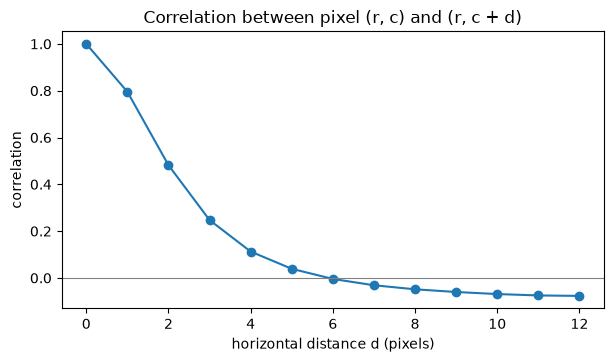

相關係數： {0: 1.0, 1: 0.795, 2: 0.482, 3: 0.247, 4: 0.113, 5: 0.039, 6: -0.004, 7: -0.031, 8: -0.049, 9: -0.06, 10: -0.069, 11: -0.075, 12: -0.077}


In [5]:
# 觀察：
#   - d = 1、2 的相關係數大約多少？大約到 d = 多少時降到 0 附近？
#     d = 1：0.795、d = 2：0.482；d = 5 降到 0.039、d = 6 約為 0（見 TODO 1 (2)）
#   - d 很大時相關係數變成負的，可能的原因是什麼？（提示：一張圖左半邊有墨水時，右邊第 10 格通常是什麼？）
#     補寫：數字只佔中央約 20 格寬，往右 7–12 格常已跑出數字或落在空洞裡 → 一邊有墨水、另一邊傾向是背景（約 −0.03 ～ −0.08）
#   - 這跟 LeNet 用 5×5 的小濾波器有什麼關係？
#     補寫：相關性在 d ≈ 4 以內明顯大於 0 → 局部特徵只需要約 5×5 的視窗；更大的結構交給深層組合（TODO 1 (2)(b)）
B = pad32(X_full_u8[:10_000]).astype(np.float64) / 255  # 取 10,000 張就夠準
corr = []
ds = np.arange(0, 13)
for d in ds:
    left = B[:, 4:28, 4 : 28 - d].ravel() if d > 0 else B[:, 4:28, 4:28].ravel()
    right = B[:, 4:28, 4 + d : 28].ravel() if d > 0 else left
    corr.append(np.corrcoef(left, right)[0, 1])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ds, corr, "o-")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("horizontal distance d (pixels)")
ax.set_ylabel("correlation")
ax.set_title("Correlation between pixel (r, c) and (r, c + d)")
plt.show()
print("相關係數：", dict(zip(ds.tolist(), np.round(corr, 3).tolist())))

### TODO 1（問答）EDA 小結

> **(1)** 平移與像素空間
>
> **(a)** 從上面的表格讀：平移 1、2、3 格後，與原圖的平均餘弦相似度各是多少？「同一類另一張影像」是多少？

相似度分別為 0.818、0.554、0.378，同一類另一張 0.525。

✓ 數字完全正確。補充：不同類的影像是 0.383 —— 平移 3 格（0.378）的自己，跟「另一個數字」差不多不像。

> **(b)** 平移幾格之後，「自己平移後的版本」在像素空間裡就比「別人寫的同一個數字」還不像自己？
> MLP 的第一層是 $z = xW + b$（$x$ 是攤平的 784 或 1024 個像素），它看到的就是像素空間 —— 對 MLP 而言，同一個筆畫平移 2 格是「相似的輸入」嗎？
> （重述第 1 課 TODO 18 (3)：MLP 把像素當成沒有順序的獨立特徵，每個位置的筆畫都要分別學）

平移超過 2 px 後就比另外一張相同 class 還不相像。對 MLP 而言，像素的移動相當於 column 的移動，本身的權重在訓練的時候不會被其他 column 影響。

- 格數 ✓：平移 2 格（0.554）和同類另一張（0.525）差不多，平移 3 格（0.378）就明顯低於它。
- 「像素移動 = column 移動」✓，方向對。
- **修正**「權重在訓練時不會被其他 column 影響」：這句不精確，也不是重點。每一列權重的梯度 $\partial L/\partial W_{j\cdot} = x_j\cdot\text{dout}$ 中，$\text{dout}$ 由所有像素共同決定，所以各列在訓練中其實會互相影響。重點是**不同位置之間沒有共用的參數**：
  - 第一層 $z = \sum_j x_j W_{j\cdot}$：像素 $j$ 的墨水只乘上第 $j$ 列的權重 $W_{j\cdot}$。
  - 筆畫平移 2 格後，墨水落在**另一批**像素上，改由**另一批**權重處理。原本那批權重學到的「這裡有一段斜線」，完全幫不上新位置的忙。
  - 所以對 MLP 而言，平移 2 格**不是**相似的輸入：兩個輸入向量只重疊約 55%，第一層的輸出也會差很多。
  - 結論：MLP 必須在**每一個位置**分別看過足夠多的例子，才學得會「筆畫在這裡」——這是它需要大量資料的原因之一（第 5 節學習曲線會驗證）。

> **(2)** 相鄰像素的相關
>
> **(a)** $d = 1$、$2$ 的相關係數大約多少？大約 $d$ = 多少時降到 0 附近？

分別為 0.8、0.5，$d = 6$ 的時候相關係數差不多降到 0。

✓。精確數字：$d = 1$：0.795、$d = 2$：0.482、$d = 3$：0.247、$d = 5$：0.039、$d = 6$：−0.004。

> **(b)** 「像素的資訊主要跟附近的像素有關」→ 一個偵測「一小段斜線」的單元，需要看整張 32×32 的圖嗎？大概需要看多大的範圍？這就是 CNN 的第一個設計「局部連接」（每個單元只看一小塊相鄰的像素）。

不用看整張圖，但應該要看到筆畫開始到結束之間相關的格子。

**修正**：「不用看整張圖」✓，但「看到筆畫從開始到結束」不對 —— 一條完整的筆畫可能長達 15–20 格，那幾乎是整張圖。

- 第一層的單元只負責「**一小段**」筆畫（一段斜線、一個轉角、一個端點），只需要看相關係數還明顯大於 0 的範圍：由 (a)，大約 $d \le 4$ → **約 5×5 的視窗**，正好是 LeNet 濾波器的大小。超過這個距離的像素跟中心幾乎無關，連過去只會多出要學的參數。
- 完整的筆畫、整個數字，是由**更深的層**把局部特徵組合起來：每多一層卷積＋池化，一個單元「看到」的輸入範圍（**感受野**，receptive field）就變大。conv2 的一格大約對應輸入的 14×14（TODO 17 (2)(c) 會推導）。
- 這就是 CNN 的**階層式**設計：淺層看局部、深層看整體。

**補充**（上面「觀察」裡沒回答的那題：$d$ 很大時為什麼相關係數變成負的）：數字只佔中央約 20 格寬。一個像素有墨水時，它通常在筆畫上；往右 7–12 格常常已經跑出這個數字，或落在數字中間的空洞（0 的中間、4 的開口）→ 一邊有墨水時另一邊傾向是背景，所以是輕微的負相關（約 −0.03 到 −0.08）。

> **(3)** 補邊的順序
>
> **(a)** 上面印出的「背景像素標準化後的值」是多少？

標準化後的值為 −0.4242。

✓。即 $(0 - 0.1307)/0.3081$。

> **(b)** 如果先標準化、再用 `np.pad` 補 0，補出來的邊框在標準化後的空間裡代表什麼顏色（比背景亮還是暗、還是一樣）？這樣的邊框會不會讓模型以為影像四周有一圈「墨水」？

先標準化再補 0，邊框在標準化後的空間就不是純白色而是帶有灰度的顏色，模型會覺得四周有一團墨水在旁邊沒錯。

✓ 結論正確。精確說法：

- 標準化後的 0 換回原始像素值：$x = 0\cdot 0.3081 + 0.1307 = 0.1307$，也就是 $0.1307 \times 255 \approx 33$ —— 一圈強度約 13% 的**淡墨水**（比背景的 0 多了墨水）。
- 它跟背景（−0.4242）之間有一個 0.4242 的落差，形成一圈**假的邊緣**。所有偵測邊緣的濾波器都會在影像四周起反應，而且每張影像都一樣，對分類完全沒有幫助，只會干擾特徵。
- 同樣的陷阱：`nn.Conv2d(..., padding=2)` 也是在**標準化後**補 0。所以本章選擇在 uint8 補邊（0 = 背景），之後的資料增強（`RandomAffine` 補 0）也作用在 uint8 上。
- 原則：**補的值應該等於「背景」在當下那個空間裡的值**。

---
## 2. Baseline

兩個參照點，都在同一個 validation set 上評估：

- **Dummy prior**：不看影像，永遠輸出訓練集的類別比例。
- **MLP 1024 → 512 → 10**（第 1 課調參後的最佳設定：ReLU、lr 0.3、weight decay 1e-4、15 epochs）。
  輸入是補邊後的 32×32 = 1,024 個像素（比第 1 課多出來的 240 個邊框像素永遠是背景，跟第 1 課那 67 個「永遠是 0」的像素一樣，不帶任何資訊）。

訓練用第 1 課寫好的 `train_torch`、`predict_proba_torch`（已完成，直接搬過來；它們只把資料當成「第一個維度是樣本」的陣列，
所以 4 維的影像 $(n, 1, 32, 32)$ 也能直接用）。

In [6]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, log_loss


def val_scores(prob: np.ndarray, y: np.ndarray = y_va) -> dict[str, float]:
    """prob (n, 10) 是預測機率。回傳 {"accuracy": ..., "log_loss": ...}。"""
    return {
        "accuracy": round(accuracy_score(y, prob.argmax(axis=1)), 4),
        "log_loss": round(log_loss(y, prob, labels=np.arange(10)), 4),
    }


val_table = pd.DataFrame(
    columns=["accuracy", "log_loss"]
)  # 所有模型的 validation 成績，之後一路往下加
dummy = DummyClassifier(strategy="prior").fit(X_tr.reshape(len(X_tr), -1), y_tr)
val_table.loc["Dummy prior"] = val_scores(
    dummy.predict_proba(X_va.reshape(len(X_va), -1))
)
display(val_table)

,accuracy,log_loss
Dummy prior,0.1124,2.3012


In [7]:
import torch
from torch import nn
from learning_map.utils import count_parameters, get_device, set_seed

device = get_device()


@torch.no_grad()
def predict_proba_torch(
    net: nn.Module, X: np.ndarray, batch_size: int = 5_000
) -> np.ndarray:
    """X (n, ...) → (n, 10) 的類別機率（float64 numpy）。"""
    net.eval()
    out = []
    for s in range(0, len(X), batch_size):
        xb = torch.as_tensor(X[s : s + batch_size], dtype=torch.float32, device=device)
        logits = net(xb).cpu().double()  # MPS 不支援 float64，先搬回 CPU 再轉
        out.append(torch.log_softmax(logits, dim=1).exp().numpy())
    return np.vstack(out)


def train_torch(
    net: nn.Module,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray | None = None,
    y_val: np.ndarray | None = None,
    *,
    lr: float = 0.1,
    batch_size: int = 128,
    n_epochs: int = 10,
    weight_decay: float = 0.0,
    seed: int = 0,
    restore_best: bool = False,
    verbose: bool = True,
) -> dict:
    """mini-batch SGD 訓練 net（就地修改）。第 1 課的版本，原封不動。

    回傳 history：
    - "train_loss"：每個 epoch 內 batch loss 的平均（「邊訓練邊算」）
    - "val_loss"、"val_acc"：每個 epoch 結束時的 validation 交叉熵與 accuracy
    - "seconds"：每個 epoch 花的秒數
    - "best_epoch"、"best_val_loss"：validation loss 最低的 epoch（從 1 起算）與其值
    restore_best=True：訓練完把權重換回 best_epoch 時的權重（early stopping）。
    """
    g = torch.Generator().manual_seed(seed)  # 打亂順序用的亂數，與初始化分開
    net.to(device)
    Xt = torch.as_tensor(X_train, dtype=torch.float32, device=device)
    yt = torch.as_tensor(y_train, dtype=torch.long, device=device)
    opt = torch.optim.SGD(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    hist: dict = {"train_loss": [], "val_loss": [], "val_acc": [], "seconds": []}
    best_loss, best_epoch, best_state = np.inf, 0, None
    n = len(Xt)

    for epoch in range(n_epochs):
        net.train()
        t0 = time.perf_counter()
        perm = torch.randperm(n, generator=g).to(device)
        total = torch.zeros((), device=device)
        for start in range(0, n, batch_size):
            idx = perm[start : start + batch_size]
            xb, yb = Xt[idx], yt[idx]
            opt.zero_grad()
            loss = loss_fn(net(xb), yb)
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        train_loss = total.item() / n
        hist["train_loss"].append(train_loss)
        msg = f"epoch {epoch + 1:2d}  train_loss {train_loss:.4f}"
        if not np.isfinite(train_loss):
            if verbose:
                print(msg + "  → 發散，停止訓練")
            break
        if X_val is not None:
            s = val_scores(predict_proba_torch(net, X_val), y_val)
            hist["val_loss"].append(s["log_loss"])
            hist["val_acc"].append(s["accuracy"])
            msg += f"  val_loss {s['log_loss']:.4f}  val_acc {s['accuracy']:.4f}"
            if s["log_loss"] < best_loss:
                best_loss, best_epoch = s["log_loss"], epoch + 1
                best_state = {
                    k: v.detach().clone() for k, v in net.state_dict().items()
                }
        hist["seconds"].append(time.perf_counter() - t0)
        if verbose:
            print(msg + f"  ({hist['seconds'][-1]:.1f}s)")

    hist["best_epoch"], hist["best_val_loss"] = best_epoch, best_loss
    if restore_best and best_state is not None:
        net.load_state_dict(best_state)
    return hist


def make_mlp(
    width: int = 512, d_in: int = 32 * 32, n_classes: int = 10
) -> nn.Sequential:
    """第 1 課的 MLP：攤平 → Linear → ReLU → Linear。nn.Flatten 把 (n, 1, 32, 32) 攤成 (n, 1024)。"""
    return nn.Sequential(
        nn.Flatten(), nn.Linear(d_in, width), nn.ReLU(), nn.Linear(width, n_classes)
    )


MLP_CFG = {"lr": 0.3, "weight_decay": 1e-4, "n_epochs": 15}  # 第 1 課 5C 選出的設定

set_seed(0)
mlp_base = make_mlp()
hist_mlp = train_torch(mlp_base, X_tr, y_tr, X_va, y_va, **MLP_CFG, verbose=False)
val_table.loc["MLP 512 (PyTorch, ch1 best)"] = val_scores(
    predict_proba_torch(mlp_base, X_va)
)
print(
    "MLP 參數量：",
    count_parameters(mlp_base),
    f"   每個 epoch 約 {np.mean(hist_mlp['seconds']):.1f}s",
)
display(val_table)
print("✅ MLP 的 validation accuracy 應約 0.98（第 1 課：0.983）")

使用裝置：mps
MLP 參數量： 529930    每個 epoch 約 0.3s


,accuracy,log_loss
Dummy prior,0.1124,2.3012
"MLP 512 (PyTorch, ch1 best)",0.9816,0.0670


✅ MLP 的 validation accuracy 應約 0.98（第 1 課：0.983）


### TODO 2（問答）Baseline 與預測

> **(1)** 讀上面的輸出：MLP 的參數量是多少？validation accuracy 是多少？跟第 1 課（784 個輸入、407,050 個參數、0.983）比，多出來的 240 個邊框像素讓參數量多了多少？分數有變嗎？為什麼（提示：這些像素在每張影像都一樣）？

MLP 的參數量有 529,930 個參數，validation accuracy 為 0.9816，與第 1 課相比多了約 12 萬個參數，分數差不多，因為這些像素本來就是不重要的背景像素。

- 數字 ✓：多出的參數剛好是 $240 \times 512 = 122{,}880$（第一層多 240 列權重，每列 512 個）。
- 「分數差不多」✓，而且可以說得更有根據：0.9816 和 0.983 只差 0.0014，跟 accuracy 的標準誤差 $\sqrt{0.98 \times 0.02 / 10{,}000} \approx 0.0014$ 一樣大（第 1 課 TODO 2 (1)）。這種差距分不出好壞，連換個 seed 都可能出現。
- **補充**（「不重要」的精確意思）：這 240 個像素在**每一張影像都是同一個值**（標準化後 −0.4242），變異數是 0，不帶任何能區分影像的資訊。它們進到第一層的貢獻是 $\sum_{j \in \text{邊框}} (-0.4242)\,W_{j\cdot}$，對每張影像都一樣，效果等於**多加了一個偏差** $b$。
  - 反向傳播時，這 240 列權重收到的梯度都是 $-0.4242 \cdot \sum_i \text{dout}_{i\cdot}$，全部一模一樣，只會一起移動、學不到任何東西。
  - 所以這 12 萬個參數是**浪費掉的**：記憶體和計算都要付，卻沒有用。對照 LeNet：卷積層的參數量跟影像大小無關（TODO 10）。

> **(2)** 先寫下預測，第 7 節再驗證（寫錯沒關係，重點是先想）：
>
> **(a)** 第 1 課打亂像素（每張影像套同一個固定排列）後，MLP 的準確率完全不變。你猜 LeNet 打亂像素後會怎樣？為什麼？

打亂像素後應該會 accuracy 暴跌，因為 LeNet 的結構會去學習局部特徵，會記住相對位置，如果今天打亂了就學不到東西。

**預測已記下，第 7 節驗證。** 理由的方向 ✓：LeNet 的濾波器假設「相鄰的像素彼此相關」（TODO 1 (2)），打亂之後這個假設就不成立了。

驗證之前，先想想「學不到東西」這個說法會不會太強：

- 打亂之後，LeNet 還剩下哪些部件？fc1 有 48,120 個參數，它跟 MLP 的第一層有什麼共同點？
- 打亂的排列對每張影像都**一樣**，所以「第 $j$ 個位置有墨水」這件事在打亂後仍然有意義，只是那個位置的鄰居換了一批像素。
- 所以你預期的「暴跌」，是跌到接近亂猜（約 0.1），還是跌到某個中間值？會跌到比 MLP 還差嗎？

> **(b)** 把測試影像往右平移 3 格，MLP 與 LeNet 的準確率各會怎樣？

MLP 應該不會有太大變化，但是 LeNet 應該會變低。

**預測已記下，第 7 節驗證。** 不過這個預測跟你在 TODO 1 寫的結論**互相矛盾**，請先對照：

- TODO 1 (1)(b)：平移 3 格後，在像素空間裡（MLP 看到的空間）餘弦相似度只剩 0.378，比「同類別另一張影像」的 0.525 還低，跟「不同類別的影像」（0.383）差不多。MLP 又沒有共用的參數：墨水移到新位置，就改由另一批權重處理。
- 那麼對 MLP 來說，平移 3 格的「7」像不像它訓練時看過的「7」？
- 你可能是把第 1 課的**打亂像素**實驗（MLP 不受影響）套用過來了。兩者其實不同：
  - 打亂像素是**訓練和測試都用同一個排列**，MLP 重新訓練時就學會了新的排列。
  - 這裡是模型用**沒有平移的影像**訓練，測試時才遇到平移，模型沒有機會重新學。
- LeNet 平移後的表現，3D 的實驗 2（TODO 12）會先量一次「平移後預測不變的比例」。看完那個結果，可以回來修正這裡的預測。

---
## 3. 手寫模型（NumPy）

### 前置複習：第 3 節會用到的舊知識與新工具

#### 數學

**1. 卷積（convolution）的定義**

深度學習說的「卷積」，是拿一個小的權重陣列（**濾波器**、filter，也叫 kernel）在輸入上滑動，每到一個位置就做一次「對應元素相乘再加總」。

- **一維**：輸入 $x$ 長度 5、濾波器 $w$ 長度 $k = 3$，輸出 $\text{out}_r = \sum_{p=0}^{k-1} x_{r+p}\,w_p$，長度 $5 - 3 + 1 = 3$。
  例：$x = [1, 2, 3, 4, 5]$、$w = [1, 0, -1]$ →
  $\text{out}_0 = 1\cdot1 + 2\cdot0 + 3\cdot(-1) = -2$，$\text{out}_1 = 2 - 4 = -2$，$\text{out}_2 = 3 - 5 = -2$。
  （這個 $w$ 算的是「左邊減右邊」，是一個偵測**亮度變化**的濾波器：在均勻變亮的地方，輸出處處相同。）
- **二維**：$\text{out}_{rs} = \sum_{p}\sum_{q} x_{r+p,\,s+q}\,w_{pq}$。例：
$$x = \begin{pmatrix}1 & 2 & 0\\ 0 & 1 & 3\\ 2 & 0 & 1\end{pmatrix},\quad w = \begin{pmatrix}1 & 0\\ 0 & -1\end{pmatrix} \;\Rightarrow\; \text{out} = \begin{pmatrix}1\cdot1 - 1\cdot1 & 2\cdot1 - 3\cdot1\\ 0\cdot1 - 0\cdot1 & 1\cdot1 - 1\cdot1\end{pmatrix} = \begin{pmatrix}0 & -1\\ 0 & 0\end{pmatrix}$$
  （左上角 $\text{out}_{00}$ 用的是 $x$ 左上的 $2\times2$：$1\cdot w_{00} + 2\cdot w_{01} + 0\cdot w_{10} + 1\cdot w_{11} = 1 - 1 = 0$。）
- **多通道**：輸入有 $C$ 個通道（灰階 1、RGB 3、或前一層的 6 張特徵圖）時，一個濾波器的 shape 是 $(C, k, k)$，**所有通道也一起加總**，輸出一張圖。
  要輸出 $F$ 張圖（$F$ 個輸出通道），就有 $F$ 個濾波器：權重 shape $(F, C, k, k)$，每個輸出通道再加一個偏差 $b_f$。
- **名詞**：數學上的卷積會先把濾波器翻轉（$\sum_p x_{r-p}w_p$），上面不翻轉的版本嚴格說叫**互相關**（cross-correlation）。
  深度學習（包括 PyTorch 的 `nn.Conv2d`）都用不翻轉的版本但仍叫它卷積；濾波器是學出來的，翻不翻轉只差在學到的權重排列順序。

**2. 輸出大小**

- 本章的卷積：stride 1（每次滑一格）、不補邊 → $S_\text{out} = S_\text{in} - k + 1$。例：$32 - 5 + 1 = 28$。
- 一般公式（之後的章節會用到）：$S_\text{out} = \lfloor (S_\text{in} + 2P - k)/\text{stride} \rfloor + 1$，$P$ = 每邊補幾格。
- $2\times2$、stride 2 的池化：$S_\text{out} = S_\text{in}/2$。例：$28 \to 14$。

**3. 多變數鏈鎖律：同一個參數被用了好幾次，梯度就相加**（第 1 課前置複習 1）

如果 $L$ 透過 $u_1, \dots, u_m$ 依賴 $x$：$\dfrac{\partial L}{\partial x} = \sum_m \dfrac{\partial L}{\partial u_m}\cdot\dfrac{\partial u_m}{\partial x}$。
- 第 1 課的 Linear：$W$ 被 batch 裡**每一筆樣本**用到 → $\partial L/\partial W_{jk} = \sum_i X_{ij}\,\text{dout}_{ik}$（沿樣本 $i$ 加總）。
- 本章的卷積：$W$ 被每一筆樣本、而且被影像上**每一個位置** $(r, s)$ 用到 → 要沿 $i$、$r$、$s$ 三個下標加總。這就是「權重共享」在反向傳播裡的樣子。

**4. 第 1 課的反向傳播結果**（本章直接沿用）

| 層 | forward | backward（`dout` = $\partial L/\partial\,\text{out}$） |
| --- | --- | --- |
| Linear | $\text{out} = XW + b$ | $\partial L/\partial W = X^\top\text{dout}$、$\partial L/\partial b = \sum_i \text{dout}_{i\cdot}$、$\partial L/\partial X = \text{dout}\,W^\top$ |
| 激活函數 $f$ | $\text{out} = f(z)$ | $\partial L/\partial z = \text{dout}\odot f'(z)$（ReLU：$z > 0$ 的位置原封不動，其餘為 0） |
| softmax＋交叉熵 | $L = -\frac1n\sum_i \log P_{i,y_i}$ | $\partial L/\partial Z = (P - Y)/n$ |

每一層的 `backward(dout)` 只做一件事：收到 $\partial L/\partial\,\text{out}$，乘上自己的局部導數，回傳 $\partial L/\partial X$ 給前一層；有參數的層順便把 $\partial L/\partial W$、$\partial L/\partial b$ 存進 `grads`。

#### 程式

**5. 4 維的影像張量 $(n, C, S, S)$**

```python
X.shape                       # (n, C, S, S)：第幾張、第幾個通道、第幾列、第幾欄（PyTorch 慣例，叫 NCHW）
X[i, c, r, s]                 # 第 i 張影像、第 c 個通道、第 r 列第 s 欄的像素
X[:, :, r:r+k, s:s+k]         # 所有影像、所有通道，左上角在 (r, s) 的 k×k 小塊 → shape (n, C, k, k)
```

**6. `np.einsum`：把下標公式直接翻成程式**

下標字串照抄公式：逗號分隔各個輸入的下標，`->` 後面是輸出保留的下標；**出現在輸入、但沒出現在輸出的下標就被加總**。

```python
A = np.array([[1, 2], [3, 4]]);  B = np.array([[5], [6]])
np.einsum("ij,jk->ik", A, B)      # (AB)_ik = Σ_j A_ij B_jk  → [[17], [39]]，等於 A @ B
np.einsum("ij->j", A)             # Σ_i A_ij               → [4, 6]，等於 A.sum(axis=0)
np.einsum("ij,ij->i", A, A)       # Σ_j A_ij A_ij          → [5, 25]，每列的平方和
```

步驟：先寫出**帶全部下標的單一元素公式** → 每個陣列依它的 shape 順序寫下標 → 輸出保留哪些下標。
`optimize=True` 讓 NumPy 自動把運算轉成矩陣乘法（快很多），結果相同。

**7. `sliding_window_view`：一次取出所有滑動視窗（不複製資料）**

```python
from numpy.lib.stride_tricks import sliding_window_view
x = np.array([1, 2, 3, 4, 5])
sliding_window_view(x, 3)         # [[1, 2, 3], [2, 3, 4], [3, 4, 5]]，shape (3, 3)：win[r, p] = x[r + p]

X.shape                                              # (n, C, S_in, S_in)
win = sliding_window_view(X, (k, k), axis=(2, 3))    # (n, C, S_out, S_out, k, k)
win[i, c, r, s, p, q] == X[i, c, r + p, s + q]       # 左上角在 (r, s) 的視窗裡，第 (p, q) 格
```

它回傳的是**視圖**（view）：只是用不同的方式「看」同一塊記憶體，不佔額外空間，而且是唯讀的。

**8. 對切片做 `+=`：就地累加到一塊區域**

```python
a = np.zeros(5)
a[0:3] += [1, 1, 1]      # a = [1, 1, 1, 0, 0]
a[1:4] += [1, 1, 1]      # a = [1, 2, 2, 1, 0]   ← 重疊的位置會累加
```

**9. 把影像切成 2×2 的小塊：reshape 成 6 維**

```python
X.shape                                  # (n, C, S, S)，S 是偶數
X6 = X.reshape(n, C, S // 2, 2, S // 2, 2)
X6[i, c, a, u, b, v] == X[i, c, 2*a + u, 2*b + v]   # (a, b) 是第幾個小塊；(u, v) 是小塊裡的第幾格（0 或 1）
X6.max(axis=(3, 5))                      # 每個 2×2 小塊取最大 → (n, C, S/2, S/2)
G[:, :, :, None, :, None]                # (n, C, S/2, S/2) → (n, C, S/2, 1, S/2, 1)：可以 broadcast 回 6 維
```

例：$S = 4$ 的 `x = np.arange(16).reshape(1, 1, 4, 4)`，左上的小塊是 `x[0, 0, 0:2, 0:2] = [[0, 1], [4, 5]]`，
對應 `X6[0, 0, 0, :, 0, :]`；四個小塊的最大值是 `[[5, 7], [13, 15]]`。

### 從第 1 課搬過來的層（已完成）

`Linear`、`ReLU`、`Tanh`、`SoftmaxCrossEntropy`、初始化 `init_std`、梯度檢查 `numerical_grad`／`rel_error` 都是第 1 課寫好的版本，原封不動。

In [8]:
from typing import Literal, Self
from numpy.lib.stride_tricks import sliding_window_view
from numpy.typing import ArrayLike
from scipy.special import logsumexp

InitName = Literal["he", "xavier"]


def init_std(init: InitName | float, fan_in: int, fan_out: int) -> float:
    """權重初始化的標準差。He：sqrt(2 / fan_in)（給 ReLU）；Xavier：sqrt(2 / (fan_in + fan_out))（給 tanh）。"""
    if isinstance(init, (int, float)):
        return float(init)
    if init == "he":
        return np.sqrt(2 / fan_in)
    if init == "xavier":
        return np.sqrt(2 / (fan_in + fan_out))
    raise ValueError(init)


class Layer:
    """所有層的共同介面。沒有參數的層，params／grads 是空 dict。"""

    def __init__(self) -> None:
        self.params: dict[str, np.ndarray] = {}
        self.grads: dict[str, np.ndarray] = {}

    def forward(self, X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def backward(self, dout: np.ndarray) -> np.ndarray:
        raise NotImplementedError


class Linear(Layer):
    """全連接層：out = X @ W + b。X (n, d_in)、W (d_in, d_out)、b (d_out,)。"""

    def __init__(
        self,
        d_in: int,
        d_out: int,
        init: InitName | float = "he",
        rng: np.random.Generator | None = None,
        dtype: type = np.float64,
    ) -> None:
        super().__init__()
        rng = np.random.default_rng() if rng is None else rng
        W = rng.normal(0.0, init_std(init, d_in, d_out), size=(d_in, d_out))
        self.params = {"W": W.astype(dtype), "b": np.zeros(d_out, dtype=dtype)}
        self.grads = {k: np.zeros_like(v) for k, v in self.params.items()}

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.X = X
        return X @ self.params["W"] + self.params["b"]

    def backward(self, dout: np.ndarray) -> np.ndarray:
        self.grads["W"] = self.X.T @ dout
        self.grads["b"] = dout.sum(axis=0)
        return dout @ self.params["W"].T


class ReLU(Layer):
    """out = max(0, X)。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.mask = X > 0
        return X * self.mask

    def backward(self, dout: np.ndarray) -> np.ndarray:
        return dout * self.mask


class Tanh(Layer):
    """out = tanh(X)。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.out = np.tanh(X)
        return self.out

    def backward(self, dout: np.ndarray) -> np.ndarray:
        return dout * (1 - self.out**2)


class SoftmaxCrossEntropy:
    """softmax + 平均交叉熵。forward(Z, y) 回傳純量 loss；backward() 回傳 ∂L/∂Z = (P − Y)/n。"""

    def forward(self, Z: np.ndarray, y: np.ndarray) -> float:
        log_P = Z - logsumexp(Z, axis=1, keepdims=True)
        self.P = np.exp(log_P)
        self.y = y
        return float(-log_P[np.arange(len(y)), y].mean())

    def backward(self) -> np.ndarray:
        n = len(self.y)
        dZ = self.P.copy()
        dZ[np.arange(n), self.y] -= 1
        return dZ / n


def numerical_grad(f, x: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    """中央差分：回傳與 x 同 shape 的 ∂f/∂x。會就地修改 x 再改回來。"""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"])
    for _ in it:
        i = it.multi_index
        old = x[i]
        x[i] = old + eps
        f_plus = f()
        x[i] = old - eps
        f_minus = f()
        x[i] = old
        grad[i] = (f_plus - f_minus) / (2 * eps)
    return grad


def rel_error(a: np.ndarray, b: np.ndarray) -> float:
    """相對誤差 ‖a − b‖ / ‖a + b‖（兩者都是 0 時回傳 0）。"""
    denom = np.linalg.norm(a + b)
    return 0.0 if denom == 0 else float(np.linalg.norm(a - b) / denom)


def check_layer(layer: Layer, X: np.ndarray, seed: int = 0) -> dict[str, float]:
    """單一層的梯度檢查（float64）。f(X) = Σ forward(X) ⊙ G，G 是隨機的上游梯度。

    回傳 {"dX": 相對誤差, "dW": ..., "db": ...}（沒有參數的層只有 dX）。
    """
    G = np.random.default_rng(seed).normal(size=layer.forward(X).shape)
    f = lambda: float(np.sum(layer.forward(X) * G))
    layer.forward(X)
    dX = layer.backward(G)
    errs = {"dX": rel_error(dX, numerical_grad(f, X))}
    for k in layer.params:
        errs["d" + k] = rel_error(layer.grads[k], numerical_grad(f, layer.params[k]))
    return errs

### 3A. 卷積層 `Conv2d`

#### 符號表（第 3 節通用）

| 符號 | 意義 | shape | 程式裡 |
| --- | --- | --- | --- |
| $n$ | 一個 batch 的樣本數 | 純量 | `len(X)` |
| $C$ | 輸入通道數（灰階影像 1；第二個卷積層的輸入是前一層的 6 張特徵圖 → 6） | 純量 | `c_in` |
| $F$ | 輸出通道數 = 濾波器個數（每個濾波器輸出一張**特徵圖**，feature map） | 純量 | `c_out` |
| $k$ | 濾波器邊長（LeNet 用 5） | 純量 | `self.k` |
| $S_\text{in}$、$S_\text{out}$ | 輸入、輸出影像的邊長（本章影像都是正方形），$S_\text{out} = S_\text{in} - k + 1$ | 純量 | `X.shape[2]`、`dout.shape[2]` |
| $X$ | 這一層的**輸入**（cache） | $(n, C, S_\text{in}, S_\text{in})$ | `X`；forward 存成 `self.X` |
| $W$ | 濾波器（**參數**）：$F$ 個、每個 $(C, k, k)$ | $(F, C, k, k)$ | `self.params["W"]` |
| $b$ | 偏差（**參數**）：每個輸出通道一個 | $(F,)$ | `self.params["b"]` |
| out | 這一層的**輸出**（$F$ 張特徵圖） | $(n, F, S_\text{out}, S_\text{out})$ | `forward` 的回傳值 |
| win | 所有滑動視窗（cache）：$\text{win}_{icrspq} = X_{i,c,r+p,s+q}$ | $(n, C, S_\text{out}, S_\text{out}, k, k)$ | `self.win` |
| dout | **上游梯度** $\partial L/\partial\,\text{out}$ | 同 out | `dout` |
| $\partial L/\partial W$、$\partial L/\partial b$ | **參數的梯度**（backward 的結果） | 同 $W$、$b$ | `self.grads["W"]`、`self.grads["b"]` |
| $\partial L/\partial X$ | 傳給**前一層**的梯度 | 同 $X$ | `dX` |
| $i$ | 第幾筆樣本 | — | axis 0 |
| $c$、$f$ | 輸入通道、輸出通道 | — | — |
| $r$、$s$ | **輸出**的第幾列、第幾欄（= 視窗左上角在輸入的位置） | — | — |
| $p$、$q$ | 濾波器裡的第幾列、第幾欄（視窗內的位移） | — | — |

**forward 的單一元素公式**：

$$\text{out}_{ifrs} = \sum_{c=0}^{C-1}\sum_{p=0}^{k-1}\sum_{q=0}^{k-1} X_{i,\,c,\,r+p,\,s+q}\;W_{fcpq} \;+\; b_f$$

讀法：第 $i$ 張影像的第 $f$ 張特徵圖，在位置 $(r, s)$ 的值 = 把第 $f$ 個濾波器蓋在輸入「左上角 $(r, s)$」的 $k\times k$ 視窗上（所有通道），對應元素相乘再加總，再加偏差。

**跟 Linear 的關係**：把一個視窗攤平成長度 $Ck^2$ 的向量，卷積就是「對每一個位置，做同一個 Linear（$Ck^2 \to F$）」。
- **局部連接**：每個輸出只看 $k\times k$ 的視窗，不是整張圖。
- **權重共享**：每個位置用的是**同一組** $W$、$b$。

**卷積層的初始化**：一個輸出單元加總了 $C\cdot k\cdot k$ 個輸入，所以 $\text{fan}_\text{in} = Ck^2$（不是 $C$）；He 初始化的標準差是 $\sqrt{2/(Ck^2)}$。

In [9]:
def conv2d_naive(X: np.ndarray, W: np.ndarray, b: np.ndarray) -> np.ndarray:
    """最直接的卷積：對每一個輸出位置 (r, s) 各算一次。只拿來核對 Conv2d.forward。

    X (n, C, S_in, S_in)、W (F, C, k, k)、b (F,) → 回傳 out (n, F, S_out, S_out)，S_out = S_in − k + 1。
    """
    n, C, S_in, _ = X.shape
    F, _, k, _ = W.shape
    S_out = S_in - k + 1
    out = np.zeros((n, F, S_out, S_out), dtype=np.result_type(X, W))
    for r in range(S_out):
        for s in range(S_out):
            patch = X[
                :, :, r : r + k, s : s + k
            ]  # (n, C, k, k)：左上角在 (r, s) 的視窗
            # TODO 3（程式）：一行。算出位置 (r, s) 上所有樣本、所有輸出通道的值，填進 out[:, :, r, s]（shape (n, F)）
            #   單一元素：out[i, f, r, s] = Σ_c Σ_p Σ_q patch[i, c, p, q] · W[f, c, p, q] + b[f]
            #   保留的下標：i、f；加總的下標：c、p、q
            #   兩種寫法擇一：
            #     - np.einsum：照前置複習 6 的步驟，依 patch、W 的 shape 順序寫下標，輸出保留 i、f
            #     - broadcasting：patch[:, None] 是 (n, 1, C, k, k)、W[None] 是 (1, F, C, k, k)，相乘後對哪幾個 axis 加總？
            #   最後加上 b：(F,) 會自動 broadcast 到 (n, F)
            out[:, :, r, s] = (patch[:, None] * W[None]).sum(axis=(2, 3, 4)) + b

            # ── 同一件事的 np.einsum 寫法（結果完全相同，可以互換）────────────────
            out[:, :, r, s] = np.einsum("icpq,fcpq->if", patch, W) + b
            #
            # 下標字串怎麼來的：把單一元素公式「照抄」，只是把 Σ 和乘號拿掉
            #
            #   公式：out[i, f] = Σ_c Σ_p Σ_q  patch[i, c, p, q] · W[f, c, p, q]
            #                                     ↓                 ↓
            #   字串：                         "icpq      ,       fcpq    ->  if"
            #                                  patch 的下標      W 的下標      輸出的下標
            #
            #   每個字母 = 一個中文名字：i 第幾張影像、f 第幾個濾波器、c 通道、p 視窗第幾列、q 視窗第幾欄
            #
            #   einsum 的規則只有一條：
            #     出現在「->」右邊的字母 → 保留（i、f：每張影像 × 每個濾波器各一個答案）
            #     只出現在左邊的字母     → 自動加總（c、p、q：整個視窗逐格相乘後加起來）
            #   兩個輸入都有的字母（c、p、q）→ 代表「對齊」：patch 的第 c 通道第 (p, q) 格，乘 W 的第 c 通道第 (p, q) 格
            #
            # 對照 broadcasting 寫法：
            #   patch[:, None] * W[None]   ← einsum 用「i 和 f 是不同字母」自動做到（不同字母 = 所有組合）
            #   .sum(axis=(2, 3, 4))       ← einsum 用「c、p、q 不寫在 -> 右邊」自動做到
            #   einsum 不用自己數 axis 編號，也不用插 None，字母本身就寫出了每一軸的意思
    return out


# 自我檢查：前置複習 1 的二維例子
x_demo = np.array([[1, 2, 0], [0, 1, 3], [2, 0, 1]], dtype=float)[
    None, None
]  # (1, 1, 3, 3)
w_demo = np.array([[1, 0], [0, -1]], dtype=float)[None, None]  # (1, 1, 2, 2)
print(conv2d_naive(x_demo, w_demo, np.zeros(1))[0, 0])
print("✅ 應為 [[0, -1], [0, 0]]")

[[ 0. -1.]
 [ 0.  0.]]
✅ 應為 [[0, -1], [0, 0]]


### TODO 4（問答）推導卷積層的反向傳播

**設定**：這一層的輸出 out 之後的所有計算合起來記作 $g$，$L = g(\text{out})$。這一層看不到 $g$，只拿得到 $\text{dout} = \partial L/\partial\,\text{out}$（與 out 同 shape）。

（本題以對話方式討論，下面整理你的作答與批改。）

#### 先釐清的名詞（討論中出現的混淆）

| 名字 | 是什麼 | 例子（前置複習 1：3×3 輸入、2×2 濾波器，左上角位置） |
| --- | --- | --- |
| **濾波器** $W$ | 權重；**只有一個**，滑過所有位置（權重共享） | $\begin{pmatrix}1 & 0\\ 0 & -1\end{pmatrix}$ |
| **patch（視窗）** | 輸入被濾波器蓋住的那一塊；**每個位置不同** | $\begin{pmatrix}1 & 2\\ 0 & 1\end{pmatrix}$ |
| $\text{out}[i, f, r, s]$ | patch 與濾波器逐點相乘後**加總**得到的**一個數** | $1 + 0 + 0 - 1 = 0$ |
| **特徵圖** | 一個濾波器在所有位置的 out 排成的圖 | $\begin{pmatrix}0 & -1\\ 0 & 0\end{pmatrix}$ |

- 位置數：每個方向 $S_\text{out} = S_\text{in} - k + 1 = 3 - 2 + 1 = 2$，共 4 個值（視窗必須整個落在圖內），不是 9 個。
- 逐點相乘得到的 2×2 只是中間結果，加總後就丟掉。
- 下標分工：**$f$ 選濾波器（＝第幾張特徵圖），$(r, s)$ 選位置，位置決定蓋住哪個 patch**。
- $f$ 不能用 $r, s$ 表示：有兩個以上的濾波器時，同一個位置會有好幾個值。例如加一個濾波器 $\begin{pmatrix}1 & -1\\ 0 & 0\end{pmatrix}$，它的特徵圖是 $\begin{pmatrix}-1 & 2\\ -1 & -2\end{pmatrix}$；位置 $(0,0)$ 上兩個濾波器分別給出 0 與 −1。$(r, s)$ 回答「在哪裡」，$f$ 回答「是哪一種特徵」，跟 RGB 影像的通道軸是同一個道理。

---

> **(1)** $\partial L/\partial W$（權重共享）
>
> **(a)** 固定一個權重 $W[f, c, p, q]$。看 forward 的公式：哪些 $\text{out}[i, f', r, s]$ 用到了它？（$f'$ 必須等於誰？$i$、$r$、$s$ 可以是哪些值？）

每張影像都可以切成多個 $k\times k$ 的塊狀，這個 $W$ 要跟每個塊狀逐點相乘再相加；（修正後）$f' = f$，因為特定的一組權重就是一個濾波器。

- 「每張影像、每個塊都會用到」✓。
- **修正**：最初的回答是「$f'$ 要等於輸出的特徵圖數目，也就是 $C \times (S_\text{in} - k + 1)$」。這混淆了**下標**和**數量**：$f'$ 問的是「哪一張」，不是「幾張」。而且 $C$ 是輸入通道數、$S_\text{in} - k + 1$ 是特徵圖的邊長，都跟 $f'$ 無關。

$$\text{out}[i, f', r, s] = \sum_c\sum_p\sum_q X[i, c, r+p, s+q]\cdot W[f', c, p, q] + b[f']$$

第 $f'$ 張特徵圖只用第 $f'$ 個濾波器，所以：

| 下標 | 可以是哪些值 | 理由 |
| --- | --- | --- |
| $f'$ | 只能是 $f$ | $W[f, \dots]$ 屬於第 $f$ 個濾波器，只用來算第 $f$ 張特徵圖 |
| $i$ | 全部 $0 \dots n-1$ | 每張影像都用同一組濾波器 |
| $r, s$ | 全部 $0 \dots S_\text{out}-1$ | 權重共享：同一個濾波器滑過所有位置 |

一個權重共被 $n \cdot S_\text{out}^2$ 個輸出用到。$c, p, q$ 則決定它在每個位置乘到輸入的哪一格。

> **(b)** 對其中一個用到它的輸出：$\partial\,\text{out}[i, f, r, s] / \partial W[f, c, p, q] = ?$

（小例子）逐點相乘是 $x_{11}w_{11} + x_{12}w_{12} + x_{21}w_{21} + x_{22}w_{22}$，微分之後是 $x_{11} + x_{12} + x_{21} + x_{22}$，所以是對應 patch 內所有數值組成的一個矩陣。

- 結論「patch 組成的矩陣」✓，但**修正**中間那步：偏微分每次只對**一個**權重，其他權重當常數，所以**不會相加**：
$$\frac{\partial\,\text{out}}{\partial w_{11}} = x_{11},\ \frac{\partial\,\text{out}}{\partial w_{12}} = x_{12},\ \dots \quad\Rightarrow\quad \frac{\partial\,\text{out}}{\partial W} = \begin{pmatrix}x_{11} & x_{12}\\ x_{21} & x_{22}\end{pmatrix} = \text{patch}$$
  四個偏導數各自是一個數，排在一起才是 patch。
- 一般式：濾波器的第 $(p, q)$ 格，在位置 $(r, s)$ 乘到輸入的 $(r+p, s+q)$：
$$\frac{\partial\,\text{out}[i, f, r, s]}{\partial W[f, c, p, q]} = X[i, c, r+p, s+q] = \text{win}[i, c, r, s, p, q]$$
- 對照：對 $w$ 微分剩 $x$，對 $x$ 微分剩 $w$（$x\cdot w$ 中兩者地位對稱），(3) 會用到。

> **(c)** 用多變數鏈鎖律（前置複習 3），寫出 $\partial L/\partial W[f, c, p, q]$ 的單一元素公式。哪些下標被加總？把 $X[i, c, r+p, s+q]$ 換成 $\text{win}[i, c, r, s, p, q]$，寫成 `np.einsum` 的下標字串。

第一次：$\partial L/\partial W[f, c, p, q] = \partial L/\partial\,\text{out} \cdot \partial\,\text{out}/\partial W[f, c, p, q]$，其中 $\partial\,\text{out}/\partial W = \text{win}[i, c, r, s, p, q]$。第二次（補加總）：需要加總 $c$、$r$、$s$，dout 的下標是 $i, f, p, q$。

- 偏導數那半 ✓。
- **修正 1**（漏了加總）：用到這個權重的 out 不只一個，要用**多變數**鏈鎖律，每條路徑的貢獻相加。小例子：$w_{22}$ 被 4 個位置用到，
$$\frac{\partial L}{\partial w_{22}} = \text{dout}[0,0]\,x_{22} + \text{dout}[0,1]\,x_{23} + \text{dout}[1,0]\,x_{32} + \text{dout}[1,1]\,x_{33}$$
- **修正 2**（加總的是 $i, r, s$，不是 $c$）：等號左邊的 $f, c, p, q$ 指定「哪一個權重」，右邊不能把它加掉；加總的是 (a) 找到的「用到它的所有輸出」：所有 $i$、所有 $(r, s)$。
- **修正 3**（dout 的下標是 $i, f, r, s$）：dout 與 out 同 shape $(n, F, S_\text{out}, S_\text{out})$，後兩軸是**輸出位置** $r, s$；$p, q$ 是濾波器內的位置，dout 沒有這兩軸。

$$\frac{\partial L}{\partial W[f, c, p, q]} = \sum_i\sum_r\sum_s \text{dout}[i, f, r, s]\cdot\text{win}[i, c, r, s, p, q] \qquad\text{einsum：}\texttt{"icrspq,ifrs->fcpq"}$$

| 下標 | 角色 | 理由 |
| --- | --- | --- |
| $f, c, p, q$ | 保留 | 指定是哪一個權重 → $(F, C, k, k)$ |
| $i, r, s$ | 加總 | 每張影像、每個位置都用到它，每條路徑的梯度相加 |

> **(d)** 跟 Linear 的 $\partial L/\partial W = X^\top\cdot\text{dout}$（只沿樣本 $i$ 加總）比：卷積多加總了哪兩個下標？為什麼？LeNet 第一個卷積層（32×32 → 28×28），每個權重在「一張影像」上被用了幾次？

**補寫**（未作答）：多加總了位置 $r, s$。Linear 的權重只被每筆**樣本**用到一次；卷積的權重因為**權重共享**，還被每個**位置**用到。conv1 的 $S_\text{out} = 28$，每個權重在一張影像上被用了 $28 \times 28 = 784$ 次（一個 batch 128 張就是 100,352 次），梯度是這 784 × 128 條路徑的總和。

> **(2)** $\partial L/\partial b[f] = ?$（$b[f]$ 被哪些輸出用到？每個的偏導數是多少？）

這時候就跟前面的 $W$ 無關，只有濾波器會用到。程式寫成 `np.einsum("icrspq,ifrs->f", 1, dout, optimize=True)`。

- 「跟 $W$ 無關」✓。
- **修正**（「只有濾波器會用到」不精確）：$b[f]$ 是第 $f$ 個濾波器的偏差，被第 $f$ 張特徵圖的**每張影像、每個位置**用到，偏導數都是 1：
$$\frac{\partial L}{\partial b[f]} = \sum_i\sum_r\sum_s \text{dout}[i, f, r, s]$$
- **修正**（程式）：`1` 是純量、沒有任何軸，不能配 6 個字母的 `"icrspq"`（會報錯）；「乘 1」也不需要寫成運算元。寫成 `np.einsum("ifrs->f", dout)` 或 `dout.sum(axis=(0, 2, 3))`；只有一個陣列的單純加總，`sum` 較易讀。

> **(3)** $\partial L/\partial X$（用一維的小例子推）
>
> 一維、單通道：$x$ 長度 5、$w$ 長度 3、out 長度 3，$\text{out}[r] = x[r]\,w[0] + x[r+1]\,w[1] + x[r+2]\,w[2]$：
> - $\text{out}[0] = x_0w_0 + x_1w_1 + x_2w_2$
> - $\text{out}[1] = x_1w_0 + x_2w_1 + x_3w_2$
> - $\text{out}[2] = x_2w_0 + x_3w_1 + x_4w_2$
>
> **(a)** $x_2$ 被哪幾個輸出用到？寫出 $\partial L/\partial x_2$（用 dout[0..2] 與 $w$ 表示）。$x_0$ 呢？

只要濾波器有經過的地方都會用到。$\partial L/\partial x_2 = \text{dout}[0] / w_2 + \text{dout}[1] / w_1 + \text{dout}[2] / w_0$；$\partial L/\partial x_0 = \text{dout}[0]\cdot w_0$。

- 「濾波器經過的地方都會用到」✓。補充兩點：(1) 邊緣像素被經過的次數少（$x_0$ 1 次），中間的多（$x_2$ 3 次）；權重則在每個位置都被用到。(2) 每次經過時，像素對到濾波器的**不同格**（視窗右移，像素在視窗內的相對位置左移）。
- dout 與 $w$ 的配對 ✓；**修正**：要**乘**不是除。$\partial\,\text{out}[0]/\partial x_2 = w_2$，鏈鎖律是「上游梯度 × 局部偏導數」：
$$\frac{\partial L}{\partial x_2} = \text{dout}[0]\,w_2 + \text{dout}[1]\,w_1 + \text{dout}[2]\,w_0$$
- $\partial L/\partial x_0 = \text{dout}[0]\,w_0$ ✓。

> **(b)** 換個角度，固定濾波器的位移 $p$：$w[p]$ 把 $x[r+p]$ 連到 $\text{out}[r]$（$r = 0, 1, 2$）。所以 $\text{dout}[r]\,w[p]$ 要加到 $dx$ 的哪一格？寫成切片：`dx[p : p+3] += dout * w[p]`。對 $p = 0, 1, 2$ 各做一次，驗證結果跟 (a) 一樣。

`dx[1:3] += dout * w[1]`、`dx[2:3] += dout * w[2]`

- 起點 ✓；**修正**：終點要跟著移 —— `dx[1:4]`、`dx[2:5]`。$w_1$ 碰到 $x_1, x_2, x_3$ 三格；`dout * w[p]` 有 3 個元素，切片也必須是 3 格（否則 shape 不符報錯）。
- 規則：**切片長度永遠是 $S_\text{out}$，起點跟著 $p$ 移動**：`dx[p : p + S_out]`。注意這不是 forward 滑窗的長度 $k$（本例兩者剛好都是 3）；例如 $x$ 長 6、$w$ 長 3 時，forward 每個視窗長 3、共 4 個位置，backward 每個切片長 4、共 3 個。backward 是把滑窗「轉 90 度」：對每格權重取一條長 $S_\text{out}$ 的切片。
- 驗證：

| | $w_0$ 那行 | $w_1$ 那行 | $w_2$ 那行 |
| --- | --- | --- | --- |
| $dx_0$ | $\text{dout}[0]\,w_0$ | | |
| $dx_1$ | $\text{dout}[1]\,w_0$ | $\text{dout}[0]\,w_1$ | |
| $dx_2$ | $\text{dout}[2]\,w_0$ | $\text{dout}[1]\,w_1$ | $\text{dout}[0]\,w_2$ |
| $dx_3$ | | $\text{dout}[2]\,w_1$ | $\text{dout}[1]\,w_2$ |
| $dx_4$ | | | $\text{dout}[2]\,w_2$ |

$dx_0$、$dx_2$ 與 (a) 一致；切片重疊，所以要用 `+=`。

> **(c)** 二維、多通道時 (b) 怎麼推廣？對每個 $(p, q)$：`dX[:, :, p:p+S_out, q:q+S_out] += ？`（shape 要是 $(n, C, S_\text{out}, S_\text{out})$；dout 是 $(n, F, S_\text{out}, S_\text{out})$、`W[:, :, p, q]` 是 $(F, C)$，哪個下標被加總？）

下標 $F$ 要被加總。程式依序寫成 `np.einsum("ifrs,fcpq->icrs", dout, W)`，再改成 `dX[:, :, p + S_out, q + S_out] += np.einsum("ifrs,fc->icrs", dout, W, optimize=True)`。

- 加總 $f$ ✓：一個輸入像素會被**所有 $F$ 個濾波器**用到（每個濾波器都看全部輸入通道），有 $F$ 條路徑。一維例子只有 1 個濾波器，看不到這個加總。
- **修正 1**：要傳 `W[:, :, p, q]`（shape $(F, C)$，下標 `fc`），不是整個 `W`。傳整個 `W` 配 `"fcpq"` 時，einsum 會把沒寫在右邊的 $p, q$ 也加總掉（25 格權重混在一起）；配 `"fc"` 時則因軸數不符報錯。「$p, q$ 固定」要用切片真的做到，einsum 只看陣列有幾軸。
- **修正 2**：切片要有冒號，`p : p + S_out`；`p + S_out` 只是一個整數，只取到一格。
- 正確寫法（已寫進 TODO 7，梯度檢查 dX 誤差 6.2e-10 ✓）：
$$\text{區域}[i, c, r, s] \mathrel{+}= \sum_f \text{dout}[i, f, r, s]\cdot W[f, c, p, q] \qquad\texttt{dX[:, :, p:p+S\_out, q:q+S\_out] += np.einsum("ifrs,fc->icrs", dout, W[:, :, p, q])}$$

| 一維 | 二維 |
| --- | --- |
| `for p in range(3)` | `for p in range(k): for q in range(k)` |
| `dx[p : p+3]` | `dX[:, :, p:p+S_out, q:q+S_out]` |
| `dout * w[p]` | `einsum("ifrs,fc->icrs", dout, W[:, :, p, q])`（加總 $F$、展開 $C$） |

> **(d)**（觀察）(a) 的 $\partial L/\partial x_2 = \text{dout}_0w_2 + \text{dout}_1w_1 + \text{dout}_2w_0$，$w$ 的順序跟 forward 相比有什麼不同？

**補寫**（未作答）：forward 是 $x$ 由左往右配 $w_0, w_1, w_2$（$\text{out}_r = \sum_p x_{r+p}w_p$）；backward 則是 dout 由左往右配 $w_2, w_1, w_0$ —— **濾波器被翻轉了**：$\partial L/\partial x_u = \sum_p \text{dout}_{u-p}\,w_p$。把 dout 兩端各補 $k-1$ 個 0，$dx$ 就是「補 0 的 dout」與「翻轉後的濾波器」做（不翻轉的）卷積，稱為 **full convolution**。這呼應前置複習 1：數學上的卷積本來就會翻轉濾波器，所以「互相關的 backward 是卷積、卷積的 backward 是互相關」。實作上（TODO 7）用切片累加的寫法，不必真的翻轉。

#### 程式的自我檢查（TODO 5–7）

- forward 與 `conv2d_naive` 差 1.8e-15 ✓；梯度檢查 dX 6.2e-10、dW 1.2e-10、db 2.1e-10 ✓。
- **提醒**：TODO 5 的 `np.einsum("icrspq,fcpq->ifrs", self.win, W)` 漏了 `optimize=True`。結果正確，但沒有它時 NumPy 用 C 的巢狀迴圈、不走 BLAS 矩陣乘法，3C 訓練整個 LeNet 時 forward 會慢很多。請補上。

#### `Conv2d` 的實作

- `forward`：用 `sliding_window_view` 一次拿到所有視窗 `self.win`（不複製資料），再用一個 `np.einsum` 算完所有位置（TODO 5）。
- `backward`：$\partial L/\partial W$、$\partial L/\partial b$（TODO 6）與 $\partial L/\partial X$（TODO 7）分開寫，對應 TODO 4 的 (1)(2) 與 (3)。

`einsum` 都加 `optimize=True`：NumPy 會把它轉成矩陣乘法，比逐元素算快很多。

In [10]:
class Conv2d(Layer):
    """2D 卷積（stride 1、不補邊）：out[i,f,r,s] = Σ_c Σ_p Σ_q X[i,c,r+p,s+q]·W[f,c,p,q] + b[f]。

    X (n, C, S_in, S_in) → out (n, F, S_out, S_out)，S_out = S_in − k + 1。
    """

    def __init__(
        self,
        c_in: int,
        c_out: int,
        k: int,
        init: InitName | float = "he",
        rng: np.random.Generator | None = None,
        dtype: type = np.float64,
    ) -> None:
        super().__init__()
        rng = np.random.default_rng() if rng is None else rng
        fan_in, fan_out = c_in * k * k, c_out * k * k
        W = rng.normal(0.0, init_std(init, fan_in, fan_out), size=(c_out, c_in, k, k))
        self.params = {"W": W.astype(dtype), "b": np.zeros(c_out, dtype=dtype)}
        self.grads = {key: np.zeros_like(v) for key, v in self.params.items()}
        self.k = k

    def forward(self, X: np.ndarray) -> np.ndarray:
        """X (n, C, S_in, S_in) → (n, F, S_out, S_out)。存下 X 與所有視窗 win 給 backward 用。"""
        self.X = X
        self.win = sliding_window_view(
            X, (self.k, self.k), axis=(2, 3)
        )  # (n, C, S_out, S_out, k, k)
        W, b = self.params["W"], self.params["b"]
        # TODO 5（程式）：一行。用 self.win 與 W 算出所有位置的輸出，再加上偏差
        #   單一元素：out[i, f, r, s] = Σ_c Σ_p Σ_q win[i, c, r, s, p, q] · W[f, c, p, q] + b[f]
        #   步驟：win 的下標依 shape 順序是 (i, c, r, s, p, q)、W 是 (f, c, p, q) → 輸出保留哪些、順序為何？
        #        einsum 記得加 optimize=True
        #   常見錯誤：b 的 shape 是 (F,)，直接加到 (n, F, S_out, S_out) 會對齊「最後一個」axis（S_out），不是 F 那一軸！
        #           要先變成 (F, 1, 1)：b[:, None, None]
        out = (
            np.einsum("icrspq,fcpq->ifrs", self.win, W, optimize=True)
            + b[:, None, None]
        )
        return out

    def backward(self, dout: np.ndarray) -> np.ndarray:
        """dout (n, F, S_out, S_out) = ∂L/∂out。把 ∂L/∂W、∂L/∂b 存進 self.grads，回傳 ∂L/∂X (n, C, S_in, S_in)。"""
        W, k = self.params["W"], self.k
        S_out = dout.shape[2]
        # TODO 6（程式）：兩行，對應 TODO 4 (1)(2)
        #   grads["W"]：shape (F, C, k, k)  ← 用 self.win 與 dout，一個 np.einsum（加 optimize=True）
        #   grads["b"]：shape (F,)          ← dout 沿哪幾個 axis 加總？
        #   提示：TODO 4 (1)(c) 的下標公式裡，保留的是 f、c、p、q；加總的是 i、r、s
        self.grads["W"] = np.einsum("icrspq,ifrs->fcpq", self.win, dout, optimize=True)
        self.grads["b"] = dout.sum(axis=(0, 2, 3))

        dX = np.zeros_like(self.X)
        for p in range(k):
            for q in range(k):
                # TODO 7（程式）：一行，對應 TODO 4 (3)(c)
                #   濾波器的第 (p, q) 格把 X[:, :, r+p, s+q] 連到 out[:, :, r, s]（對所有 r, s）。
                #   所以 dout 乘上 W[:, :, p, q] 之後，要「累加」到 dX 從 (p, q) 開始、大小 S_out × S_out 的區域。
                #   手上的變數：dout (n, F, S_out, S_out)、W[:, :, p, q] (F, C)
                #   單一元素：區域[i, c, r, s] += Σ_f dout[i, f, r, s] · W[f, c, p, q]   ← 加總 f
                #   常見錯誤：要用 +=（不同的 (p, q) 會加到重疊的區域，見前置複習 8），不能用 =
                dX[:, :, p : p + S_out, q : q + S_out] += np.einsum(
                    "ifrs,fc->icrs", dout, W[:, :, p, q], optimize=True
                )
        return dX


# 自我檢查 1：Conv2d.forward = conv2d_naive
rng = np.random.default_rng(0)
conv_t = Conv2d(3, 4, k=3, rng=rng)
conv_t.params["b"] = rng.normal(size=4)
X_t = rng.normal(size=(2, 3, 7, 7))
out_t = conv_t.forward(X_t)
print("輸出 shape：", out_t.shape, "（應為 (2, 4, 5, 5)）")
print(
    "✅ 與 conv2d_naive 的最大差異：",
    np.abs(out_t - conv2d_naive(X_t, conv_t.params["W"], conv_t.params["b"])).max(),
    "（應 < 1e-12）",
)

# 自我檢查 2：梯度檢查（float64）
print(
    "✅ Conv2d 梯度檢查（相對誤差，都應 < 1e-7）：",
    {k: f"{v:.1e}" for k, v in check_layer(conv_t, X_t).items()},
)

輸出 shape： (2, 4, 5, 5) （應為 (2, 4, 5, 5)）
✅ 與 conv2d_naive 的最大差異： 1.7763568394002505e-15 （應 < 1e-12）
✅ Conv2d 梯度檢查（相對誤差，都應 < 1e-7）： {'dX': '6.3e-10', 'dW': '1.2e-10', 'db': '2.0e-10'}


### 3B. 池化層與 `Flatten`

**池化**（pooling）：把每個 $2\times2$ 的小塊縮成一個數（stride 2，小塊不重疊），特徵圖的邊長減半。**沒有參數**，每個通道各自處理。

| | forward | 直覺 |
| --- | --- | --- |
| 平均池化 `AvgPool2d` | 小塊的平均 | 1998 年 LeNet-5 的「subsampling」（原論文還多乘一個可學的係數、加偏差） |
| 最大池化 `MaxPool2d` | 小塊的最大值 | 之後的 CNN（AlexNet 起）幾乎都用它：「這一帶有沒有出現這個特徵」 |

兩者的作用：(1) 計算量與下一層的參數變少；(2) 特徵在小塊內移動一格，輸出可能不變 → **對小幅平移不敏感**（3D 的實驗會量化）。

**用 6 維的小塊視圖**（前置複習 9）：$X6_{i,c,a,u,b,v} = X_{i,c,2a+u,2b+v}$，$(a, b)$ = 第幾個小塊、$(u, v) \in \{0,1\}^2$ = 小塊裡的第幾格。

| 符號 | 意義 | shape | 程式裡 |
| --- | --- | --- | --- |
| $X$ | 輸入 | $(n, C, S, S)$ | `X`；shape 存成 `self.in_shape` |
| out | 輸出 | $(n, C, S/2, S/2)$ | `forward` 的回傳值 |
| dout | 上游梯度 | 同 out | `dout` |
| `dX6` | $\partial L/\partial X$ 的 6 維視圖 | $(n, C, S/2, 2, S/2, 2)$ | backward 最後 reshape 回 $(n, C, S, S)$ |
| `mask6` | 最大池化：每個小塊裡「最大值的那一格」是 1，其他 0（cache） | $(n, C, S/2, 2, S/2, 2)$ | `self.mask6` |

**backward 的推導**：
- 平均池化：$\text{out}_{icab} = \frac14\sum_{u,v} X6_{icaubv}$ → $\partial\,\text{out}_{icab}/\partial X6_{icaubv} = \frac14$。每個輸入只屬於一個小塊，所以 $\partial L/\partial X6_{icaubv} = \frac14\,\text{dout}_{icab}$：**上游梯度平均分給小塊裡的 4 格**。
- 最大池化：$\text{out}_{icab} = X6$ 裡最大的那一格。只有那一格會影響輸出（偏導數 1），其他 3 格動一點點，最大值不變（偏導數 0）→ **上游梯度整個交給最大的那一格**，其他 3 格是 0。
  （如果小塊裡有好幾格同時是最大值，跟 PyTorch 一樣只交給第一個：`mask6` 在 forward 裡已處理好。）

In [11]:
# ── 最小例子：池化的 forward 與 backward，一步一步印出 shape 與內容 ──────────────────
# 注意：陣列一定要是 float（dtype=float）。整數陣列在 dout/4 時會被截斷成整數（2.5 → 2）。
# 設定：1 張影像（n = 1）、1 個通道（C = 1）、4×4 → 2×2 池化。dout 用好認的 10、20、30、40。
np.set_printoptions(precision=2, suppress=True)
# 先用「最笨的迴圈」算出正確答案，再示範 6 維視圖的每一步；TODO 8、9 的一行版本要得到跟迴圈一樣的結果。
X_mini = np.array([[1, 3, 2, 0], [4, 2, 1, 5], [0, 1, 6, 2], [3, 2, 1, 1]], dtype=float)[
    None, None
]  # (1, 1, 4, 4)
dout_mini = np.array([[10, 20], [30, 40]], dtype=float)[
    None, None
]  # (1, 1, 2, 2)：上游梯度，跟池化的輸出同 shape
print("X[0, 0]（4×4）：\n", X_mini[0, 0])
print("dout[0, 0]（2×2）：\n", dout_mini[0, 0])

# ---- 步驟 1：切成 4 個 2×2 小塊（6 維視圖，前置複習 9）
X6_mini = X_mini.reshape(
    1, 1, 2, 2, 2, 2
)  # X6_mini[i, c, a, u, b, v] = X_mini[i, c, 2a+u, 2b+v]
print("\n步驟 1：X6 = X.reshape(1, 1, 2, 2, 2, 2)，shape", X6_mini.shape)
for a in range(2):
    for b in range(2):
        print(
            f"  小塊 (a={a}, b={b}) = X6[0, 0, {a}, :, {b}, :] =",
            X6_mini[0, 0, a, :, b, :].tolist(),
            f"→ 對應 X 的第 {2*a}–{2*a+1} 列、第 {2*b}–{2*b+1} 欄",
        )

# ---- 步驟 2：forward
print("\n步驟 2：forward（對每個小塊的 u、v 兩軸 = axis 3、5 取平均／最大）")
print("  X6.mean(axis=(3, 5))[0, 0] =", X6_mini.mean(axis=(3, 5))[0, 0].tolist())
print("  X6.max(axis=(3, 5))[0, 0]  =", X6_mini.max(axis=(3, 5))[0, 0].tolist())

# ---- 步驟 3：正確答案（迴圈版）
dX_avg_loop = np.zeros_like(X_mini)
dX_max_loop = np.zeros_like(X_mini)
for a in range(2):
    for b in range(2):
        block = X_mini[0, 0, 2 * a : 2 * a + 2, 2 * b : 2 * b + 2]
        dX_avg_loop[0, 0, 2 * a : 2 * a + 2, 2 * b : 2 * b + 2] = (
            dout_mini[0, 0, a, b] / 4
        )  # 平均分給 4 格
        u, v = np.unravel_index(block.argmax(), (2, 2))  # 最大值在小塊裡的位置
        dX_max_loop[0, 0, 2 * a + u, 2 * b + v] = dout_mini[
            0, 0, a, b
        ]  # 全部交給最大的那格
print("\n步驟 3：正確答案（迴圈版，一次處理一個小塊）")
print("  平均池化的 dX：每個小塊的 4 格都拿到 dout/4\n", dX_avg_loop[0, 0])
print(
    "  最大池化的 dX：每個小塊只有最大值那格拿到整個 dout，其他是 0\n",
    dX_max_loop[0, 0],
)

# ---- 步驟 4：6 維視圖的工具（TODO 8、9 會用到）
d6_mini = dout_mini[:, :, :, None, :, None]
print(
    "\n步驟 4a：dout[:, :, :, None, :, None] 的 shape",
    d6_mini.shape,
    " ← 在 u、v 的位置各插一個長度 1 的軸",
)
d6_full_mini = np.broadcast_to(d6_mini, (1, 1, 2, 2, 2, 2))
print(
    "步驟 4b：np.broadcast_to(..., (1, 1, 2, 2, 2, 2)) 的 shape",
    d6_full_mini.shape,
    " ← 長度 1 的軸被複製成 2",
)
print(
    "步驟 4c：reshape 回 (1, 1, 4, 4) 看看（每個 dout 被複製到它的小塊裡）：\n",
    d6_full_mini.reshape(1, 1, 4, 4)[0, 0],
)
print("  → 跟步驟 3 的平均池化答案比：還差哪一步？")

flat4_mini = X6_mini.transpose(0, 1, 2, 4, 3, 5).reshape(1, 1, 2, 2, 4)
mask6_mini = (
    (np.arange(4) == flat4_mini.argmax(axis=-1)[..., None])
    .reshape(1, 1, 2, 2, 2, 2)
    .transpose(0, 1, 2, 4, 3, 5)
)
print(
    "\n步驟 4d：MaxPool2d.forward 存下的 mask6（reshape 回 4×4 來看；1 = 該小塊的最大值）：\n",
    mask6_mini.reshape(1, 1, 4, 4)[0, 0].astype(int),
)
print(
    "  → mask6 的 shape",
    mask6_mini.shape,
    "；步驟 4a 的 d6 shape",
    d6_mini.shape,
    "：兩者相乘時 broadcasting 會怎麼對齊？結果 reshape 回 4×4 會跟步驟 3 的最大池化答案一樣嗎？",
)

X[0, 0]（4×4）：
 [[1. 3. 2. 0.]
 [4. 2. 1. 5.]
 [0. 1. 6. 2.]
 [3. 2. 1. 1.]]
dout[0, 0]（2×2）：
 [[10. 20.]
 [30. 40.]]

步驟 1：X6 = X.reshape(1, 1, 2, 2, 2, 2)，shape (1, 1, 2, 2, 2, 2)
  小塊 (a=0, b=0) = X6[0, 0, 0, :, 0, :] = [[1.0, 3.0], [4.0, 2.0]] → 對應 X 的第 0–1 列、第 0–1 欄
  小塊 (a=0, b=1) = X6[0, 0, 0, :, 1, :] = [[2.0, 0.0], [1.0, 5.0]] → 對應 X 的第 0–1 列、第 2–3 欄
  小塊 (a=1, b=0) = X6[0, 0, 1, :, 0, :] = [[0.0, 1.0], [3.0, 2.0]] → 對應 X 的第 2–3 列、第 0–1 欄
  小塊 (a=1, b=1) = X6[0, 0, 1, :, 1, :] = [[6.0, 2.0], [1.0, 1.0]] → 對應 X 的第 2–3 列、第 2–3 欄

步驟 2：forward（對每個小塊的 u、v 兩軸 = axis 3、5 取平均／最大）
  X6.mean(axis=(3, 5))[0, 0] = [[2.5, 2.0], [1.5, 2.5]]
  X6.max(axis=(3, 5))[0, 0]  = [[4.0, 5.0], [3.0, 6.0]]

步驟 3：正確答案（迴圈版，一次處理一個小塊）
  平均池化的 dX：每個小塊的 4 格都拿到 dout/4
 [[ 2.5  2.5  5.   5. ]
 [ 2.5  2.5  5.   5. ]
 [ 7.5  7.5 10.  10. ]
 [ 7.5  7.5 10.  10. ]]
  最大池化的 dX：每個小塊只有最大值那格拿到整個 dout，其他是 0
 [[ 0.  0.  0.  0.]
 [10.  0.  0. 20.]
 [ 0.  0. 40.  0.]
 [30.  0.  0.  0.]]

步驟 4a：dout[:, :, :, None, :, None

In [12]:
def to_blocks(X: np.ndarray) -> np.ndarray:
    """(n, C, S, S) → (n, C, S/2, 2, S/2, 2)：X6[i, c, a, u, b, v] = X[i, c, 2a+u, 2b+v]。S 必須是偶數。"""
    n, C, S, _ = X.shape
    assert S % 2 == 0, f"池化的輸入邊長必須是偶數，收到 {S}"
    return X.reshape(n, C, S // 2, 2, S // 2, 2)


class AvgPool2d(Layer):
    """2×2、stride 2 的平均池化。(n, C, S, S) → (n, C, S/2, S/2)。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.in_shape = X.shape
        return to_blocks(X).mean(axis=(3, 5))

    def backward(self, dout: np.ndarray) -> np.ndarray:
        """dout (n, C, S/2, S/2) → ∂L/∂X (n, C, S, S)。"""
        n, C, S, _ = self.in_shape
        # TODO 8（程式）：一行，算出 6 維的 dX6，shape (n, C, S/2, 2, S/2, 2)
        #   dX6[i, c, a, u, b, v] = dout[i, c, a, b] / 4   ← 跟 u、v 無關：小塊裡的 4 格拿到一樣的值
        #   步驟：把 dout 插入兩個長度 1 的軸（前置複習 9 的 dout[:, :, :, None, :, None]），
        #        再用 np.broadcast_to(..., (n, C, S // 2, 2, S // 2, 2)) 撐開成完整的 6 維，最後除以 4
        #   （為什麼要 broadcast_to：只有長度 1 的軸沒辦法直接 reshape 成 (n, C, S, S)，要先真的有 2 格）
        dout = dout[:, :, :, None, :, None]
        dX6 = np.broadcast_to(dout, (n, C, S // 2, 2, S // 2, 2)) / 4
        return dX6.reshape(self.in_shape)


class MaxPool2d(Layer):
    """2×2、stride 2 的最大池化。(n, C, S, S) → (n, C, S/2, S/2)。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.in_shape = X.shape
        n, C, S, _ = X.shape
        X6 = to_blocks(X)
        # 每個小塊的 4 格排成最後一軸 → 找出「第一個」最大值的位置 → 做成 one-hot 的 mask，再排回 6 維
        flat4 = X6.transpose(0, 1, 2, 4, 3, 5).reshape(n, C, S // 2, S // 2, 4)
        onehot = (
            np.arange(4) == flat4.argmax(axis=-1)[..., None]
        )  # (n, C, S/2, S/2, 4) 布林
        self.mask6 = onehot.reshape(n, C, S // 2, S // 2, 2, 2).transpose(
            0, 1, 2, 4, 3, 5
        )
        return flat4.max(axis=-1)

    def backward(self, dout: np.ndarray) -> np.ndarray:
        """dout (n, C, S/2, S/2) → ∂L/∂X (n, C, S, S)。"""
        # TODO 9（程式）：一行，算出 6 維的 dX6
        #   dX6[i, c, a, u, b, v] = dout[i, c, a, b] · mask6[i, c, a, u, b, v]   ← 只有最大值那一格拿到梯度
        #   手上的變數：self.mask6（布林，(n, C, S/2, 2, S/2, 2)，True 當 1、False 當 0）、dout (n, C, S/2, S/2)
        #   提示：dout 插入兩個長度 1 的軸之後跟 mask6 相乘，broadcasting 會自動撐開（這次不需要 broadcast_to，
        #        因為 mask6 本身就是完整的 6 維）
        #   常見錯誤：判斷「誰是最大值」用的是 forward 的輸入（已存成 mask6），不是 dout
        dout = dout[:, :, :, None, :, None]
        dX6 = dout * self.mask6
        return dX6.reshape(self.in_shape)


class Flatten(Layer):
    """(n, C, S, S) → (n, C·S·S)：把特徵圖攤平，接到 Linear。backward 只要把梯度 reshape 回原本的 shape。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.in_shape = X.shape
        return X.reshape(len(X), -1)

    def backward(self, dout: np.ndarray) -> np.ndarray:
        return dout.reshape(self.in_shape)


# 自我檢查：前置複習 9 的例子，以及梯度檢查
x16 = np.arange(16, dtype=float).reshape(1, 1, 4, 4)
print(
    "max pool：", MaxPool2d().forward(x16)[0, 0].tolist(), "（應為 [[5, 7], [13, 15]]）"
)
print(
    "avg pool：",
    AvgPool2d().forward(x16)[0, 0].tolist(),
    "（應為 [[2.5, 4.5], [10.5, 12.5]]）",
)
X_p = np.random.default_rng(1).normal(size=(2, 3, 6, 6))
for layer in [AvgPool2d(), MaxPool2d(), Flatten()]:
    print(
        f"✅ {type(layer).__name__:9s} 梯度檢查：",
        {k: f"{v:.1e}" for k, v in check_layer(layer, X_p).items()},
        "（應 < 1e-7）",
    )

max pool： [[5.0, 7.0], [13.0, 15.0]] （應為 [[5, 7], [13, 15]]）
avg pool： [[2.5, 4.5], [10.5, 12.5]] （應為 [[2.5, 4.5], [10.5, 12.5]]）
✅ AvgPool2d 梯度檢查： {'dX': '3.7e-10'} （應 < 1e-7）
✅ MaxPool2d 梯度檢查： {'dX': '4.6e-10'} （應 < 1e-7）
✅ Flatten   梯度檢查： {'dX': '3.6e-10'} （應 < 1e-7）


### 3C. 組成 LeNet-5

原論文的架構（C = convolution、S = subsampling、F = full connection）：

```
輸入 1×32×32
 → C1：卷積 6 個 5×5 濾波器        → 6×28×28
 → S2：2×2 平均池化                 → 6×14×14
 → C3：卷積 16 個 5×5 濾波器       → 16×10×10
 → S4：2×2 平均池化                 → 16×5×5
 → C5：卷積 120 個 5×5 濾波器      → 120×1×1   （5×5 的輸入配 5×5 的濾波器，輸出只剩 1 格 → 等同 Linear(400, 120)）
 → F6：全連接 84
 → 輸出：10 個 RBF 單元（量每一類的「原型」距離）
```

本章的版本做了三個現代化的簡化（同時是之後所有 CNN 的標準做法）：

| | 1998 原版 | 本章 |
| --- | --- | --- |
| C3 的連接 | 手工設計的連接表：16 張圖各自只接 S2 的部分通道（省計算、打破對稱） | 每張圖接全部 6 個通道 |
| 激活函數 | 縮放的 tanh：$1.7159\,\tanh(\tfrac23 a)$ | `tanh` 或 `ReLU`（可選） |
| 池化 | 平均後乘一個可學係數、加偏差，再過 sigmoid | `AvgPool2d` 或 `MaxPool2d`（沒有參數，可選） |
| 輸出層 | RBF ＋ 特殊的 loss | `Linear(84, 10)` ＋ softmax 交叉熵（同第 1 課） |
| C5 | 卷積層 | `Flatten` ＋ `Linear(400, 120)`（數學上等價） |

#### 程式結構：誰身上有什麼

```
LeNetNumpy（在它的方法裡，self 指整個網路）
├── layers_       = [Conv2d, act, pool, Conv2d, act, pool, Flatten, Linear, act, Linear, act, Linear]
├── names_        = ["conv1", "act1", "pool1", "conv2", "act2", "pool2", "flatten", "fc1", "act3", "fc2", "act4", "fc3"]
├── param_layers_ = [Conv2d, Conv2d, Linear, Linear, Linear]   ← step 只走這個（有參數的層）
└── loss_fn_      = SoftmaxCrossEntropy

Conv2d：params = {"W": (F, C, k, k), "b": (F,)}、grads 同 shape、cache = X、win
Linear：params = {"W": (d_in, d_out), "b": (d_out,)}、grads 同 shape、cache = X
池化、激活、Flatten：沒有參數（params 是空 dict），cache = in_shape／mask6／mask／out
```

`forward`、`backward`、`step`、`fit` 跟第 1 課的 `MLP` 一模一樣（只是層換了）：反向傳播的「接力」結構不在乎每一層是什麼，
每一層只管自己的局部梯度 —— 這就是模組化的好處。

### TODO 10（問答）手算 LeNet 每一層的輸出 shape 與參數量

**設定**：輸入 1×32×32、卷積 $k = 5$（stride 1、不補邊）、池化 2×2 stride 2、C3 每張圖接全部的輸入通道。各層大小：conv1 6 個 5×5 濾波器（輸入 1 通道）、conv2 16 個 5×5 濾波器（輸入 6 通道）、fc1 120、fc2 84、fc3 10。

這是本章的簡化版（3C 第二張表），與原論文的對應：C1 → conv1、S2 → pool1、C3 → conv2、S4 → pool2、**C5（卷積 120 個 5×5）→ flatten ＋ fc1**、F6 → fc2、RBF 輸出 → fc3。C5 的輸入 16×5×5 配 5×5 濾波器只剩一個位置（輸出 1×1），每個輸出 = 400 個輸入的加權和 = `Linear(400, 120)`，參數同為 48,120。

> **(1)** 填表（輸出 shape 不含 batch 維度）。提示：卷積層的參數量 $= F\cdot(C\cdot k\cdot k) + F$；Linear $= d_\text{in}\cdot d_\text{out} + d_\text{out}$；池化、Flatten、激活沒有參數。

| 層 | 輸出 shape | 參數量 |
| --- | --- | --- |
| conv1 | $(6, 28, 28)$ | $6\,(\text{濾波器}) \times (1\,(\text{通道}) \times 5 \times 5) + 6 = 156$ |
| pool1 | $(6, 14, 14)$ | 0 |
| conv2 | $(16, 10, 10)$ | $16\,(\text{濾波器}) \times (6\,(\text{通道}) \times 5 \times 5) + 16 = 2416$ |
| pool2 | $(16, 5, 5)$ | 0 |
| flatten | $16 \times (5 \times 5) = 400$ | 0 |
| fc1 | 120 | $400 \times 120 + 120 = 48120$ |
| fc2 | 84 | $120 \times 84 + 84 = 10164$ |
| fc3 | 10 | $84 \times 10 + 10 = 850$ |
| 總計 | | **61,706** |

✓（最後版本全對，與 `summary()` 一致）。過程中修正的地方，留作筆記：

- **修正**（參數量的式子裡不能有 $S_\text{out}$）：最初寫成 $6 \times (32 - 5 + 1) + 6$。$32 - 5 + 1 = 28$ 是**輸出 shape** 的邊長；參數量只由濾波器決定（$F$ 個、每個 $C \times k \times k$），**跟輸入、特徵圖多大無關** —— 輸入就算是 1000×1000，conv1 也還是 156 個參數（權重共享）。Linear 則相反，參數量 $d_\text{in} \times d_\text{out}$ 隨輸入變大。
- **修正**（conv2 有 16 個濾波器）：卷積層輸出幾張特徵圖只看濾波器個數 $F$，跟輸入通道數無關。conv2 的輸入通道 $C = 6$ 出現在參數量裡（每個濾波器是 $6 \times 5 \times 5$），輸出是 $F = 16$ 張。最初誤寫成 6 張，導致 pool2、flatten 一路錯（flatten 算成 150）。（題目設定原本漏寫各層大小，已補上。）
- **修正**（偏差的個數 = 濾波器個數／輸出單元數）：conv2 是 $+16$ 不是 $+6$；fc1、fc2、fc3 也各要加 $d_\text{out}$ 個偏差。
- **修正**（flatten）：400 是**輸出 shape**，參數量是 0。表中「$5 \times 5$」是 pool2 輸出的**特徵圖大小**（邊長 5），不是「每個濾波器有多少權重」—— 濾波器剛好也是 5×5，容易混淆。flatten 攤平的是 16 張 5×5 的特徵圖。
- 算術：$6 \times 25 + 6 = 156$（曾誤算成 36）。

> **(2)** 權重共享省了多少？只看 conv1（1×32×32 → 6×28×28）：
>
> **(a)** 「局部連接但不共享權重」：每個輸出位置都有自己的一組 5×5 權重（＋1 個偏差），參數量是多少？
>
> **(b)** 「全連接」：輸出的每一個數（$6 \cdot 28 \cdot 28$ 個）都連到輸入的每一個像素（1024 個），參數量是多少？
>
> **(c)** 跟 conv1 實際的參數量比，各差幾倍？

(a) $6 \times 28 \times 28 \times (5 \times 5 + 1) = 122{,}304$

(b) $6 \times 28 \times 28 \times 1024 + 6 \times 28 \times 28\,(\text{bias}) = 4{,}821{,}600$

(c) $122{,}304 / 156 = 784$，其實就相當於滑動窗格由上到下、由左到右會有的 $28 \times 28$ 個值；$4{,}821{,}600 / 156 = 30{,}907.69$

✓ 全對。

- **修正**（過程中）：(a) 最初寫成 $5 \times 5 \times 32 \times 32$ —— 要數的是**輸出**有幾個數（$6 \times 28 \times 28 = 4704$，含 6 張特徵圖），不是輸入的像素數；每個數還要加 1 個偏差。(b) 最初漏了 4,704 個偏差。
- **補充**（兩個設計各省多少）：

| 從 → 到 | 倍數 | 原因 |
| --- | --- | --- |
| 全連接 → 局部連接（不共享） | $4{,}821{,}600 / 122{,}304 \approx 39$ | **局部連接**：每個輸出只看 25 個像素，不是 1024 個（$1025/26 \approx 39$） |
| 局部連接 → 卷積 | $122{,}304 / 156 = 784$ | **權重共享**：784 個位置共用同一組濾波器 |
| 合計 | $39 \times 784 \approx 30{,}908$ | |

  兩個倍數都隨影像變大而變大（位置越多、像素越多），卷積層的參數卻不變 —— 這是 CNN 能處理大影像的原因。

> **(3)** 整個 LeNet 的參數量，跟第 2 節的 MLP（約 53 萬）比是幾分之一？參數主要集中在卷積層還是全連接層？

$61706 / 530000 \approx 0.1164$，大約九分之一，參數主要集中在 Full Connect Layer。

✓。精確數字：$61{,}706 / 529{,}930 \approx 0.116 \approx 1/8.6$。

- 全連接層 $48{,}120 + 10{,}164 + 850 = 59{,}134$，佔 **95.8%**（fc1 一層就佔 78%）；兩個卷積層合計只有 2,572（4.2%）。
- **補充**：計算量正好相反 —— 卷積層的參數少，但每個權重在每個位置都要算一次，所以乘加次數大多在卷積層（TODO 11 的成本表會看到）。之後的 CNN（如 VGG）參數也大多在最後的全連接層，後來的 ResNet、GoogLeNet 改用 global average pooling 把這些全連接層拿掉，參數量大幅下降（第三章）。

In [13]:
Activation = Literal["relu", "tanh"]
Pooling = Literal["max", "avg"]
ACTIVATIONS: dict[str, type[Layer]] = {"relu": ReLU, "tanh": Tanh}
POOLINGS: dict[str, type[Layer]] = {"max": MaxPool2d, "avg": AvgPool2d}


class LeNetNumpy:
    """LeNet-5（分類），mini-batch SGD + 選用的 weight decay。結構仿第 1 課的 MLP：fit／predict／predict_proba。

    [Conv(k) → 激活 → 池化] × len(channels) → Flatten → [Linear → 激活] × len(hidden) → Linear(n_classes)
    預設 channels=(6, 16)、hidden=(120, 84)、k=5、in_size=32 就是 LeNet-5。
    """

    def __init__(
        self,
        channels: tuple[int, ...] = (6, 16),
        hidden: tuple[int, ...] = (120, 84),
        k: int = 5,
        in_size: int = 32,
        activation: Activation = "relu",
        pool: Pooling = "max",
        init: InitName | float = "he",
        lr: float = 0.1,
        batch_size: int = 128,
        n_epochs: int = 3,
        weight_decay: float = 0.0,
        seed: int = 0,
        dtype: type = np.float32,
    ) -> None:
        self.channels, self.hidden, self.k, self.in_size = channels, hidden, k, in_size
        self.activation, self.pool, self.init = activation, pool, init
        self.lr, self.batch_size, self.n_epochs = lr, batch_size, n_epochs
        self.weight_decay, self.seed, self.dtype = weight_decay, seed, dtype

    # ------------------------------------------------------------ 建立網路
    def build(self, in_channels: int = 1, n_classes: int = 10) -> Self:
        """依序建立 layers_ 與對應的名稱 names_。"""
        self.rng_ = np.random.default_rng(self.seed)
        kw = dict(init=self.init, rng=self.rng_, dtype=self.dtype)
        Act, Pool = ACTIVATIONS[self.activation], POOLINGS[self.pool]
        self.layers_: list[Layer] = []
        self.names_: list[str] = []
        c, s = in_channels, self.in_size
        for j, c_out in enumerate(self.channels, 1):
            self.layers_ += [Conv2d(c, c_out, self.k, **kw), Act(), Pool()]
            self.names_ += [f"conv{j}", f"act{j}", f"pool{j}"]
            c, s = c_out, (s - self.k + 1) // 2
        self.layers_.append(Flatten())
        self.names_.append("flatten")
        d = c * s * s
        for j, h in enumerate(self.hidden, 1):
            self.layers_ += [Linear(d, h, **kw), Act()]
            self.names_ += [f"fc{j}", f"act{len(self.channels) + j}"]
            d = h
        self.layers_.append(Linear(d, n_classes, **kw))
        self.names_.append(f"fc{len(self.hidden) + 1}")
        self.param_layers_ = [l for l in self.layers_ if l.params]
        self.loss_fn_ = SoftmaxCrossEntropy()
        return self

    # ------------------------------------------------------------ forward / backward / 更新
    def forward(self, X: np.ndarray) -> np.ndarray:
        """X (n, C, S, S) → logits (n, K)。每一層存下 backward 需要的東西。"""
        for layer in self.layers_:
            X = layer.forward(X)
        return X

    def backward(self, dZ: np.ndarray) -> None:
        """dZ (n, K) = ∂L/∂logits。倒著走過每一層（同第 1 課 TODO 7a）。"""
        for layer in reversed(self.layers_):
            dZ = layer.backward(dZ)

    def loss_and_grads(self, X: np.ndarray, y: np.ndarray) -> float:
        """一個 batch：forward → loss → backward。回傳 loss（含 weight decay 項）。只罰 W、不罰 b。"""
        loss = self.loss_fn_.forward(self.forward(X), y)
        self.backward(self.loss_fn_.backward())
        if self.weight_decay > 0:
            for layer in self.param_layers_:
                loss += 0.5 * self.weight_decay * float(np.sum(layer.params["W"] ** 2))
                layer.grads["W"] += self.weight_decay * layer.params["W"]
        return loss

    def step(self) -> None:
        """SGD：每個有參數的層、每個參數往負梯度方向走 lr（同第 1 課 TODO 7b）。"""
        for layer in self.param_layers_:
            for name in layer.params:
                layer.params[name] -= self.lr * layer.grads[name]

    # ------------------------------------------------------------ 訓練
    def fit(
        self,
        X: ArrayLike,
        y: ArrayLike,
        X_val: ArrayLike | None = None,
        y_val: ArrayLike | None = None,
        verbose: bool = True,
    ) -> Self:
        """mini-batch SGD 訓練 n_epochs 個 epoch。history_ 的內容同第 1 課的 MLP（batch_loss、train_loss、val_loss、val_acc）。"""
        X, y = np.asarray(X, dtype=self.dtype), np.asarray(y)
        n = len(X)
        self.build(X.shape[1], int(y.max()) + 1)
        self.history_ = {
            k: [] for k in ["batch_loss", "train_loss", "val_loss", "val_acc"]
        }
        for epoch in range(self.n_epochs):
            t0 = time.perf_counter()
            perm = self.rng_.permutation(n)
            losses = []
            for start in range(0, n, self.batch_size):
                idx = perm[start : start + self.batch_size]
                losses.append(self.loss_and_grads(X[idx], y[idx]))
                self.step()
            self.history_["batch_loss"] += losses
            self.history_["train_loss"].append(float(np.mean(losses)))
            msg = f"epoch {epoch + 1:2d}  train_loss {np.mean(losses):.4f}"
            if X_val is not None:
                s = val_scores(self.predict_proba(X_val), np.asarray(y_val))
                self.history_["val_loss"].append(s["log_loss"])
                self.history_["val_acc"].append(s["accuracy"])
                msg += f"  val_loss {s['log_loss']:.4f}  val_acc {s['accuracy']:.4f}"
            if verbose:
                print(msg + f"  ({time.perf_counter() - t0:.1f}s)")
        return self

    # ------------------------------------------------------------ 預測與檢視
    def predict_proba(self, X: ArrayLike, batch_size: int = 1_000) -> np.ndarray:
        """X (n, C, S, S) → (n, K) 的類別機率（分批 forward）。"""
        X = np.asarray(X, dtype=self.dtype)
        out = []
        for s in range(0, len(X), batch_size):
            Z = self.forward(X[s : s + batch_size]).astype(np.float64)
            out.append(np.exp(Z - logsumexp(Z, axis=1, keepdims=True)))
        return np.vstack(out)

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, C, S, S) → (n,) 的類別編號。"""
        return self.predict_proba(X).argmax(axis=1)

    def features(self, X: ArrayLike) -> dict[str, np.ndarray]:
        """回傳每一層的輸出 {名稱: 陣列}（3D 的實驗與第 7 節的視覺化用）。"""
        X = np.asarray(X, dtype=self.dtype)
        feats = {"input": X}
        for name, layer in zip(self.names_, self.layers_):
            X = layer.forward(X)
            feats[name] = X
        return feats

    def summary(self) -> pd.DataFrame:
        """每一層的輸出 shape（不含 batch）與參數量。"""
        feats = self.features(np.zeros((1, 1, self.in_size, self.in_size)))
        rows = [
            {
                "layer": name,
                "type": type(layer).__name__,
                "output shape": tuple(feats[name].shape[1:]),
                "params": sum(v.size for v in layer.params.values()),
            }
            for name, layer in zip(self.names_, self.layers_)
        ]
        df = pd.DataFrame(rows).set_index("layer")
        df.loc["total"] = ["", "", df["params"].sum()]
        return df


lenet_np = LeNetNumpy().build()
display(lenet_np.summary())
print("✅ 總參數量應為 61,706")

,type,output shape,params
layer,,,
conv1,Conv2d,"(6, 28, 28)",156
act1,ReLU,"(6, 28, 28)",0
pool1,MaxPool2d,"(6, 14, 14)",0
conv2,Conv2d,"(16, 10, 10)",2416
act2,ReLU,"(16, 10, 10)",0
pool2,MaxPool2d,"(16, 5, 5)",0
flatten,Flatten,"(400,)",0
fc1,Linear,"(120,)",48120
act3,ReLU,"(120,)",0


✅ 總參數量應為 61,706


In [14]:
# 整個網路的梯度檢查：小網路（輸入 1×14×14、k = 3、通道 (2, 3)、隱藏層 (5, 4)、3 類）、float64、含 weight decay
#   14 → conv 12 → pool 6 → conv 4 → pool 2 → flatten 3·2·2 = 12 → 5 → 4 → 3
rng = np.random.default_rng(1)
X_small, y_small = rng.normal(size=(4, 1, 14, 14)), rng.integers(0, 3, size=4)
for act, pool in [("tanh", "avg"), ("relu", "max")]:
    net = LeNetNumpy(
        channels=(2, 3),
        hidden=(5, 4),
        k=3,
        in_size=14,
        activation=act,
        pool=pool,
        init="xavier",
        weight_decay=0.1,
        dtype=np.float64,
    ).build(1, 3)
    for layer in net.param_layers_:
        layer.params["b"] = rng.normal(
            size=layer.params["b"].shape
        )  # 偏差也隨機，才檢查得到
    net.loss_and_grads(X_small, y_small)
    analytic = np.concatenate(
        [l.grads[k].ravel() for l in net.param_layers_ for k in ("W", "b")]
    )
    numeric = np.concatenate(
        [
            numerical_grad(
                lambda: net.loss_and_grads(X_small, y_small), l.params[k]
            ).ravel()
            for l in net.param_layers_
            for k in ("W", "b")
        ]
    )
    print(
        f"✅ {act} + {pool} pool：整個網路的梯度相對誤差 {rel_error(analytic, numeric):.1e}（應 < 1e-7）"
    )

✅ tanh + avg pool：整個網路的梯度相對誤差 6.7e-10（應 < 1e-7）
✅ relu + max pool：整個網路的梯度相對誤差 3.2e-10（應 < 1e-7）


#### 第一個 LeNet：ReLU ＋ 最大池化、He 初始化、lr = 0.05、batch 128、5 epochs

純 NumPy，M4 Pro 上每個 epoch 約 10–20 秒（共約 1–2 分鐘）。對照：第 1 課的手寫 MLP 訓練 10 個 epoch 到 0.976。

epoch  1  train_loss 0.3791  val_loss 0.1470  val_acc 0.9521  (14.1s)
epoch  2  train_loss 0.0988  val_loss 0.0868  val_acc 0.9731  (14.1s)
epoch  3  train_loss 0.0714  val_loss 0.0879  val_acc 0.9721  (14.2s)
epoch  4  train_loss 0.0560  val_loss 0.0664  val_acc 0.9805  (14.1s)
epoch  5  train_loss 0.0461  val_loss 0.0669  val_acc 0.9808  (14.1s)


,accuracy,log_loss
Dummy prior,0.1124,2.3012
"MLP 512 (PyTorch, ch1 best)",0.9816,0.0670
LeNet relu/max (scratch),0.9808,0.0669


✅ validation accuracy 應 > 0.975（參考：約 0.98；SGD 的 val loss 在前幾個 epoch 會上下跳，不一定每個 epoch 都進步）


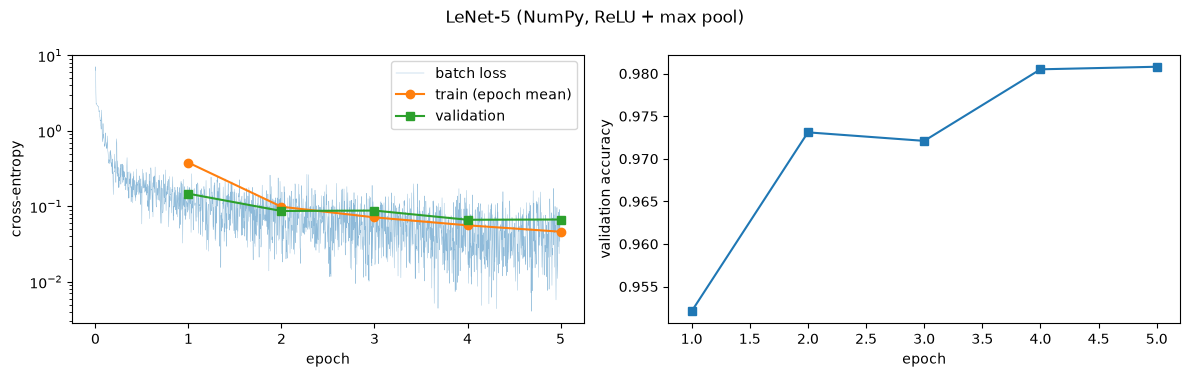

In [15]:
lenet_np = LeNetNumpy(
    activation="relu", pool="max", init="he", lr=0.05, n_epochs=5, seed=0
)
lenet_np.fit(X_tr, y_tr, X_va, y_va)
val_table.loc["LeNet relu/max (scratch)"] = val_scores(lenet_np.predict_proba(X_va))
display(val_table)
print(
    "✅ validation accuracy 應 > 0.975（參考：約 0.98；SGD 的 val loss 在前幾個 epoch 會上下跳，不一定每個 epoch 都進步）"
)

ep = np.arange(1, lenet_np.n_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bl = np.array(lenet_np.history_["batch_loss"])
steps_per_epoch = len(bl) / len(ep)
axes[0].plot(
    np.arange(len(bl)) / steps_per_epoch, bl, lw=0.3, alpha=0.5, label="batch loss"
)
axes[0].plot(ep, lenet_np.history_["train_loss"], "o-", label="train (epoch mean)")
axes[0].plot(ep, lenet_np.history_["val_loss"], "s-", label="validation")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy")
axes[0].legend()
axes[1].plot(ep, lenet_np.history_["val_acc"], "s-")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation accuracy")
fig.suptitle("LeNet-5 (NumPy, ReLU + max pool)")
fig.tight_layout()
plt.show()

In [16]:
# 每一層的參數量、計算量與時間（同一個 batch 128 筆，重複 5 次取平均）
Xb, yb = X_tr[:128], y_tr[:128]
n_b, reps = len(Xb), 5
inputs = [Xb]
for layer in lenet_np.layers_:  # 先跑一次 forward，記下每一層的輸入
    inputs.append(layer.forward(inputs[-1]))
douts = [None] * len(lenet_np.layers_)
lenet_np.loss_fn_.forward(inputs[-1], yb)
g = lenet_np.loss_fn_.backward()
for j in reversed(
    range(len(lenet_np.layers_))
):  # 再跑一次 backward，記下每一層收到的 dout
    douts[j] = g
    g = lenet_np.layers_[j].backward(g)

rows = []
for j, (name, layer) in enumerate(zip(lenet_np.names_, lenet_np.layers_)):
    t0 = time.perf_counter()
    for _ in range(reps):
        layer.forward(inputs[j])
    t_f = (time.perf_counter() - t0) / reps
    t0 = time.perf_counter()
    for _ in range(reps):
        layer.backward(douts[j])
    t_b = (time.perf_counter() - t0) / reps
    if isinstance(layer, Conv2d):
        F_, C_, k_, _ = layer.params["W"].shape
        macs = (
            n_b * F_ * inputs[j + 1].shape[2] ** 2 * C_ * k_ * k_
        )  # n · F · S_out² · C · k²
    elif isinstance(layer, Linear):
        macs = n_b * layer.params["W"].size  # n · d_in · d_out
    else:
        macs = 0
    rows.append(
        {
            "layer": name,
            "params": sum(v.size for v in layer.params.values()),
            "forward MACs / image": macs // n_b,
            "forward ms": round(t_f * 1e3, 2),
            "backward ms": round(t_b * 1e3, 2),
        }
    )
cost = pd.DataFrame(rows).set_index("layer")
cost.loc["total"] = cost.sum()
display(cost)
print("MLP（1024 → 512 → 10）對照：參數 529,930、每張影像 529,408 次乘加")

,params,forward MACs / image,forward ms,backward ms
layer,,,,
conv1,156,117600,2.17,10.16
act1,0,0,0.47,0.34
pool1,0,0,5.95,2.17
conv2,2416,240000,1.38,7.53
act2,0,0,0.16,0.12
pool2,0,0,2.03,0.70
flatten,0,0,0.00,0.00
fc1,48120,48000,0.02,0.04
act3,0,0,0.01,0.01


MLP（1024 → 512 → 10）對照：參數 529,930、每張影像 529,408 次乘加


### TODO 11（問答）訓練結果與計算成本

> **(1)** 訓練結果
>
> **(a)** 5 個 epoch 後 LeNet 的 validation accuracy 與 log loss 是多少？跟第 2 節調參過的 MLP（15 個 epoch）比呢？（第 4 節的 PyTorch 版會訓練更久，再比一次）

validation accuracy = 0.9800、log loss = 0.0684，與 MLP 512 相比差不多。

✓。MLP 是 0.9816／0.0670，差距 0.0016 跟 accuracy 的標準誤差（約 0.0014，TODO 2 (1)）同一個量級，確實分不出好壞。值得注意的是條件差很多：LeNet 只有 **1/8.6 的參數**、只訓練 **5 個 epoch**、**完全沒調參**（lr 也只是隨手選的 0.05），MLP 則是第 1 課調參後的最佳設定、訓練 15 個 epoch。

> **(b)** 用 TODO 10 的參數量：LeNet 的參數只有 MLP 的幾分之一，卻只用 5 個 epoch、沒調參就接近（或超過）MLP。從「模型的假設」解釋：LeNet 事先「知道」了哪些 MLP 必須從資料中自己學的事？（對照 TODO 1 (1)(2) 的觀察）

LeNet 知道了相對位置關係，但也不對，MLP 就算學了也沒有相對位置的概念。

方向 ✓（「相對位置關係」），但說得不夠完整；後半句要修正。LeNet 在**看到任何資料之前**，結構就內建了三個假設（稱為**歸納偏置**，inductive bias）：

| 設計 | 內建的假設 | 對應的觀察 | MLP 要怎麼學到同一件事 |
| --- | --- | --- | --- |
| **局部連接** | 有用的特徵來自相鄰的一小塊像素 | TODO 1 (2)：相關係數在 4–5 格內明顯大於 0，之後趨近 0 | 1024 個像素全部連上，從資料中慢慢學到「遠處的像素幾乎無關」 |
| **權重共享** | 同一種圖樣（一段斜線）出現在哪裡都一樣 | TODO 1 (1)：平移 2–3 格後，在像素空間就不像自己了 | 每個位置用不同的權重，同一段斜線在每個位置都要**分別**學一次 |
| **池化** | 特徵往旁邊挪 1 格，意義不變 | （3D 的實驗） | 同上，只能靠大量資料涵蓋各種位置 |

- **修正**「MLP 就算學了也沒有相對位置的概念」：不完全對。MLP 的函數集合包含 LeNet 能表示的所有函數（卷積是一種特別的線性層：大部分權重固定為 0、其餘權重彼此相等），所以理論上它**學得到**相鄰關係。差別在於 MLP 沒有內建這些假設，必須從資料中**自己發現**、而且每個位置各自發現一次，需要更多資料與訓練。LeNet 則是**事先假設好**，把要學的東西縮小到 61,706 個參數。
- 所以「參數少卻一樣好」不是因為 LeNet 比較聰明，而是**假設剛好對 MNIST 成立**。假設不成立時（打亂像素），這個優勢就會變成限制 —— 第 7 節驗證，也呼應 TODO 2 (2)(a) 的預測。

> **(2)** 參數量 ≠ 計算量：讀上面的成本表
>
> **(a)** 參數最多的是哪一層？乘加次數（MACs，multiply-accumulate）最多的是哪一層？

參數最多的層發生在全連接層，MACs 最多的是 conv2。

✓。精確：參數最多的是 **fc1**（48,120）；每張影像乘加次數最多的是 **conv2**（240,000），其次是 conv1（117,600）。兩層卷積合計 357,600 次，佔全部 416,520 次的 86%，但參數只佔 4.2% —— 正好跟參數的分布相反。

> **(b)** conv1 只有 156 個參數，為什麼乘加次數這麼多？（提示：每個權重在一張影像上被用了幾次？TODO 4 (1)(d)）fc1 的參數有 48,120 個，每張影像的乘加次數是 48,000，為什麼兩者幾乎相等？

每個權重在一張影像上被用了 $28 \times 28$ 次；第二個小題沒看懂問題。

- 第一小題 ✓：conv1 的 150 個權重，每個在 784 個位置各用一次：$150 \times 784 = 117{,}600$，正好是表中的 MACs（偏差是加法，不算乘加）。
- **修正（題目）**：原題寫「fc1 的乘加次數也是 48,120」是錯的，表中是 **48,000**，題目已更正如上。
- **補寫**（第二小題）：Linear 的 $\text{out}_k = \sum_j x_j W_{jk} + b_k$，**每個權重 $W_{jk}$ 在一張影像上只用一次**（輸入 $j$ 乘到輸出 $k$，就這一次），所以乘加次數 = 權重個數 = $400 \times 120 = 48{,}000$；參數 48,120 多出來的 120 個是偏差（只做加法）。
- 一句話對照：**MACs ≈ 權重個數 × 每個權重被用幾次**。Linear 每個權重用 1 次，所以 MACs ≈ 參數量；卷積每個權重用 $S_\text{out}^2$ 次（conv1：784、conv2：100），所以參數少、計算多。

> **(c)** 由 (b)：權重共享讓「參數量」與「計算量」脫鉤了。這對記憶體（要存的參數）與訓練時間各有什麼影響？

參數量變少，要記憶的參數就更少了，權重也變少，訓練時間會加快。

- 記憶體 ✓：參數少，要存的權重（以及它們的梯度、優化器狀態）就少。
- **修正**「訓練時間會加快」：時間主要由**計算量（MACs）**決定，不是參數量。這正是「脫鉤」的意思：
  - LeNet 的參數是 MLP 的 1/8.6，但每張影像的乘加次數是 416,520，跟 MLP 的 529,408 **同一個量級** —— 計算量幾乎沒有少。
  - 而且卷積的運算比單純的矩陣乘法難做得有效率（要取滑動視窗、記憶體不連續），所以手寫 NumPy 版每個 epoch 反而比 MLP 慢。
- 參數量真正影響的是：記憶體、需要多少資料才學得好（參數越少越不容易過擬合）、以及模型檔案大小。計算量影響的是訓練與推論的時間。之後設計 CNN 時兩者要分開考慮（例如 MobileNet 專門降低計算量）。

> **(3)** 時間
>
> **(a)** 哪一層的 backward 最花時間？conv 的 backward 時間大約是 forward 的幾倍？

花最多時間的 backward 是 conv1，total backward 的時間大約是 forward 的 $21.76 / 73.58 \approx 0.2957$ 倍。

- conv1 ✓：它的特徵圖最大（28×28），dX、dW 都要處理最大的陣列。
- **修正**（量測本身有問題）：第一次的成本表 forward 合計 73.93 ms、backward 21.63 ms，forward 反而比 backward 慢 3.4 倍，其中 conv2 的 forward 高達 48.55 ms。原因是跑成本表時，`lenet_np` 還是用**舊的** `Conv2d` 建立的：TODO 5 的 einsum 當時沒有 `optimize=True`，走的是 C 的巢狀迴圈，沒有轉成矩陣乘法。（只重跑 class 那格不夠，已經建好的物件仍用舊的程式碼，要從 class 那格往下重跑。）
  - 判斷依據：沒有 `optimize` 時時間跟乘加次數成正比，conv2（24 萬次）÷ conv1（11.8 萬次）約 2.6 倍，表中正好是 2.8 倍；有 `optimize` 時 conv2 反而比 conv1 快（特徵圖小，要複製的視窗資料少）。
- 重跑後的數字（M4 Pro）：

| 層 | forward ms | backward ms | backward ÷ forward |
| --- | --- | --- | --- |
| conv1 | 3.32 | 10.58 | **3.2 倍** |
| conv2 | 1.42 | 7.68 | **5.4 倍** |
| 全部合計 | 13.12 | 21.68 | 1.65 倍 |

  卷積層的 backward 是 forward 的 3–5 倍，遠大於第 1 課的理論值 2（理由見 (3)(b)）。合計只有 1.65 倍，是因為池化層的 forward 反而比 backward 慢（pool1：5.74 → 2.16 ms，MaxPool 的 forward 要 transpose、argmax、建 mask）。
- **補充**（呼應 (2)(c)）：同樣 24 萬次乘加，conv2 的 forward 從 48.55 ms 降到 1.42 ms，**差 34 倍**，只差在有沒有轉成矩陣乘法。時間不只看計算量，也看運算的實作方式能不能用上硬體（BLAS、多核心、SIMD）。

> **(b)** 第 1 課的結論是 backward 的乘加次數約為 forward 的 2 倍（每層兩次矩陣乘法：dW 與 dX）。`Conv2d.backward` 的 dX 用了 $k^2 = 25$ 次小的 einsum（TODO 7 的迴圈），跟 forward 的一個大 einsum 比，為什麼實際時間的比例可能遠大於 2？（提示：第 1 課 TODO 8 (3)：小運算的固定開銷）

實際上要花在記憶體配置、初始化等等時間的開銷，逐漸累積實際上可能會比一個大的 einsum 還要多。

✓ 方向正確。具體來說，dX 的 25 次迴圈每一次都要付一次固定成本：

- Python 迴圈本身、呼叫 `np.einsum`、解析下標字串、規劃運算順序（`optimize=True` 也要花時間）。
- 每次都**配置一個新的暫存陣列**存 einsum 的結果，再用 `+=` 寫進 `dX` 的切片；切片在記憶體裡不連續，寫入比連續的陣列慢。
- 每次運算都很小（例如 conv2 只有 $F = 16$、$C = 6$），矩陣乘法函式庫吃不滿 CPU 的多核心與 SIMD，效率遠低於 forward 的一次大運算。
- 此外 dW 的 einsum 作用在 6 維的滑動視窗視圖上，NumPy 要先把它**複製**成連續的大矩陣（im2col）才能做矩陣乘法，這也是額外的記憶體與時間成本。

**補充**：conv1 的 $\partial L/\partial X$ 其實完全用不到（輸入影像不需要梯度），它的 dX 迴圈可以省掉（第 1 課 TODO 8 也提過「第一層的 $\partial L/\partial X$ 不需要算」）。PyTorch 會自動跳過不需要梯度的計算。

### 3D. 實驗：平移等變性與不變性

兩個容易混淆的名詞（$T$ = 把影像平移幾格的操作，$f$ = 網路的某一段）：

| 名詞 | 定義 | 白話 |
| --- | --- | --- |
| **等變性**（equivariance） | $f(T x) = T f(x)$ | 輸入平移，輸出**跟著平移**（特徵圖上的反應換了位置，但長一樣） |
| **不變性**（invariance） | $f(T x) = f(x)$ | 輸入平移，輸出**完全不變** |

實驗 1：卷積層是否等變？比較 $\text{conv1}(T x)$ 的第 $s$ 欄與 $\text{conv1}(x)$ 的第 $s - d$ 欄（$T$ = 往右平移 $d$ 格）。
實驗 2：每一層的表示有多「不變」？比較 $f(x)$ 與 $f(Tx)$ 的餘弦相似度（只看數值，不對齊位置）；越接近 1 越不變。
平移用第 1 節的 `shift_right`（空出來的欄補背景值 `BG`）。

In [17]:
x_eq = X_va[:200]  # (200, 1, 32, 32)
conv1 = lenet_np.layers_[0]


def until_pool1(X: np.ndarray) -> np.ndarray:
    """conv1 → act1 → pool1 的輸出。"""
    for layer in lenet_np.layers_[:3]:
        X = layer.forward(X)
    return X


print("實驗 1：等變性的相對誤差（只比較兩邊都有定義的欄）")
for d in [1, 2, 3]:
    a = conv1.forward(shift_right(x_eq, d, fill=BG))  # f(Tx)
    b_ = conv1.forward(x_eq)  # f(x)
    err_conv = np.linalg.norm(a[..., d:] - b_[..., :-d]) / np.linalg.norm(b_[..., :-d])
    # pool1 的輸出邊長只有 conv1 的一半：輸入平移 d 格 → 試著對齊平移 m = d/2 附近的格數，取誤差最小的
    pa, pb = until_pool1(shift_right(x_eq, d, fill=BG)), until_pool1(x_eq)
    err_pool = min(
        np.linalg.norm(pa[..., m:] - pb[..., : pb.shape[-1] - m]) / np.linalg.norm(pb[..., : pb.shape[-1] - m])
        for m in {d // 2, (d + 1) // 2}
    )
    print(f"  平移 {d} 格：conv1 {err_conv:.1e}   pool1 {err_pool:.3f}")

# 實驗 2：每一層的表示，平移前後的餘弦相似度（500 張驗證影像的平均）
x_inv = X_va[:500]
stages = ["input", "act1", "pool1", "act2", "pool2", "act3", "act4"]
f0 = lenet_np.features(x_inv)
f0["input"] = x_inv * MNIST_STD + MNIST_MEAN  # 輸入換回 0–1 強度（背景 = 0），跟第 1 節一樣
inv = {}
for d in [1, 2, 3, 4]:
    xs = shift_right(x_inv, d, fill=BG)
    fd = lenet_np.features(xs)
    fd["input"] = xs * MNIST_STD + MNIST_MEAN
    inv[f"shift {d}"] = {st: cosine_rows(f0[st], fd[st]).mean() for st in stages}
    inv[f"shift {d}"]["same prediction"] = (fd["fc3"].argmax(1) == f0["fc3"].argmax(1)).mean()
inv_table = pd.DataFrame(inv).round(3)
display(inv_table)

實驗 1：等變性的相對誤差（只比較兩邊都有定義的欄）
  平移 1 格：conv1 0.0e+00   pool1 0.422
  平移 2 格：conv1 0.0e+00   pool1 0.000
  平移 3 格：conv1 0.0e+00   pool1 0.422


,shift 1,shift 2,shift 3,shift 4
input,0.817,0.553,0.379,0.291
act1,0.834,0.577,0.401,0.312
pool1,0.903,0.725,0.551,0.428
act2,0.891,0.694,0.509,0.377
pool2,0.938,0.842,0.722,0.594
act3,0.956,0.888,0.807,0.715
act4,0.963,0.903,0.827,0.736
same prediction,0.988,0.936,0.832,0.532


### TODO 12（問答）等變性與不變性

> **(1)** 實驗 1
>
> **(a)** conv1 的等變性誤差是多少（數量級）？這代表卷積層有什麼性質？

conv1 的等變性誤差數量級是 0.0e+00，表示卷積層具有等變性。

✓。誤差是**剛好 0**（不只是很小）：輸入平移幾格，conv1 的輸出就跟著平移幾格，數值完全相同。

> **(b)** 用 forward 的公式說明為什麼：輸入整體往右移 $d$ 格，$X'[i, c, r, s] = X[i, c, r, s-d]$。代入 $\text{out}'[i, f, r, s] = \sum_c\sum_p\sum_q X'[i, c, r+p, s+q]\,W[f, c, p, q] + b[f]$，它等於 out 的哪一格？推導中用到了「每個位置用同一組 $W$、$b$」—— 這是哪個設計？如果每個位置的權重不同（局部連接但不共享），還成立嗎？

不懂。

**補寫**（用最小例子）：一維、單通道，$x = [0, 1, 2, 0, 0]$、濾波器 $w = [1, -1]$（左減右），$\text{out}[s] = x[s]\,w[0] + x[s+1]\,w[1]$：

| | 輸入 | 輸出（長度 $5 - 2 + 1 = 4$） |
| --- | --- | --- |
| 原圖 | $x = [0, 1, 2, 0, 0]$ | $\text{out} = [0-1,\ 1-2,\ 2-0,\ 0-0] = [-1, -1, 2, 0]$ |
| 右移 1 格 | $x' = [0, 0, 1, 2, 0]$ | $\text{out}' = [0-0,\ 0-1,\ 1-2,\ 2-0] = [0, -1, -1, 2]$ |

$\text{out}'$ 正是 $\text{out}$ 右移 1 格：$\text{out}'[s] = \text{out}[s-1]$。

一般推導（只寫一維、省略 $i, c, f$）：
$$\text{out}'[s] = \sum_q x'[s+q]\,w[q] = \sum_q x[s+q-d]\,w[q] = \sum_q x[(s-d)+q]\,w[q] = \text{out}[s-d]$$

- 第二個等號用了平移的定義 $x'[t] = x[t-d]$；第三個等號只是把 $s+q-d$ 寫成 $(s-d)+q$。
- 最後一個等號成立，是因為**位置 $s$ 和位置 $s-d$ 用的是同一個 $w$** —— 這就是**權重共享**。
- 如果不共享（每個位置有自己的 $w_s$）：$\text{out}'[s] = \sum_q x[(s-d)+q]\,w_s[q]$，而 $\text{out}[s-d] = \sum_q x[(s-d)+q]\,w_{s-d}[q]$。兩者用的濾波器不同（$w_s \ne w_{s-d}$），就**不相等**了。
- 所以：**權重共享 ⇒ 平移等變性**。同一個「斜線偵測器」在每個位置都一樣，斜線移到哪裡，反應就出現在哪裡。

> **(c)** 經過 pool1 之後：平移 2 格時誤差是多少？平移 1、3 格呢？為什麼「偶數格」可以完全對齊、奇數格不行？（提示：2×2、stride 2 的小塊格線是固定的；平移 1 格時，原本在同一個小塊的兩格被拆到哪裡？）

經過 2 格誤差 0.00，經過 1、3 格誤差都是 0.422，因為 pool 的倍數是 2 的倍數，剛好可以完整地跳到下一格，但奇數格就會有一半留在原來的格子，另一半跳到下一個格子。

✓ 解釋正確。精確說法：池化的 2×2 格線**固定不動**（第 0–1 欄一塊、第 2–3 欄一塊……）。

- 平移 2 格：每個小塊的兩欄整個搬進下一個小塊，小塊的內容完全不變，只是換了位置 → pool1 的輸出剛好平移 1 格（誤差 0）。
- 平移 1 格：原本同一塊的兩欄被拆開，一欄留下、一欄跑到下一塊，每個小塊裡的組合都變了 → 最大值（或平均值）改變，無法用平移對齊。
- 結論：**stride 2 的池化會破壞「完全的」平移等變性**，只有平移 stride 的倍數時才保持。

> **(2)** 實驗 2
>
> **(a)** 讀表格：平移 2 格時，input、act1、pool1、pool2、act4 的餘弦相似度各是多少？從輸入到深層，有什麼趨勢？

分別為 0.553、0.577、0.725、0.842、0.903。從輸入到深層，輸入偏移越多越不像，但隨著進入深層，平移帶來的影響越來越小。

✓。補充一個細節：相似度不是每一層都上升 —— act2（conv2 之後）會比 pool1 **下降**（驗證時 0.694 < 0.725），經過 pool2 才又上升。卷積層只有等變性（反應換了位置，不對齊時相似度會掉），**上升主要發生在池化層**之後與全連接層。

> **(b)** 「預測不變的比例」（same prediction）在平移 1–4 格時各是多少？

分別為 0.988、0.936、0.832、0.532。

✓。對照 TODO 2 (2)(b) 的預測「LeNet 平移後應該會變低」：平移 1–2 格幾乎不受影響，3 格以後才明顯下降。MLP 的對照在第 7 節。

> **(c)** 卷積層本身只有等變性（反應換了位置），為什麼越深層的表示越接近不變？（提示：池化把小範圍內的位置資訊「丟掉」；深層的一個單元，看到的輸入範圍（感受野）有多大？pool2 的一格對應到輸入的幾×幾？）

不知道。

**補寫**：兩個機制一起作用。

1. **池化丟掉小範圍內的位置資訊**：最大池化只回報「這個 2×2 裡有沒有這個特徵」，不管特徵在 4 格中的哪一格。所以特徵在小塊內移動，輸出不變。每經過一次池化，「位置的解析度」就粗一倍。
2. **感受野越來越大**：深層一個單元「看到」的輸入範圍（感受野，receptive field）一路變大。從 pool2 的一格往回推：

| 層 | 一格對應的範圍 | 怎麼來的 |
| --- | --- | --- |
| pool2 | conv2 的 2×2 | 2×2 池化 |
| conv2 | pool1 的 $2 + 5 - 1 = 6$，即 6×6 | 2 個相鄰位置、各看 5×5 |
| pool1 | conv1 的 12×12 | 每格對應 2×2 |
| conv1 | 輸入的 $12 + 5 - 1 = 16$，即 **16×16** | 各看 5×5 |

  pool2 的一格看到輸入的 16×16（數字本身只有約 20×20），而輸入平移 4 格，在 pool2 上只移動 $4/4 = 1$ 格（兩次池化各除以 2）。所以平移 2 格只是 pool2 上「半格」的變化，大部分特徵仍落在同一格裡。

3. 最後的全連接層把**所有位置**的特徵加權組合起來，進一步淡化「在哪一格」的差別。

> **(d)** 平移 4 格時預測還有沒有完全不變？LeNet 的不變性是「天生完整的」還是「部分、近似的」？要更不變還能怎麼做？（第 5 節）

平移 4 格時預測變了，不變性是部分近似的。要更不變的話，可能要用 scale 更大的卷積記住更多細節。

- 前兩句 ✓：平移 4 格時只有 53% 的預測不變。不變性是**部分、近似**的：只有池化帶來的小範圍不變，而且像 (1)(c) 那樣，還會受「平移幾格」對不對得上池化格線影響。
- **修正**（怎麼更不變）：方向反了。不變性來自**丟掉**位置細節，不是記住更多細節。可行的做法：
  - **資料增強**（第 5 節 5C）：訓練時隨機平移、旋轉影像，讓模型從資料中學到「平移後還是同一個數字」。
  - **更多池化／更大的下採樣**：網路越深、池化越多，位置解析度越粗，不變的範圍越大。之後的 CNN 在最後用 **global average pooling**（把整張特徵圖平均成一個數），完全不管特徵在哪裡（第三章）。
  - 較大的卷積核確實會讓感受野變大，但它本身只提供等變性，不會讓表示變得不變。

---
## 4. 套件實作：PyTorch

### 前置複習：PyTorch 的卷積相關物件

第 1 課已經介紹過 `Tensor`、`nn.Module`、`nn.Sequential`、autograd、`optim.SGD`。這一節新增的物件，跟 3A–3C 的手寫版一一對應：

| 手寫 NumPy | PyTorch | 說明 |
| --- | --- | --- |
| `Conv2d(c_in, c_out, k)` | `nn.Conv2d(c_in, c_out, k)` | `.weight` 的 shape 是 $(F, C, k, k)$、`.bias` 是 $(F,)$ —— **跟我們完全相同，不用轉置**（`nn.Linear` 才需要轉置）。同樣是不翻轉的互相關 |
| 自己補邊再進 conv | `nn.Conv2d(..., padding=2)` | 在每一層內部四周補 0（注意：補的是 0，不一定是背景值，見 TODO 1 (3)） |
| `MaxPool2d()`、`AvgPool2d()` | `nn.MaxPool2d(2)`、`nn.AvgPool2d(2)` | 參數 2 是小塊的邊長（stride 預設等於它） |
| `Flatten()` | `nn.Flatten()` | 從第 1 軸開始攤平，順序同 `reshape`：$(n, C, S, S) \to (n, C\cdot S\cdot S)$ |
| `ReLU()`、`Tanh()` | `nn.ReLU()`、`nn.Tanh()` | |

輸入的 shape 一律是 $(n, C, H, W)$（NCHW），跟我們的慣例相同，所以 `X_tr` 可以直接用。

結構圖（`net = make_lenet()`）：

```
net = nn.Sequential(...)                      ← 跟 LeNetNumpy.layers_ 同樣的 12 層、同樣的順序
├── net[0] ：nn.Conv2d(1, 6, 5)     .weight (6, 1, 5, 5)、.bias (6,)
├── net[1] ：激活   net[2]：池化
├── net[3] ：nn.Conv2d(6, 16, 5)    .weight (16, 6, 5, 5)、.bias (16,)
├── net[4] ：激活   net[5]：池化
├── net[6] ：nn.Flatten()
├── net[7] ：nn.Linear(400, 120)    .weight (120, 400)（轉置！）
├── net[8] ：激活
├── net[9] ：nn.Linear(120, 84)
├── net[10]：激活
└── net[11]：nn.Linear(84, 10)
```

In [18]:
def make_lenet(
    activation: Activation = "relu",
    pool: Pooling = "max",
    channels: tuple[int, int] = (6, 16),
    n_classes: int = 10,
) -> nn.Sequential:
    """跟 LeNetNumpy 同結構的 PyTorch 模型（輸入 1×32×32）。權重用 PyTorch 預設的初始化。

    channels = 兩個卷積層的輸出通道數；預設 (6, 16) 就是 LeNet-5（第 5 節會調整寬度）。
    """
    Act = {"relu": nn.ReLU, "tanh": nn.Tanh}[activation]
    Pool = {"max": nn.MaxPool2d, "avg": nn.AvgPool2d}[pool]
    c1, c2 = channels
    # TODO 13（程式）：回傳 nn.Sequential(...)，12 層，順序與 LeNetNumpy.names_ 相同：
    #   conv1, act1, pool1, conv2, act2, pool2, flatten, fc1, act3, fc2, act4, fc3
    #   - 卷積：nn.Conv2d(輸入通道, 輸出通道, 5)；第一層的輸入通道是 1
    #   - 激活：Act()；池化：Pool(2)（每次都要建立新的物件，不要重複使用同一個）
    #   - fc1 的輸入維度 = pool2 輸出的元素個數：c2 × ? × ?（TODO 10 的表）
    #   - 隱藏層 120、84，輸出 n_classes
    #   常見錯誤：最後一層 Linear 之後不要接激活函數，也不要接 softmax（CrossEntropyLoss 內部會做）
    net = nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=channels[0], kernel_size=5),
        Act(),
        Pool(kernel_size=2),
        nn.Conv2d(in_channels=channels[0], out_channels=channels[1], kernel_size=5),
        Act(),
        Pool(kernel_size=2),
        nn.Flatten(),
        nn.Linear(c2 * 5 * 5, 120),
        Act(),
        nn.Linear(120, 84),
        Act(),
        nn.Linear(84, n_classes),
    )
    return net


print(make_lenet())
print("參數量：", count_parameters(make_lenet()), "（應為 61,706，與 LeNetNumpy 相同）")

# 參數量對了不代表 shape 對：池化沒有參數、Linear 的輸入維度又是寫死的，就算池化大小錯了，參數量也照樣一樣。
# 真的跑一次 forward，印出每一層之後的 shape（對照 TODO 10 的表）
x_check = torch.zeros(2, 1, 32, 32)
print("\n每一層之後的 shape（batch = 2）：")
for name, layer in zip(["conv1", "act1", "pool1", "conv2", "act2", "pool2", "flatten", "fc1", "act3", "fc2", "act4", "fc3"], make_lenet()):
    x_check = layer(x_check)
    print(f"  {name:8s} {tuple(x_check.shape)}")
print("✅ 應依序為 (2, 6, 28, 28)、…、(2, 6, 14, 14)、(2, 16, 10, 10)、…、(2, 16, 5, 5)、(2, 400)、(2, 120)、…、(2, 10)")
print("✅ 寬度加倍也要能跑：", tuple(make_lenet(channels=(12, 32))(torch.zeros(2, 1, 32, 32)).shape), "（應為 (2, 10)）")

Sequential(
  (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=400, out_features=120, bias=True)
  (8): ReLU()
  (9): Linear(in_features=120, out_features=84, bias=True)
  (10): ReLU()
  (11): Linear(in_features=84, out_features=10, bias=True)
)
參數量： 61706 （應為 61,706，與 LeNetNumpy 相同）

每一層之後的 shape（batch = 2）：
  conv1    (2, 6, 28, 28)
  act1     (2, 6, 28, 28)
  pool1    (2, 6, 14, 14)
  conv2    (2, 16, 10, 10)
  act2     (2, 16, 10, 10)
  pool2    (2, 16, 5, 5)
  flatten  (2, 400)
  fc1      (2, 120)
  act3     (2, 120)
  fc2      (2, 84)
  act4     (2, 84)
  fc3      (2, 10)
✅ 應依序為 (2, 6, 28, 28)、…、(2, 6, 14, 14)、(2, 16, 10, 10)、…、(2, 16, 5, 5)、(2, 400)、(2, 120)、…、(2, 10

#### 核對：手寫的反向傳播 = PyTorch autograd

把 NumPy 版的權重複製進 PyTorch 模型（卷積層直接複製、`Linear` 要轉置），在 float64、CPU 上比對 logits、loss、每個參數的梯度。
兩種組合都核對：3C 訓練好的 ReLU＋最大池化，以及一個隨機初始化的 tanh＋平均池化。

In [19]:
def load_from_numpy(net: nn.Sequential, model: LeNetNumpy) -> nn.Sequential:
    """把 LeNetNumpy 的權重複製進結構相同的 PyTorch 模型（就地修改 net），回傳 net。"""
    torch_layers = [m for m in net if isinstance(m, (nn.Conv2d, nn.Linear))]
    with torch.no_grad():
        for tl, nl in zip(torch_layers, model.param_layers_, strict=True):
            W = nl.params["W"]
            tl.weight.copy_(
                torch.from_numpy(W if isinstance(tl, nn.Conv2d) else W.T)
            )  # Linear 要轉置
            tl.bias.copy_(torch.from_numpy(nl.params["b"]))
    return net


def compare_with_torch(model: LeNetNumpy, X: np.ndarray, y: np.ndarray) -> None:
    """float64、CPU：比對手寫版與 PyTorch 的 logits、loss、每個參數的梯度。"""
    m64 = LeNetNumpy(
        activation=model.activation, pool=model.pool, dtype=np.float64
    ).build()
    for a, b in zip(m64.param_layers_, model.param_layers_):
        a.params = {k: v.astype(np.float64) for k, v in b.params.items()}
    net64 = load_from_numpy(make_lenet(model.activation, model.pool).double(), m64)

    loss_np = m64.loss_and_grads(X, y)
    logits_np = m64.forward(X)
    logits_t = net64(torch.from_numpy(X))
    loss_t = nn.functional.cross_entropy(logits_t, torch.from_numpy(y))
    loss_t.backward()

    worst = 0.0
    torch_layers = [m for m in net64 if isinstance(m, (nn.Conv2d, nn.Linear))]
    for tl, nl in zip(torch_layers, m64.param_layers_):
        gW = tl.weight.grad.numpy()
        gW = gW if isinstance(tl, nn.Conv2d) else gW.T
        worst = max(
            worst,
            np.abs(gW - nl.grads["W"]).max(),
            np.abs(tl.bias.grad.numpy() - nl.grads["b"]).max(),
        )
    print(
        f"✅ {model.activation}/{model.pool}：logits 差 {np.abs(logits_t.detach().numpy() - logits_np).max():.1e}、"
        f"loss 差 {abs(loss_t.item() - loss_np):.1e}、梯度最大差 {worst:.1e}（都應 < 1e-10）"
    )


Xb64, yb64 = X_va[:64].astype(np.float64), y_va[:64]
compare_with_torch(lenet_np, Xb64, yb64)
compare_with_torch(
    LeNetNumpy(activation="tanh", pool="avg", init="xavier").build(), Xb64, yb64
)

✅ relu/max：logits 差 5.3e-15、loss 差 6.9e-18、梯度最大差 6.5e-16（都應 < 1e-10）
✅ tanh/avg：logits 差 6.7e-16、loss 差 0.0e+00、梯度最大差 3.1e-16（都應 < 1e-10）


#### 用 PyTorch 訓練

訓練迴圈用第 2 節的 `train_torch`（資料一次搬到裝置上，用 `torch.randperm` 切 batch）。

**CPU 還是 GPU（MPS）？** GPU 擅長「很大的運算」；LeNet 很小（每一步只有幾十萬次乘加），每次呼叫 GPU 的固定開銷可能比運算本身還久。
下一格實測兩者每秒能跑幾步，自動選快的那個（之後所有的訓練都用它）。

In [20]:
def sync(dev: torch.device) -> None:
    """等 GPU 把排隊中的運算做完（GPU 是非同步執行的，不等的話量到的時間不準）。"""
    if dev.type == "mps":
        torch.mps.synchronize()
    elif dev.type == "cuda":
        torch.cuda.synchronize()


def steps_per_second(
    dev: torch.device, n_steps: int = 200, batch_size: int = 128
) -> float:
    """在 dev 上重複訓練同一個 batch n_steps 步，回傳每秒步數（前 20 步暖身，不計時）。"""
    set_seed(0)
    net = make_lenet().to(dev)
    opt = torch.optim.SGD(net.parameters(), lr=0.01)
    xb = torch.as_tensor(X_tr[:batch_size], device=dev)
    yb = torch.as_tensor(y_tr[:batch_size], dtype=torch.long, device=dev)
    for i in range(n_steps + 20):
        if i == 20:
            sync(dev)
            t0 = time.perf_counter()
        opt.zero_grad()
        nn.functional.cross_entropy(net(xb), yb).backward()
        opt.step()
    sync(dev)
    return n_steps / (time.perf_counter() - t0)


speeds = {
    str(dev): steps_per_second(dev)
    for dev in {torch.device("cpu"), get_device(verbose=False)}
}
print("每秒訓練步數（batch 128）：", {k: round(v) for k, v in speeds.items()})
device = torch.device(max(speeds, key=speeds.get))
print("之後使用：", device)

每秒訓練步數（batch 128）： {'mps': 465, 'cpu': 45}
之後使用： mps


epoch  1  train_loss 0.5103  val_loss 0.0958  val_acc 0.9692  (0.9s)
epoch  2  train_loss 0.0825  val_loss 0.0942  val_acc 0.9724  (0.9s)
epoch  3  train_loss 0.0563  val_loss 0.0957  val_acc 0.9683  (0.9s)
epoch  4  train_loss 0.0449  val_loss 0.0762  val_acc 0.9775  (0.9s)
epoch  5  train_loss 0.0365  val_loss 0.0564  val_acc 0.9835  (0.9s)
epoch  6  train_loss 0.0292  val_loss 0.0555  val_acc 0.9842  (0.9s)
epoch  7  train_loss 0.0258  val_loss 0.0492  val_acc 0.9864  (0.9s)
epoch  8  train_loss 0.0220  val_loss 0.0493  val_acc 0.9856  (0.9s)
epoch  9  train_loss 0.0182  val_loss 0.0630  val_acc 0.9826  (0.9s)
epoch 10  train_loss 0.0162  val_loss 0.0436  val_acc 0.9883  (0.9s)


,accuracy,log_loss
Dummy prior,0.1124,2.3012
"MLP 512 (PyTorch, ch1 best)",0.9816,0.0670
LeNet relu/max (scratch),0.9808,0.0669
LeNet relu/max (PyTorch),0.9883,0.0436


✅ validation accuracy 應約 0.99


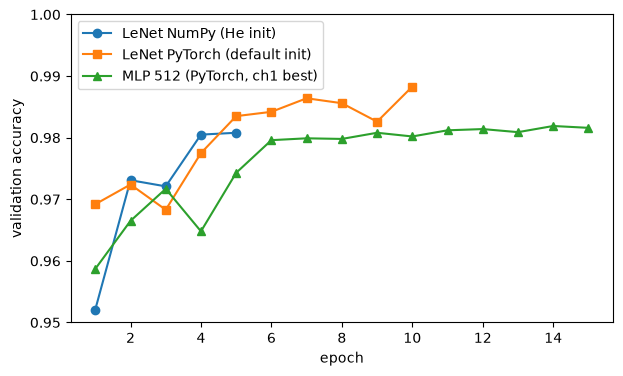

In [21]:
set_seed(0)
net_default = make_lenet("relu", "max")
hist_default = train_torch(net_default, X_tr, y_tr, X_va, y_va, lr=0.1, n_epochs=10)
val_table.loc["LeNet relu/max (PyTorch)"] = val_scores(
    predict_proba_torch(net_default, X_va)
)
display(val_table)
print("✅ validation accuracy 應約 0.99")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    range(1, len(lenet_np.history_["val_acc"]) + 1),
    lenet_np.history_["val_acc"],
    "o-",
    label="LeNet NumPy (He init)",
)
ax.plot(
    range(1, 11), hist_default["val_acc"], "s-", label="LeNet PyTorch (default init)"
)
ax.plot(
    range(1, len(hist_mlp["val_acc"]) + 1),
    hist_mlp["val_acc"],
    "^-",
    label="MLP 512 (PyTorch, ch1 best)",
)
ax.set_xlabel("epoch")
ax.set_ylabel("validation accuracy")
ax.set_ylim(0.95, 1.0)
ax.legend()
plt.show()

#### 實驗：1998 風格（tanh ＋ 平均池化）vs 現代風格（ReLU ＋ 最大池化）

同樣的 lr = 0.1、10 epochs、PyTorch 預設初始化，只換激活函數與池化，共 4 種組合。

,val_acc @ epoch 1,val_acc @ epoch 10,best val_loss,best epoch
tanh + avg,0.9273,0.9820,0.0508,9.0
tanh + max,0.9528,0.9861,0.0429,10.0
relu + avg,0.9429,0.9833,0.0508,7.0
relu + max,0.9692,0.9883,0.0436,10.0


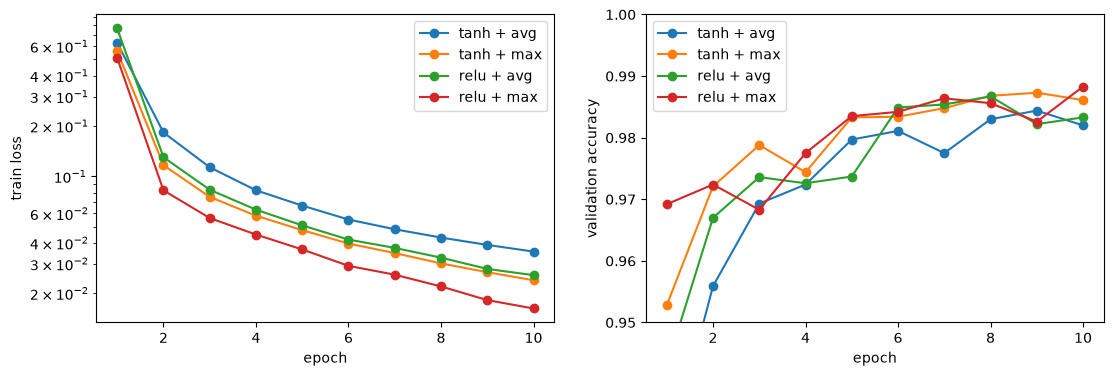

In [22]:
style_hist = {}
for act in ["tanh", "relu"]:
    for pool in ["avg", "max"]:
        set_seed(0)
        net = make_lenet(act, pool)
        style_hist[f"{act} + {pool}"] = train_torch(
            net, X_tr, y_tr, X_va, y_va, lr=0.1, n_epochs=10, verbose=False
        )

display(
    pd.DataFrame(
        {
            name: {
                "val_acc @ epoch 1": h["val_acc"][0],
                "val_acc @ epoch 10": h["val_acc"][-1],
                "best val_loss": h["best_val_loss"],
                "best epoch": h["best_epoch"],
            }
            for name, h in style_hist.items()
        }
    ).T
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in style_hist.items():
    axes[0].plot(range(1, 11), h["train_loss"], "o-", label=name)
    axes[1].plot(range(1, 11), h["val_acc"], "o-", label=name)
axes[0].set_yscale("log")
axes[0].set_ylabel("train loss")
axes[1].set_ylabel("validation accuracy")
axes[1].set_ylim(0.95, 1.0)
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

### 4C. `Dataset`、`DataLoader` 與影像 transform

到目前為止，資料都**一次**搬到裝置上，用 `torch.randperm` 切 batch —— 每個 epoch 看到的影像都一模一樣。
第 5 節的**資料增強**（data augmentation）要在每次取出一張影像時，**隨機**平移、旋轉一點點，每個 epoch 看到的都是新版本。
這種「每一筆各自處理」的工作，標準做法是 `Dataset` ＋ `DataLoader`：

| 物件 | 負責 | 要寫的東西 |
| --- | --- | --- |
| `Dataset` | 「第 $i$ 筆資料是什麼」 | `__len__()`：有幾筆；`__getitem__(i)`：回傳第 $i$ 筆 `(x, y)`（可以在這裡做隨機 transform） |
| `DataLoader(ds, batch_size, shuffle)` | 打亂順序、一次取 `batch_size` 筆、把它們疊成一個 batch | 不用寫，直接用；`for xb, yb in loader:` 每圈拿到一個 batch |
| `torchvision.transforms.v2` | 影像的隨機變換（`RandomAffine`：旋轉、平移、縮放） | 組合好傳給 `Dataset` |

**transform 作用在 uint8 影像上、標準化之前**：`RandomAffine` 平移或旋轉後空出來的角落補 0，在 uint8 裡 0 就是背景（理由同 TODO 1 (3)）。

**macOS ＋ Jupyter 的限制**：`DataLoader(num_workers > 0)` 會開新的行程，在 macOS 上需要重新 import 定義 `Dataset` 的模組；
寫在 notebook 裡的 class 沒辦法這樣被 import，會出錯。所以本章一律 `num_workers=0`（在主行程裡逐筆處理）。

✅ 不做 transform 的 Dataset 與 X_tr 的最大差異： 2.384185791015625e-07 （應 < 1e-6）


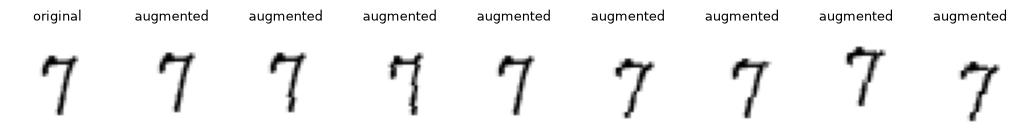

DataLoader, no transform    ：3.3s / epoch
DataLoader + RandomAffine   ：7.1s / epoch
train_torch（資料在裝置上）         ：0.9s / epoch


In [23]:
from torch.utils.data import DataLoader, Dataset
from torchvision import tv_tensors
from torchvision.transforms import v2

X_full_pad_u8 = pad32(X_full_u8)  # (60000, 32, 32) uint8，與 X_full 同順序
X_tr_u8 = X_full_pad_u8[idx_tr]  # (50000, 32, 32)：跟 X_tr 是同樣的影像（還沒標準化）


class MnistPadded(Dataset):
    """補邊後的 uint8 影像 ＋ 標籤。每次取一筆：transform（作用在 uint8 上）→ 標準化 → (float32 (1, 32, 32), 標籤)。"""

    def __init__(
        self, X_u8: np.ndarray, y: np.ndarray, transform: v2.Transform | None = None
    ) -> None:
        self.X = torch.from_numpy(X_u8).unsqueeze(1)  # (n, 1, 32, 32) uint8
        self.y = torch.from_numpy(y).long()  # (n,)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.X[i]  # (1, 32, 32) uint8
        if self.transform is not None:
            x = self.transform(
                tv_tensors.Image(x)
            )  # 標記成「影像」，v2 的 transform 才知道要怎麼處理
        x = (x.as_subclass(torch.Tensor).float() / 255 - MNIST_MEAN) / MNIST_STD
        return x, self.y[i]


def train_loader(
    net: nn.Module,
    loader: DataLoader,
    X_val: np.ndarray | None = None,
    y_val: np.ndarray | None = None,
    *,
    lr: float = 0.1,
    n_epochs: int = 10,
    weight_decay: float = 0.0,
    restore_best: bool = False,
    verbose: bool = True,
) -> dict:
    """跟 train_torch 相同，唯一的差別：batch 由 DataLoader 提供（每個 batch 從 CPU 搬到裝置上）。回傳的 history 格式相同。"""
    net.to(device)
    opt = torch.optim.SGD(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    hist: dict = {"train_loss": [], "val_loss": [], "val_acc": [], "seconds": []}
    best_loss, best_epoch, best_state = np.inf, 0, None
    for epoch in range(n_epochs):
        net.train()
        t0 = time.perf_counter()
        total, count = torch.zeros((), device=device), 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(net(xb), yb)
            loss.backward()
            opt.step()
            total += loss.detach() * len(yb)
            count += len(yb)
        hist["train_loss"].append(total.item() / count)
        msg = f"epoch {epoch + 1:2d}  train_loss {hist['train_loss'][-1]:.4f}"
        if X_val is not None:
            s = val_scores(predict_proba_torch(net, X_val), y_val)
            hist["val_loss"].append(s["log_loss"])
            hist["val_acc"].append(s["accuracy"])
            msg += f"  val_loss {s['log_loss']:.4f}  val_acc {s['accuracy']:.4f}"
            if s["log_loss"] < best_loss:
                best_loss, best_epoch = s["log_loss"], epoch + 1
                best_state = {
                    k: v.detach().clone() for k, v in net.state_dict().items()
                }
        hist["seconds"].append(time.perf_counter() - t0)
        if verbose:
            print(msg + f"  ({hist['seconds'][-1]:.1f}s)")
    hist["best_epoch"], hist["best_val_loss"] = best_epoch, best_loss
    if restore_best and best_state is not None:
        net.load_state_dict(best_state)
    return hist


# 資料增強：最多旋轉 ±10°、平移 ±10%（32 × 0.1 ≈ 3 格）
augment = v2.RandomAffine(degrees=10, translate=(0.1, 0.1))
ds_plain = MnistPadded(X_tr_u8, y_tr)
ds_aug = MnistPadded(X_tr_u8, y_tr, transform=augment)
print(
    "✅ 不做 transform 的 Dataset 與 X_tr 的最大差異：",
    float(np.abs(ds_plain[0][0].numpy() - X_tr[0]).max()),
    "（應 < 1e-6）",
)

# 同一張影像，取 8 次
fig, axes = plt.subplots(1, 9, figsize=(13, 1.8))
axes[0].imshow(ds_plain[0][0][0], cmap="gray_r")
axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(ds_aug[0][0][0], cmap="gray_r")
    ax.set_title("augmented", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

# 一個 epoch 要多久？（同一個模型，只換資料的提供方式）
for name, ds in [
    ("DataLoader, no transform", ds_plain),
    ("DataLoader + RandomAffine", ds_aug),
]:
    set_seed(0)
    loader = DataLoader(
        ds,
        batch_size=128,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(0),
    )
    h = train_loader(
        make_lenet(), loader, X_va, y_va, lr=0.1, n_epochs=1, verbose=False
    )
    print(f"{name:28s}：{h['seconds'][0]:.1f}s / epoch")
print(
    f"{'train_torch（資料在裝置上）':28s}：{np.mean(hist_default['seconds']):.1f}s / epoch"
)

### TODO 14（問答）PyTorch

> **(1)** 核對
>
> **(a)** logits、loss、梯度的差異是多少？兩種組合（relu/max、tanh/avg）都一致嗎？

relu/max：logits 差 5.3e-15、loss 差 6.9e-18、梯度最大差 6.5e-16；tanh/avg：logits 差 6.7e-16、loss 差 0.0e+00、梯度最大差 3.1e-16。

✓。全部在 1e-15 左右，是 float64 的捨入誤差等級 —— 手寫的 `Conv2d`、`AvgPool2d`、`MaxPool2d` 的 forward 與 backward，跟 PyTorch autograd 算出來的完全相同。

> **(b)** 複製權重時，`nn.Conv2d` 不用轉置、`nn.Linear` 要轉置。從兩者的 forward 公式說明原因（`nn.Linear` 算 `X @ weight.T + bias`；`nn.Conv2d` 的 `weight[f, c, p, q]` 在公式裡扮演什麼角色？跟我們的 $W$ 一樣嗎？）

我們是做逐點乘加，所以 dimension 需要對齊，PyTorch 的做法是矩陣相乘再加總，自然需要做轉置的動作。

**修正**：兩邊的數學完全一樣（都是乘加），差別只在**權重存放的軸順序**（慣例），不是計算方式不同。

| | 我們的寫法 | PyTorch | 要不要轉置 |
| --- | --- | --- | --- |
| Linear | `W` 是 $(d_\text{in}, d_\text{out})$，算 `X @ W` | `weight` 是 $(d_\text{out}, d_\text{in})$，算 `X @ weight.T` | 要：同一個權重 $W_{jk}$（輸入 $j$ → 輸出 $k$），在 PyTorch 裡存在 `weight[k, j]` |
| Conv2d | `W[f, c, p, q]` | `weight[f, c, p, q]` | 不用：四個軸的意義、順序都一樣（輸出通道、輸入通道、列、欄） |

PyTorch 的 `nn.Linear` 把「輸出」放第一軸，是為了跟 `nn.Conv2d` 一致（第一軸都是輸出），我們第 1 課則照數學課本 $XW$ 的寫法。判斷要不要轉置，只要問：**同一個權重在兩邊的下標順序一不一樣**。

> **(2)** CPU vs GPU：每秒步數各是多少？選了哪一個？為什麼這麼小的模型 GPU 不一定比較快？（提示：第 1 課 TODO 8 (3) 的「固定開銷」；GPU 每一步還要等 CPU 一個一個送出運算指令）

每秒訓練步數（batch 128）：mps 460、cpu 45。因為還要把模型資料塞進去 GPU，這個時間可能會很長；小模型訓練的過程其實已經很快了，這種初始化的開銷可能耗時更久。

- 數字 ✓：選了 MPS。
- **修正**（先看自己的數字）：在你的 M4 Pro 上，**GPU 快了約 10 倍**，所以這台機器上「GPU 不一定比較快」並沒有發生。題目的前提是我的預測，被你的實驗推翻了 —— 這種時候答案要以數字為準。
- **修正**（開銷的來源）：「把模型和資料搬進 GPU」只做**一次**（`train_torch` 一開始就把整個訓練集放上 GPU），不會每一步都付。每一步要付的固定開銷是 CPU 一個一個送出運算指令（kernel launch）、Python 迴圈本身。
- **補充**（為什麼這裡 GPU 還是贏）：一步的計算量 ≈ 每張影像約 125 萬次乘加（forward 41.7 萬、backward 約兩倍）× 128 張 ≈ 1.6 億次。這已經大到 GPU 的平行運算佔優勢；CPU 版的 PyTorch 卷積在 Mac 上又不夠快（45 步／秒 = 每步 22 ms）。固定開銷佔主導的情況，是模型更小、batch 更小（例如 batch 1）的時候。所以程式用「實測後選快的」，而不是假設 GPU 一定快。

> **(3)** 1998 風格 vs 現代風格（4 種組合的表與圖）
>
> **(a)** 第 1 個 epoch 與第 10 個 epoch 的 validation accuracy，哪一個組合最好、哪一個最差？

第 1 個 epoch 的話 tanh+avg 最差、relu+max 最好；第 10 個的話也是 tanh+avg 最差、relu+max 最好。

✓。數字：

| | epoch 1 | epoch 10 | best val loss |
| --- | --- | --- | --- |
| tanh + avg | **0.9273**（最差） | **0.9820**（最差） | 0.0508 |
| tanh + max | 0.9528 | 0.9861 | **0.0429**（最低） |
| relu + avg | 0.9429 | 0.9833 | 0.0508 |
| relu + max | **0.9692**（最好） | **0.9883**（最好） | 0.0436 |

注意 best val loss 最低的其實是 tanh + max（0.0429，跟 relu + max 的 0.0436 在 seed 雜訊範圍內）。

> **(b)** 單獨換激活函數（tanh → ReLU）與單獨換池化（avg → max），哪一個影響比較大？

換 activation function 差異比較大，從 epoch 1 到 10 可以看到，表現差的都是 tanh 這個激活函數，比較好的都是用 relu 這個激活函數，所以激活函數的影響較大。

**修正**：表上的數字顯示是**池化**的影響比較大。「單獨換一個」的意思是固定另一個不變，從 tanh + avg 出發：

| 改變 | epoch 1 | epoch 10 |
| --- | --- | --- |
| 只換激活（tanh + avg → relu + avg） | 0.927 → 0.943（+1.6） | 0.982 → 0.983（+0.1） |
| 只換池化（tanh + avg → tanh + max） | 0.927 → 0.953（**+2.6**） | 0.982 → 0.986（**+0.4**） |

- 「表現差的都是 tanh」也不成立：epoch 1 時 tanh + max（0.953）比 relu + avg（0.943）好。
- 比較兩個因素時，要讓**一次只變一個**，不能拿「好的那兩組」和「差的那兩組」整體比較，因為每組都同時含有兩個因素。

> **(c)** 從梯度的大小解釋 (a)：tanh 的導數最大是 1，$|z|$ 大的時候趨近 0（飽和）；ReLU 在 $z > 0$ 時導數恆為 1。平均池化的 backward 把上游梯度「除以 4」平均分給 4 格；最大池化把整個梯度交給 1 格。每經過一個平均池化，往回傳的梯度大小會怎樣？LeNet 有兩個池化層。用同一個 lr = 0.1 時，哪一種組合的「有效步伐」比較小？

不知道怎麼解釋。

**補寫**：關鍵是「同一個 lr，梯度越小，每一步實際走得越少」（參數的更新量 = lr × 梯度）。

1. **平均池化把梯度稀釋了**：backward 時每格只拿到 dout/4（3B）。卷積層的 $\partial L/\partial W$ 是「視窗的輸入值 × 收到的梯度」加總（TODO 4 (1)(c)）：
   - 平均池化：4 格各拿 dout/4 → 貢獻 ≈ dout × （4 格輸入的**平均**）。
   - 最大池化：最大的那格拿整個 dout → 貢獻 ≈ dout × （4 格中**最大**的輸入）。
   - 最大值 ≥ 平均值，而 ReLU 之後的特徵圖很多是 0，平均會被 0 拉低更多。所以平均池化讓前面卷積層的梯度變小，而且經過兩個池化層會再縮一次 → conv1 的有效步伐最小。
2. **tanh 的影響比預期小**：PyTorch 預設的初始化權重很小，tanh 的輸入大多落在 0 附近，那裡 tanh ≈ 恆等函數、導數 ≈ 1，跟 ReLU 差不多。所以在這個實驗裡，「激活函數造成梯度變小」的效果不明顯 —— 這正好解釋了 (b) 的數字：池化的影響比激活函數大。
3. 結論：tanh + avg 的組合在同一個 lr 下有效步伐最小，所以**第 1 個 epoch 落後最多**；但它還在往前走，所以第 10 個 epoch 差距縮小到只剩 0.6 個百分點。

> **(d)** 這是否代表 tanh ＋ 平均池化「能力比較差」？如果訓練更久或調大學習率呢？（只要說明想法，不必做）

不一定，激活函數 + pool 的設定必須要測試過才知道。

方向 ✓（不能直接下結論），但可以從表上的證據說得更具體：

- 差距隨訓練**快速縮小**：epoch 1 差 4.2 個百分點，epoch 10 只差 0.6；best val loss 最低的反而是 tanh + max。這代表主要差在**收斂速度**（有效步伐），不是**能力**（能表示的函數）。
- 由 (c)，tanh + avg 的問題是梯度變小。調大學習率可以補回有效步伐，或者訓練更久讓它走完。
- 歷史佐證：1998 年的 LeNet-5 就是用 tanh ＋ 平均池化，在 MNIST 上達到約 0.95% 的測試錯誤率（99.05% 的準確率），跟這裡 ReLU ＋ 最大池化的結果同等級。
- ReLU ＋ 最大池化後來成為主流，主要是因為**更深的網路**裡梯度要穿過幾十層：每層的縮小會一路相乘（第 1 課 TODO 10 的梯度消失）。LeNet 只有 5 層，這個差別還不明顯。

> **(4)** DataLoader
>
> **(a)** 三種資料提供方式，一個 epoch 各要幾秒？DataLoader（不做 transform）比 `train_torch` 慢多少？

每一個 epoch 分別要 2.2 秒、6.7 秒、0.9 秒。

✓。DataLoader（不做 transform）比 `train_torch` 慢約 2.4 倍；加上 `RandomAffine` 後慢約 7.4 倍。

> **(b)** 慢在哪裡？（提示：`__getitem__` 一次只處理一張、用 Python 呼叫 50,000 次；每個 batch 要把逐筆的 tensor 疊起來，再從 CPU 搬到裝置上。`train_torch` 的資料一開始就整批放在裝置上，切 batch 只是一次索引）

逐筆處理的開銷比一次放入然後對索引做切分來得大。

✓。具體來說，每個 epoch 要付：50,000 次 Python 的 `__getitem__` 呼叫（每次各自轉型、標準化）、391 次把 128 個小 tensor 疊成一個 batch（collate）、391 次 CPU → GPU 的搬移。`train_torch` 只在一開始搬一次，之後每個 batch 是 GPU 上的一次索引。RandomAffine 每張影像還要做一次內插運算，所以再慢 3 倍。

> **(c)** 既然比較慢，什麼情況「一定」要用 DataLoader？（提示：每個 epoch 要看到不同的隨機版本；資料大到放不進記憶體、要從硬碟讀）

如果資料量大到可以撐爆記憶體的話，那還是只能用 DataLoader，用時間換空間。

✓（記憶體那一點）。**補充**另一個、也是本章用它的原因：**資料增強**。每一張影像在每個 epoch 都要套一次**新的隨機**變換，沒辦法事先算好放在 GPU 上（要事先算，就得存下「每個 epoch × 每張影像」的版本）。逐筆處理正好讓每次取資料時都能重新抽一次隨機參數。實務上會用 `num_workers > 0` 讓多個行程平行準備資料，把這個成本藏在 GPU 訓練的時間裡（macOS ＋ Jupyter 有限制，見 4C 的說明）。

---
## 5. 調參

全程只用 train／validation（測試集鎖住），依 README「調參流程」。跟第 1 課相同：固定的 validation set、選模型用 **validation loss**、
「平均 ± 標準差」來自換 seed。LeNet 的超參數：

| 類別 | 超參數 | 本節怎麼處理 |
| --- | --- | --- |
| 容量 | 卷積層的通道數（寬度） | 5A：寬度的 validation curve（通道數乘上倍數 $m$） |
| 容量／正則化 | 訓練多少個 epoch | 每個設定都記下 val loss 最低的 epoch（early stopping） |
| 正則化 | `weight_decay` | 5B：與學習率做 2D 搜尋 |
| 正則化 | 資料增強 | 5C：最佳設定加上 `RandomAffine`，比較有沒有幫助 |
| 最佳化 | `lr`、`batch_size` | 5B 搜尋 lr；batch 固定 128；激活與池化固定為 ReLU ＋ 最大池化（第 4 節的結果） |

5D 另外用學習曲線比較 LeNet 與 MLP 需要多少資料。

整節約 15–20 分鐘（M4 Pro）。

,channels,params,sec/epoch,best_epoch,train_loss@best,best_val_loss,val_acc@best
m,,,,,,,
0.5,"(3, 8)",35820,0.8,11,0.0137,0.0546,0.9862
1.0,"(6, 16)",61706,0.9,10,0.0095,0.0436,0.9883
2.0,"(12, 32)",117078,1.3,11,0.0053,0.0365,0.9902
4.0,"(24, 64)",242222,2.4,10,0.0064,0.0372,0.9884


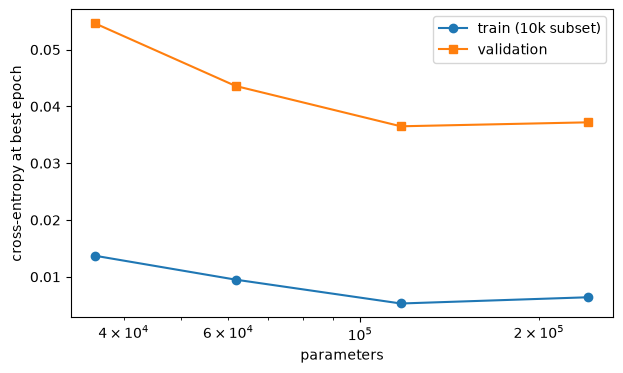

val loss 最低的寬度：m = 2.0 → channels = (12, 32) （TODO 15 (1) 會討論要不要改選較小的）


In [24]:
# 5A. 寬度的 validation curve：channels = (6m, 16m)，lr = 0.1，12 epochs
X_tr_eval, y_tr_eval = X_tr[:10_000], y_tr[:10_000]  # 訓練集分數用其中 10,000 筆估計
width_rows = []
for m in [0.5, 1, 2, 4]:
    ch = (int(6 * m), int(16 * m))
    set_seed(0)
    net = make_lenet(channels=ch)
    h = train_torch(
        net,
        X_tr,
        y_tr,
        X_va,
        y_va,
        lr=0.1,
        n_epochs=12,
        restore_best=True,
        verbose=False,
    )
    tr = val_scores(predict_proba_torch(net, X_tr_eval), y_tr_eval)
    width_rows.append(
        {
            "m": m,
            "channels": ch,
            "params": count_parameters(net),
            "sec/epoch": round(np.mean(h["seconds"]), 1),
            "best_epoch": h["best_epoch"],
            "train_loss@best": tr["log_loss"],
            "best_val_loss": h["best_val_loss"],
            "val_acc@best": h["val_acc"][h["best_epoch"] - 1],
        }
    )
width_df = pd.DataFrame(width_rows).set_index("m")
display(width_df)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    width_df["params"], width_df["train_loss@best"], "o-", label="train (10k subset)"
)
ax.plot(width_df["params"], width_df["best_val_loss"], "s-", label="validation")
ax.set_xscale("log")
ax.set_xlabel("parameters")
ax.set_ylabel("cross-entropy at best epoch")
ax.legend()
plt.show()

WIDTH_MULT = float(width_df["best_val_loss"].idxmin())
CHANNELS = (int(6 * WIDTH_MULT), int(16 * WIDTH_MULT))
print(
    "val loss 最低的寬度：m =",
    WIDTH_MULT,
    "→ channels =",
    CHANNELS,
    "（TODO 15 (1) 會討論要不要改選較小的）",
)

,lr,weight_decay,best_epoch,best_val_loss,val_acc@best,final_val_loss
3,0.10,0.0005,13,0.0330,0.9905,0.0393
5,0.30,0.0005,6,0.0353,0.9895,0.0384
2,0.10,0.0000,11,0.0365,0.9902,0.0392
4,0.30,0.0000,6,0.0405,0.9892,0.1069
1,0.03,0.0005,14,0.0418,0.9883,0.0486
0,0.03,0.0000,14,0.0421,0.9886,0.0480


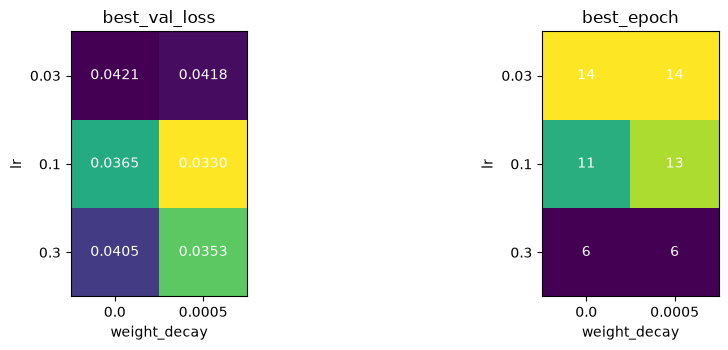

最佳設定： {'lr': 0.1, 'weight_decay': 0.0005, 'best_epoch': 13.0, 'best_val_loss': 0.033, 'val_acc@best': 0.9905, 'final_val_loss': 0.0393}


In [25]:
# 5B. 2D 搜尋：lr × weight_decay（channels = CHANNELS、15 epochs，各設定取 val loss 最低的 epoch）
MAX_EPOCHS = 15
grid_rows, grid_nets = [], {}
for lr in [0.03, 0.1, 0.3]:
    for wd in [0.0, 5e-4]:
        set_seed(0)
        net = make_lenet(channels=CHANNELS)
        h = train_torch(
            net,
            X_tr,
            y_tr,
            X_va,
            y_va,
            lr=lr,
            weight_decay=wd,
            n_epochs=MAX_EPOCHS,
            restore_best=True,
            verbose=False,
        )
        grid_nets[(lr, wd)] = net  # 已換回 best epoch 的權重
        grid_rows.append(
            {
                "lr": lr,
                "weight_decay": wd,
                "best_epoch": h["best_epoch"],
                "best_val_loss": h["best_val_loss"],
                "val_acc@best": h["val_acc"][h["best_epoch"] - 1],
                "final_val_loss": h["val_loss"][-1],
            }
        )
grid = pd.DataFrame(grid_rows)
display(grid.sort_values("best_val_loss"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, fmt in [(axes[0], "best_val_loss", ".4f"), (axes[1], "best_epoch", "d")]:
    pv = grid.pivot(index="lr", columns="weight_decay", values=col)
    im = ax.imshow(pv.values, cmap="viridis_r" if col == "best_val_loss" else "viridis")
    ax.set_xticks(range(pv.shape[1]), pv.columns)
    ax.set_yticks(range(pv.shape[0]), pv.index)
    ax.set_xlabel("weight_decay")
    ax.set_ylabel("lr")
    ax.set_title(col)
    for (r, c), v in np.ndenumerate(pv.values):
        ax.text(
            c,
            r,
            format(int(v) if fmt == "d" else v, fmt),
            ha="center",
            va="center",
            color="w",
        )
fig.tight_layout()
plt.show()

best_cfg = grid.loc[grid["best_val_loss"].idxmin()]
print("最佳設定：", best_cfg.to_dict())

In [26]:
# seed 造成的雜訊：最佳設定換 3 個 seed 重跑
seed_rows = []
for seed in [0, 1, 2]:
    set_seed(seed)
    net = make_lenet(channels=CHANNELS)
    h = train_torch(
        net,
        X_tr,
        y_tr,
        X_va,
        y_va,
        lr=float(best_cfg["lr"]),
        weight_decay=float(best_cfg["weight_decay"]),
        n_epochs=MAX_EPOCHS,
        seed=seed,
        verbose=False,
    )
    seed_rows.append(
        {
            "seed": seed,
            "best_epoch": h["best_epoch"],
            "best_val_loss": h["best_val_loss"],
            "val_acc@best": h["val_acc"][h["best_epoch"] - 1],
        }
    )
seed_df = pd.DataFrame(seed_rows).set_index("seed").astype(float)  # 先轉成 float，下面加入 mean／std 列時才不會有 dtype 警告
seed_df.loc["mean"] = seed_df.mean()
seed_df.loc["std"] = seed_df.iloc[:3].std()
display(seed_df.round(4))

,best_epoch,best_val_loss,val_acc@best
seed,,,
0,13.0000,0.0330,0.9905
1,14.0000,0.0358,0.9905
2,10.0000,0.0375,0.9888
mean,12.3333,0.0354,0.9899
std,2.0817,0.0023,0.0010


In [27]:
# 5C. 資料增強：最佳設定 ＋ RandomAffine（同樣 15 epochs）
set_seed(0)
net_aug = make_lenet(channels=CHANNELS)
loader_aug = DataLoader(
    ds_aug,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(0),
)
hist_aug = train_loader(
    net_aug,
    loader_aug,
    X_va,
    y_va,
    lr=float(best_cfg["lr"]),
    weight_decay=float(best_cfg["weight_decay"]),
    n_epochs=MAX_EPOCHS,
    restore_best=True,
)
net_noaug = grid_nets[(float(best_cfg["lr"]), float(best_cfg["weight_decay"]))]
aug_table = pd.DataFrame(
    {
        "no augmentation": {
            "best_epoch": int(best_cfg["best_epoch"]),
            "best_val_loss": float(best_cfg["best_val_loss"]),
            "val_acc@best": float(best_cfg["val_acc@best"]),
            "train_loss@best (clean 10k)": val_scores(
                predict_proba_torch(net_noaug, X_tr_eval), y_tr_eval
            )["log_loss"],
        },
        "RandomAffine": {
            "best_epoch": hist_aug["best_epoch"],
            "best_val_loss": hist_aug["best_val_loss"],
            "val_acc@best": hist_aug["val_acc"][hist_aug["best_epoch"] - 1],
            "train_loss@best (clean 10k)": val_scores(
                predict_proba_torch(net_aug, X_tr_eval), y_tr_eval
            )["log_loss"],
        },
    }
).T
display(aug_table)
USE_AUG = bool(
    hist_aug["best_val_loss"]
    < float(best_cfg["best_val_loss"]) - float(seed_df.loc["std", "best_val_loss"])
)
print(
    "資料增強的 val loss 改善超過一個 seed 標準差？",
    USE_AUG,
    "→ 第 6 節",
    "使用" if USE_AUG else "不使用",
    "資料增強",
)

epoch  1  train_loss 0.8290  val_loss 0.1016  val_acc 0.9700  (6.8s)
epoch  2  train_loss 0.1485  val_loss 0.0874  val_acc 0.9754  (6.7s)
epoch  3  train_loss 0.1009  val_loss 0.0739  val_acc 0.9771  (6.7s)
epoch  4  train_loss 0.0831  val_loss 0.0486  val_acc 0.9863  (6.7s)
epoch  5  train_loss 0.0705  val_loss 0.0450  val_acc 0.9848  (6.8s)
epoch  6  train_loss 0.0629  val_loss 0.0401  val_acc 0.9882  (6.7s)
epoch  7  train_loss 0.0564  val_loss 0.0402  val_acc 0.9878  (6.7s)
epoch  8  train_loss 0.0524  val_loss 0.0373  val_acc 0.9886  (6.7s)
epoch  9  train_loss 0.0502  val_loss 0.0326  val_acc 0.9903  (6.7s)
epoch 10  train_loss 0.0465  val_loss 0.0338  val_acc 0.9886  (6.7s)
epoch 11  train_loss 0.0439  val_loss 0.0296  val_acc 0.9920  (6.9s)
epoch 12  train_loss 0.0434  val_loss 0.0326  val_acc 0.9901  (6.7s)
epoch 13  train_loss 0.0421  val_loss 0.0326  val_acc 0.9904  (6.7s)
epoch 14  train_loss 0.0394  val_loss 0.0292  val_acc 0.9912  (6.7s)
epoch 15  train_loss 0.0381  val_l

,best_epoch,best_val_loss,val_acc@best,train_loss@best (clean 10k)
no augmentation,13.0,0.0330,0.9905,0.0059
RandomAffine,15.0,0.0291,0.9923,0.0150


資料增強的 val loss 改善超過一個 seed 標準差？ True → 第 6 節 使用 資料增強


model,LeNet,MLP
train size,,
1000,0.9382,0.8928
5000,0.9738,0.9463
50000,0.9905,0.9816


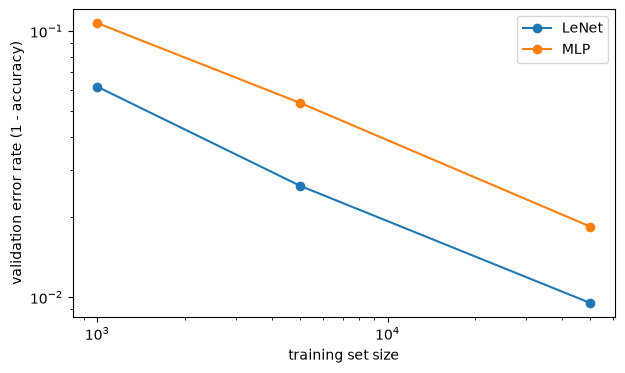

In [28]:
# 5D. 學習曲線：LeNet vs MLP，訓練資料 1,000 ～ 50,000 筆
# 小資料集的 epoch 很短，所以固定「總更新次數」（= 15 epochs × 391 次），而不是固定 epoch 數
budget = MAX_EPOCHS * int(np.ceil(len(X_tr) / 128))
lc_rows = []
for size in [1_000, 5_000, 50_000]:
    epochs = int(np.ceil(budget / np.ceil(size / 128)))
    for name, make, cfg in [
        ("LeNet", lambda: make_lenet(channels=CHANNELS), dict(lr=float(best_cfg["lr"]), weight_decay=float(best_cfg["weight_decay"]))),
        ("MLP", make_mlp, dict(lr=MLP_CFG["lr"], weight_decay=MLP_CFG["weight_decay"])),
    ]:
        if size == len(X_tr):  # 50,000 筆的結果前面已經有了
            acc = float(best_cfg["val_acc@best"]) if name == "LeNet" else val_table.loc["MLP 512 (PyTorch, ch1 best)", "accuracy"]
        else:
            set_seed(0)
            net = make()
            h = train_torch(net, X_tr[:size], y_tr[:size], X_va, y_va, n_epochs=epochs, restore_best=True, verbose=False, **cfg)
            acc = h["val_acc"][h["best_epoch"] - 1]
        lc_rows.append({"model": name, "train size": size, "val_acc": acc})
lc = pd.DataFrame(lc_rows).pivot(index="train size", columns="model", values="val_acc")
display(lc)

fig, ax = plt.subplots(figsize=(7, 4))
for name in lc.columns:
    ax.plot(lc.index, 1 - lc[name], "o-", label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("training set size")
ax.set_ylabel("validation error rate (1 - accuracy)")
ax.legend()
plt.show()

### TODO 15（問答）寬度、搜尋與 seed 雜訊

> **(1)** 寬度（5A）
>
> **(a)** $m = 0.5 \to 4$，參數量從多少到多少？best val loss 與 val acc 怎麼變？每個 epoch 的時間怎麼變？

35,820 → 242,222，best val loss 從 0.0546 → 0.0372，best val acc 從 0.9862 → 0.9884，每一個 epoch 的時間變長。

✓ 兩端的數字都對。**補充**：中間不是單調的，最好的在 $m = 2$：

| $m$ | 參數 | best val loss | val acc | 秒／epoch |
| --- | --- | --- | --- | --- |
| 0.5 | 35,820 | 0.0546 | 0.9862 | 0.8 |
| 1 | 61,706 | 0.0436 | 0.9883 | 0.9 |
| **2** | 117,078 | **0.0365** | **0.9902** | 1.4 |
| 4 | 242,222 | 0.0372 | 0.9884 | 2.5 |

$m = 2 \to 4$ 時參數多一倍、時間多 1.8 倍，val loss 卻沒有再進步（0.0372 vs 0.0365，差距在 seed 雜訊內）—— 容量在 $m = 2$ 附近已經夠了。跟第 1 課 MLP 的寬度曲線一樣，變寬之後 val 也沒有明顯反轉變差。

> **(b)** 參數量主要在 fc1（TODO 10）。寬度加倍時，conv 的參數與 fc1 的參數各變成幾倍？（提示：conv2 的參數 $\propto c_1 \cdot c_2$；fc1 的輸入維度 $= c_2 \cdot 5 \cdot 5$）

$c_2$ 加倍時，fc1 的輸入維度也會加倍；而 conv2 因為長寬都有兩倍，所以實際上會變成四倍。

- fc1 ✓：輸入 $c_2 \times 5 \times 5$ 從 400 變 800，參數約 2 倍（48,120 → 96,120）。
- conv2「4 倍」✓，但**修正**理由：不是「長寬兩倍」—— 特徵圖的長寬（10×10）不會隨寬度改變，而且卷積的參數量跟特徵圖大小無關（TODO 10）。真正的原因是 conv2 的參數 $= c_2 \times (c_1 \times 5 \times 5) + c_2$：**輸入通道 $c_1$ 和輸出通道 $c_2$ 都加倍**，兩者相乘就是 4 倍（2,416 → 9,632）。conv1 只跟 $c_1$ 有關，所以是 2 倍（156 → 312）。
- 總參數只有 1.9 倍（61,706 → 117,078），因為佔大宗的 fc1 只變 2 倍。但**計算量**主要在卷積層（TODO 11），conv2 的乘加次數也變 4 倍，所以每個 epoch 的時間增加得比參數量快。

> **(c)** 依 one-standard-error rule（與最佳差距小於一個標準差的候選中選最簡單的；標準差用下面 seed 那格的 std），應該選哪個寬度？程式自動選了 val loss 最低的，兩者一樣嗎？

std 我沒看錯的話應該是 0.0023，套用 1-SE 原則，最佳為 $0.9902 - 0.0023 = 0.9879$，大於 0.9879 之間 acc 最好的也是 channels 為 (12, 32)。

結論（選 $m = 2$）✓，但**修正**方法上的兩個地方：

1. **單位要一致**：0.0023 是 **best val loss** 的標準差，不能拿來減 accuracy（accuracy 的標準差是 0.0010）。本章選模型用 val loss，所以門檻是 $0.0365 + 0.0023 = 0.0388$。
2. **1-SE 選的是「門檻內最簡單的」**，不是「門檻內最好的」：
   - 落在門檻內的：$m = 2$（0.0365）、$m = 4$（0.0372）；$m = 1$（0.0436）超出門檻。
   - 兩者中較簡單的是 $m = 2$ → 選 $m = 2$，跟程式自動選的一樣。
- 注意：這個標準差是在 5B 的最佳設定上量的，套用到 5A 是近似；而且只用 3 個 seed 估計，標準差本身也不太準。

> **(2)** lr × weight decay（5B）
>
> **(a)** 哪個設定的 best val loss 最低？最佳的 lr 落在搜尋範圍的邊界嗎？（第 1 課：最佳值在邊界時要擴大範圍）

lr = 0.1、weight_decay = 0.0005 的 best val loss 最低，最佳的 lr 在邊界沒錯。

- 最佳設定 ✓（0.0330）。
- **修正**：lr 的搜尋範圍是 {0.03, 0.1, 0.3}，0.1 在**中間**，不在邊界。真正落在邊界的是 **weight decay**：只搜了 {0, 5e-4}，最佳值 5e-4 是最大的那個 → 應該再試更大的值（例如 1e-3、2e-3），也許還能更好。

> **(b)** weight decay = 5e-4 對 best val loss 與 best epoch 的影響是什麼？跟第 1 課 MLP 的觀察（wd 讓 best epoch 變晚、val loss 最低點之後上升變慢）一樣嗎？

看 lr = 0.03，不做 weight decay 的時候，best epoch 都是 14，best val loss 0.0421 比 0.0418 大，best val acc 下降 0.0003。

數字 ✓，但只看了 lr = 0.03，正好是**影響最小**的一列。三個 lr 一起看：

| lr | wd = 0 → 5e-4：best val loss | best epoch | final val loss（第 15 個 epoch） |
| --- | --- | --- | --- |
| 0.03 | 0.0421 → 0.0418 | 14 → 14 | 0.0480 → 0.0486 |
| 0.1 | 0.0365 → **0.0330** | 11 → **13** | 0.0392 → 0.0393 |
| 0.3 | 0.0405 → **0.0353** | 6 → 6 | **0.1069 → 0.0384** |

- lr 越大，weight decay 的幫助越大。lr = 0.03 時 15 個 epoch 內模型還沒開始過擬合（best epoch 都在最後幾個），正則化自然沒有作用。
- lr = 0.1：best epoch 變晚（11 → 13）、最低點更低 —— 跟第 1 課一樣。
- lr = 0.3：最明顯的是**最低點之後**。不加 weight decay 時，val loss 從 0.0405 一路升到 0.1069；加了之後只升到 0.0384 —— 對應第 1 課「最低點之後上升變慢」。
- 結論：跟第 1 課的觀察一致，而且看得出 weight decay 的效果取決於模型有沒有開始過擬合。

> **(c)** 讀 seed 那格：best val loss 的標準差是多少？heatmap 裡前兩名的差距有大於它嗎？

0.0023；heatmap $0.0353 - 0.0330 = 0.0023$，剛好一樣。

✓。前兩名只差一個標準差，算不上「真的比較好」。依 1-SE 兩者都可以選；兩者複雜度相同（只差 lr），選 val loss 較低的 lr = 0.1 是合理的。另外 lr = 0.1 的 best epoch（13）比 lr = 0.3（6）晚，代表訓練過程比較平穩，不容易一下子衝過最低點。

### TODO 16（問答）資料增強與學習曲線

> **(1)** 資料增強（5C）
>
> **(a)** 有沒有資料增強，best val loss、val acc、best epoch 各是多少？改善有超過一個 seed 標準差嗎？

有資料增強後，best epoch 變多了，這個可以預期；best val loss 從 0.0330 → 0.0291 變好，best val acc 從 0.9905 → 0.9923，差距約 0.0018，沒有超過一個 seed 的標準差 0.0023。

- 數字 ✓。best epoch 13 → 15 ✓；而且 15 是**最後一個 epoch**（val loss 到最後還在下降），代表有資料增強時 15 個 epoch 還不夠，可以訓練更久。
- **修正**（單位又混在一起了，跟 TODO 15 (1)(c) 一樣）：0.0023 是 **val loss** 的標準差。
  - val loss：改善 $0.0330 - 0.0291 = 0.0039$ > 0.0023 → **超過**一個標準差（程式判斷 `USE_AUG = True` 也是這樣算的）。
  - val acc：改善 0.0018 > accuracy 的標準差 0.0010 → 也超過。
  - 所以兩個指標都顯示資料增強真的有幫助。

> **(b)** 「乾淨訓練資料上的 train loss」在有資料增強時比較高還是比較低？為什麼？（提示：模型在訓練時看到的是什麼？它還能把每一張原始訓練影像背下來嗎？資料增強屬於 README 的哪一類超參數？）

乾淨訓練資料上的 train loss 在有資料增強時比較大，那是因為乾淨資料是沒有做資料增強的。資料增強是為了增強模型的泛化能力；沒做資料增強的模型從頭到尾只看乾淨的資料，自然只針對乾淨資料表現較好。

✓ 解釋正確（0.0059 vs 0.0150，高了 2.5 倍）。補上提示裡的兩點：

- **背不起來**：有資料增強時，同一張訓練影像每個 epoch 都換一個隨機版本，模型從來沒有看過「完全一樣」的同一張兩次，所以沒辦法把那張圖的每個像素背下來。它只能學「這類筆畫組合是 7」這種對變形也成立的規則。
- **屬於正則化**：train loss 變高、val loss 變低，正是**正則化**的特徵（跟 weight decay 一樣：犧牲一點訓練集上的表現，換取泛化）。差別在於 weight decay 是限制參數的大小，資料增強是把「平移、旋轉後還是同一個數字」這個知識加進資料裡。

> **(c)** RandomAffine 的設定是「旋轉 ±10°、平移 ±3 格」。如果改成「水平翻轉」（RandomHorizontalFlip，CIFAR-10 常用），對手寫數字合適嗎？哪些數字翻轉後會變成另一個數字或根本不是數字？資料增強的原則是什麼？

不合適，因為不會有人把數字翻轉過來寫，這種做法對於這項題目來說就是雜訊。

✓。補充具體的例子與原則：

- 翻轉後變得**像另一個數字**或**根本不是數字**：2、3、4、5、6、7、9 翻轉後都不是正常的數字；2 與 5 翻轉後外形會互相接近，等於教模型錯誤的標籤。0、1、8 翻轉後大致不變。
- **原則：只用「不改變標籤」的變換，而且是真實資料裡會出現的變化**。手寫數字會有輕微的位置偏移、傾斜、粗細差異 → 平移、小角度旋轉合適；沒有人會寫鏡像的數字 → 水平翻轉不合適。CIFAR-10 的貓翻轉後還是貓（照片可能從左或右拍）→ 水平翻轉合適；但上下翻轉（倒立的貓）就不合適。
- 另外：本專案的 `load_mnist(augment=True)` 就會做水平翻轉，所以本章不用它，改用自己的 `RandomAffine`。

> **(2)** 學習曲線：LeNet vs MLP（5D）
>
> **(a)** 只用 1,000、5,000 筆訓練時，兩者的 validation accuracy 各是多少？兩者的錯誤率差距，在資料少的時候大還是資料多的時候大？

隨著資料的變多，validation acc 逐漸變大，兩者錯誤率的差距在資料多的時候開始變大。

- 趨勢 ✓，但沒寫數字；**修正**結論：差距是在**資料少的時候大**。換成錯誤率：

| 訓練筆數 | LeNet 錯誤率 | MLP 錯誤率 | 差距（百分點） | MLP ÷ LeNet |
| --- | --- | --- | --- | --- |
| 1,000 | 6.2% | 10.7% | **4.5** | 1.7 倍 |
| 5,000 | 2.6% | 5.4% | 2.8 | 2.0 倍 |
| 50,000 | 0.95% | 1.84% | 0.9 | 1.9 倍 |

- 絕對差距從 4.5 個百分點縮小到 0.9。你可能是看了 log 尺度的圖：log 尺度上兩條線大致平行，因為**倍數**一直維持在約 2 倍（MLP 的錯誤率始終約是 LeNet 的兩倍），但絕對差距是隨資料變多而縮小的。

> **(b)** MLP 要用多少筆資料，才達到 LeNet 用 5,000 筆的水準（大約即可，從圖上讀）？

MLP 要用 $10^4$ 左右筆數的資料才能追上 LeNet 的水準。

**修正**（大約 2–2.5 萬筆）：LeNet 用 5,000 筆的錯誤率是 2.6%；MLP 用 5,000 筆是 5.4%、用 50,000 筆是 1.84%。在 log–log 圖上兩點之間畫直線，錯誤率降到 2.6% 大約在 23,000 筆附近。也就是 MLP 需要約 **4–5 倍的資料**，才能達到 LeNet 的水準。（$10^4$ 筆時 MLP 的錯誤率還在 4% 左右。）

> **(c)** 用「歸納偏置」（inductive bias：模型在看到資料之前就內建的假設）解釋 (a)(b)：LeNet 的局部連接、權重共享、池化，分別內建了什麼假設？這些假設對 MNIST 正確嗎？如果假設是錯的（例如打亂像素的影像），歸納偏置會變成幫助還是阻礙？（第 7 節驗證）

不確定怎麼說明。

**補寫**（三個假設在 TODO 11 (1)(b) 列過，這裡連到資料量）：

1. **三個假設**：局部連接 = 「有用的特徵來自相鄰的一小塊像素」；權重共享 = 「同一種圖樣出現在哪裡都一樣」；池化 = 「特徵挪動一兩格，意義不變」。
2. **對 MNIST 正確**：TODO 1 (2) 的相鄰像素相關、TODO 12 的平移實驗都支持這些假設。
3. **為什麼能省資料**：模型要學的東西 = 「真正的規則」減去「事先假設好的部分」。
   - MLP 什麼都沒假設：「斜線在左上角」和「斜線在右下角」對它是兩件不相關的事，要各自看到足夠多的例子才學得會。資料少的時候，很多位置的變化根本沒看過，錯誤率就高（1,000 筆：10.7%）。
   - LeNet 已經假設「斜線在哪裡都一樣」，在任何位置看到的斜線，都在訓練**同一個**濾波器 → 每一筆資料的效用都乘上了位置的數量。所以資料少的時候差距最大（4.5 個百分點）；資料夠多時，MLP 也慢慢從資料裡學到了這些規律，差距縮小。
4. **假設錯的時候**：歸納偏置是**雙面刃**。如果像素被打亂，「相鄰的像素才有關」就不成立了，LeNet 的 5×5 濾波器看到的是一群互不相關的像素，內建的假設反而會限制它 → 預期 LeNet 會比 MLP 差（第 7 節驗證，對照 TODO 2 (2)(a) 你的預測）。
- 一句話：**歸納偏置用「假設」換「資料」—— 假設對了，省下大量資料；假設錯了，就是先天的限制。**

---
## 6. 測試集評估

依 README：用最佳超參數在**完整訓練集**（60,000 筆 = train + validation）refit，epoch 數用第 5 節找到的 best epoch，
資料增強依 5C 的判斷（`USE_AUG`），測試集只評估一次。其他模型（手寫 NumPy LeNet、PyTorch 預設 LeNet、MLP）用的是只在 50,000 筆上訓練的版本，當參照點。

第 1 課的 MLP 已經記錄在 `results/mnist.csv`，最後的 `compare` 會把兩課的模型放在一起比。

最終設定： {'channels': [12, 32], 'lr': 0.1, 'weight_decay': 0.0005, 'epochs': 15, 'augment': True}


,accuracy,precision,recall,f1,roc_auc,log_loss
"MLP 512 (PyTorch, 32x32 pad, 50k)",0.9813,0.9812,0.9811,0.9812,0.9998,0.0608
LeNet-5 relu/max (scratch NumPy),0.9811,0.9813,0.9810,0.9810,0.9997,0.0613
LeNet-5 relu/max (PyTorch),0.9892,0.9891,0.9891,0.9890,0.9999,0.0342
LeNet-5 tuned (PyTorch),0.9931,0.9931,0.9930,0.9930,1.0000,0.0210


,model,accuracy,time,precision,recall,f1,roc_auc,log_loss,params,notes
0,LeNet-5 tuned (PyTorch),0.9931,2026-11-02 20:06,0.9931,0.9930,0.9930,1.0000,0.0210,"{""channels"": [12, 32], ""lr"": 0.1, ""weight_deca...",NaN
1,LeNet-5 relu/max (PyTorch),0.9892,2026-11-02 20:06,0.9891,0.9891,0.9890,0.9999,0.0342,"{""lr"": 0.1, ""epochs"": 10}",NaN
2,MLP 512 ReLU tuned (PyTorch),0.9843,2026-10-26 23:00,0.9843,0.9843,0.9843,0.9998,0.0529,"{""width"": 512, ""lr"": 0.3, ""weight_decay"": 0.00...",NaN
3,LeNet-5 relu/max (scratch NumPy),0.9811,2026-11-02 20:06,0.9813,0.9810,0.9810,0.9997,0.0613,"{""lr"": 0.05, ""epochs"": 5}",NaN
4,MLP 256 ReLU (scratch),0.9782,2026-10-26 23:00,0.9783,0.9780,0.9781,0.9996,0.0752,"{""hidden"": 256, ""lr"": 0.1, ""epochs"": 10}",NaN
5,MLP 256 ReLU (PyTorch),0.9770,2026-10-26 23:00,0.9772,0.9769,0.9770,0.9996,0.0738,"{""hidden"": 256, ""lr"": 0.1, ""epochs"": 10}",NaN
6,Softmax LogReg (sklearn),0.9207,2026-10-26 23:00,0.9198,0.9194,0.9195,0.9927,0.3112,"{""C"": 1.0}",NaN
7,Dummy prior,0.1135,2026-10-26 23:00,0.0114,0.1000,0.0204,0.5000,2.3010,NaN,NaN


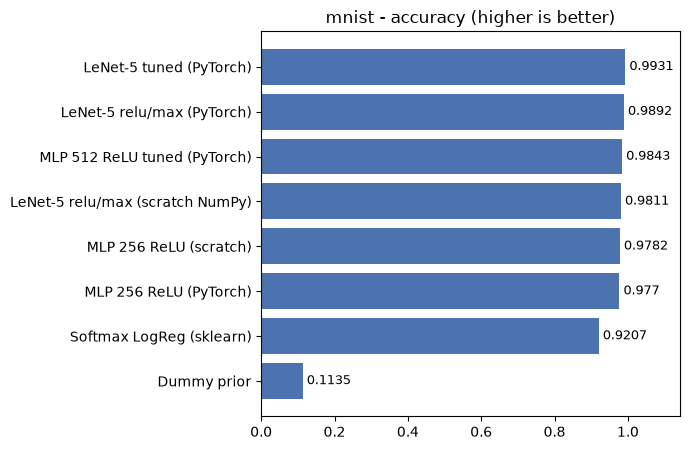

In [29]:
from learning_map.metrics import classification_metrics
from learning_map.results import compare, log_result

BENCH = "mnist"
final_params = {
    "channels": list(CHANNELS),
    "lr": float(best_cfg["lr"]),
    "weight_decay": float(best_cfg["weight_decay"]),
    "epochs": int(hist_aug["best_epoch"] if USE_AUG else best_cfg["best_epoch"]),
    "augment": USE_AUG,
}
print("最終設定：", final_params)

set_seed(0)
net_final = make_lenet(channels=CHANNELS)
fit_kw = dict(
    lr=final_params["lr"],
    weight_decay=final_params["weight_decay"],
    n_epochs=final_params["epochs"],
    verbose=False,
)
if USE_AUG:
    loader_full = DataLoader(
        MnistPadded(X_full_pad_u8, y_full, transform=augment),
        batch_size=128,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(0),
    )
    train_loader(net_final, loader_full, None, None, **fit_kw)
else:
    train_torch(net_final, X_full, y_full, **fit_kw)

# 名稱: (測試集機率 (10000, 10), 要記下的參數, 是否寫入 results/mnist.csv)
eval_models = {
    "MLP 512 (PyTorch, 32x32 pad, 50k)": (
        predict_proba_torch(mlp_base, X_test),
        MLP_CFG,
        False,
    ),
    "LeNet-5 relu/max (scratch NumPy)": (
        lenet_np.predict_proba(X_test),
        {"lr": lenet_np.lr, "epochs": lenet_np.n_epochs},
        True,
    ),
    "LeNet-5 relu/max (PyTorch)": (
        predict_proba_torch(net_default, X_test),
        {"lr": 0.1, "epochs": 10},
        True,
    ),
    "LeNet-5 tuned (PyTorch)": (
        predict_proba_torch(net_final, X_test),
        final_params,
        True,
    ),
}
test_scores = {}
for name, (prob, params, log_it) in eval_models.items():
    m = classification_metrics(y_test, prob.argmax(axis=1), prob)
    m["log_loss"] = round(log_loss(y_test, prob, labels=np.arange(10)), 4)
    test_scores[name] = m
    if log_it:
        log_result(BENCH, name, m, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "accuracy")

---
## 7. 診斷

1. 最終模型錯在哪：混淆矩陣、最「有把握地錯」的影像，並跟 MLP 比較。
2. 第一層學到了什麼：濾波器與特徵圖。
3. 兩個檢查「歸納偏置」的實驗：**打亂像素**（第 1 課 TODO 18 的延續）與**平移測試影像**（TODO 2 (2) 的預測）。

測試集錯誤：LeNet 69 筆、MLP 187 筆（第 1 課調參後的 MLP：157 筆）


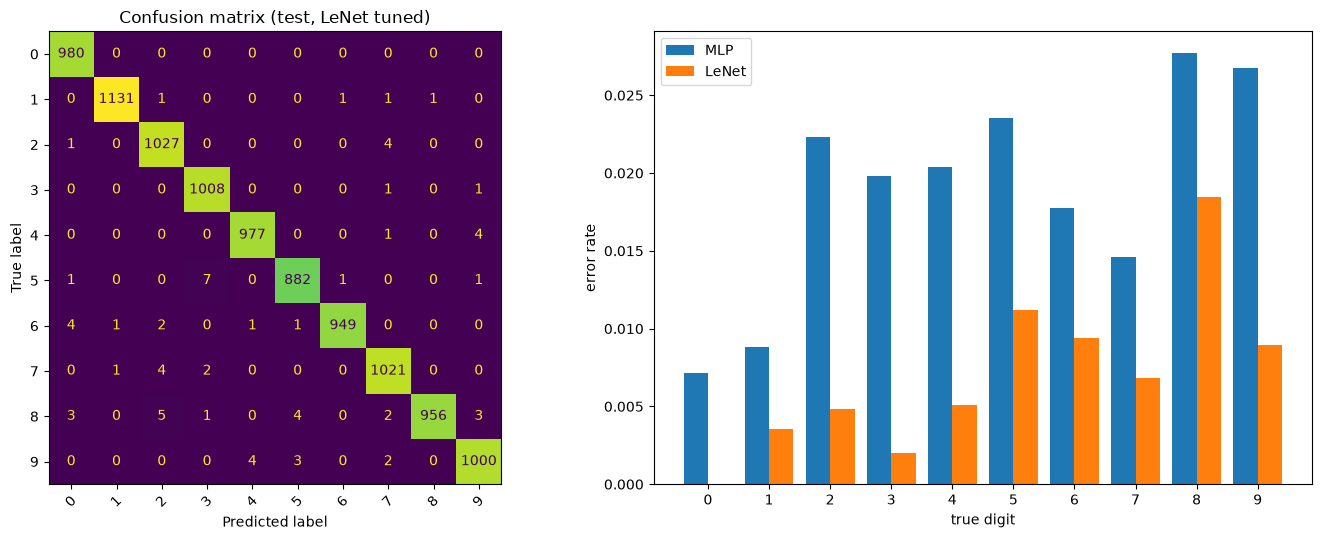

,count (true → pred)
5 → 3,7
8 → 2,5
6 → 0,4
2 → 7,4
9 → 4,4
4 → 9,4
8 → 5,4
7 → 2,4


兩個模型都錯的：42 筆；只有 LeNet 錯：27 筆；只有 MLP 錯：145 筆


In [30]:
from learning_map.metrics import plot_confusion_matrix

prob_te = predict_proba_torch(net_final, X_test)
pred_te = prob_te.argmax(axis=1)
wrong = np.flatnonzero(pred_te != y_test)
pred_mlp_te = predict_proba_torch(mlp_base, X_test).argmax(axis=1)
print(
    f"測試集錯誤：LeNet {len(wrong)} 筆、MLP {int((pred_mlp_te != y_test).sum())} 筆（第 1 課調參後的 MLP：157 筆）"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_confusion_matrix(y_test, pred_te, ax=axes[0])
axes[0].set_title("Confusion matrix (test, LeNet tuned)")
err_lenet = [1 - (pred_te[y_test == k] == k).mean() for k in range(10)]
err_mlp = [1 - (pred_mlp_te[y_test == k] == k).mean() for k in range(10)]
axes[1].bar(np.arange(10) - 0.2, err_mlp, width=0.4, label="MLP")
axes[1].bar(np.arange(10) + 0.2, err_lenet, width=0.4, label="LeNet")
axes[1].set_xticks(range(10))
axes[1].set_xlabel("true digit")
axes[1].set_ylabel("error rate")
axes[1].legend()
fig.tight_layout()
plt.show()

pairs = pd.Series(list(zip(y_test[wrong], pred_te[wrong]))).value_counts().head(8)
pairs.index = [f"{t} → {p}" for t, p in pairs.index]
display(pairs.rename("count (true → pred)").to_frame())

both = np.flatnonzero((pred_te != y_test) & (pred_mlp_te != y_test))
print(
    f"兩個模型都錯的：{len(both)} 筆；只有 LeNet 錯：{len(wrong) - len(both)} 筆；只有 MLP 錯：{int((pred_mlp_te != y_test).sum()) - len(both)} 筆"
)

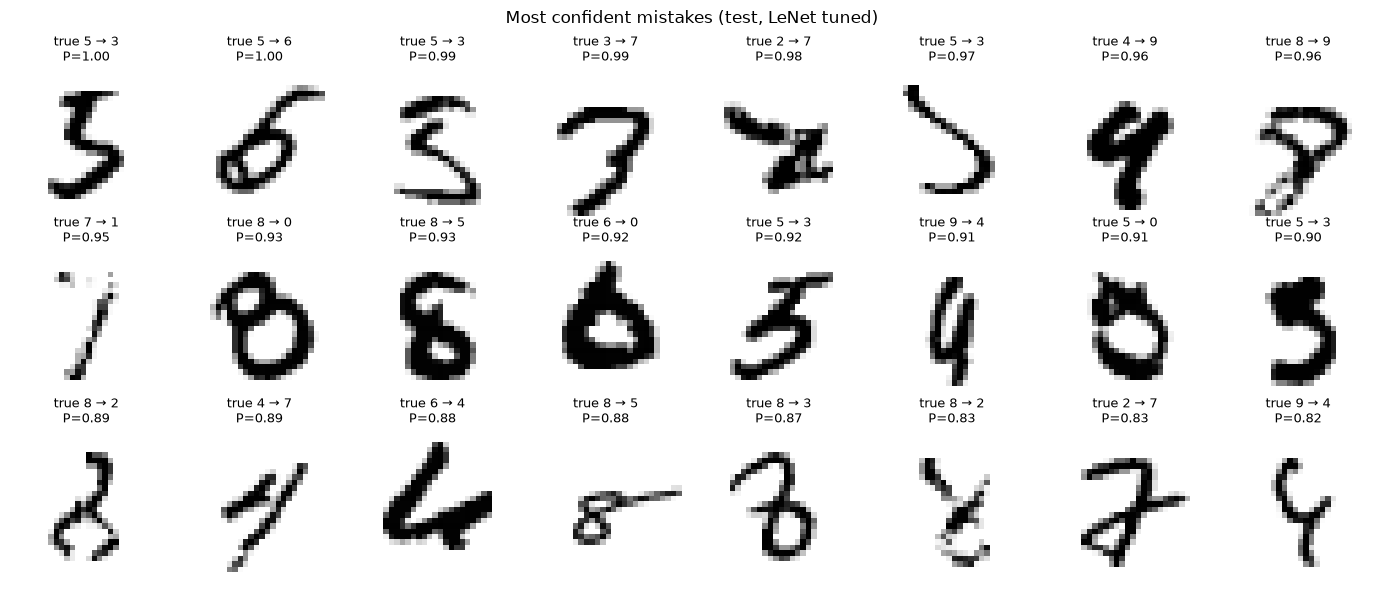

In [31]:
# 最「有把握地錯」的 24 張
conf_wrong = wrong[np.argsort(-prob_te[wrong].max(axis=1))][:24]
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax, i in zip(axes.ravel(), conf_wrong):
    ax.imshow(X_test_u8[i], cmap="gray_r")
    ax.set_title(
        f"true {y_test[i]} → {pred_te[i]}\nP={prob_te[i].max():.2f}", fontsize=9
    )
    ax.axis("off")
fig.suptitle("Most confident mistakes (test, LeNet tuned)")
fig.tight_layout()
plt.show()

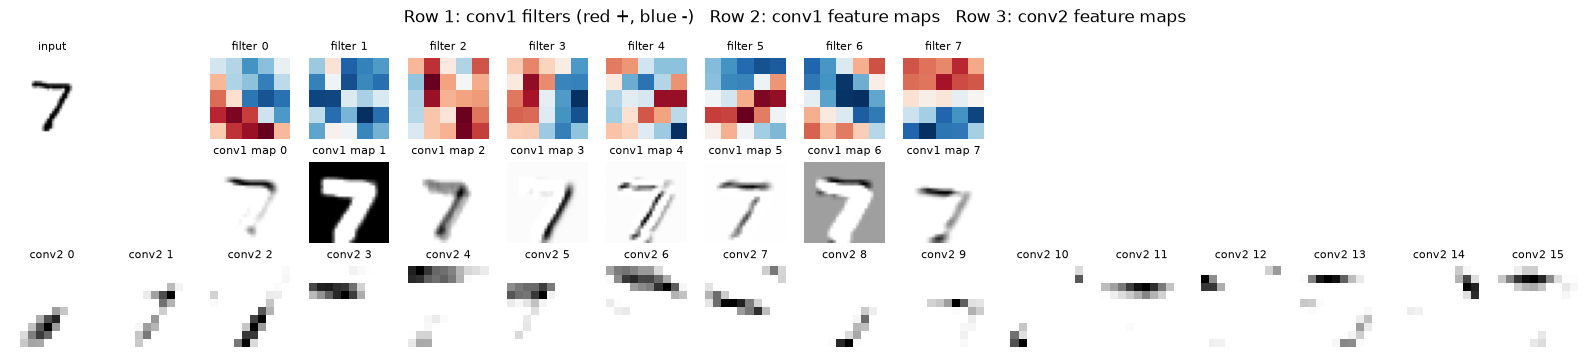

In [32]:
# 第一層的濾波器（每個 5×5），以及一張測試影像經過 conv1、conv2（＋激活）之後的特徵圖
W1_final = net_final[0].weight.detach().cpu().numpy()[:, 0]  # (c1, 5, 5)
x_demo = torch.as_tensor(X_test[:1], device=device)
with torch.no_grad():
    maps1 = net_final[:2](x_demo).cpu().numpy()[0]  # (c1, 28, 28)：conv1 → act1
    maps2 = (
        net_final[:5](x_demo).cpu().numpy()[0]
    )  # (c2, 10, 10)：→ pool1 → conv2 → act2

n1, n2 = min(len(W1_final), 8), min(len(maps2), 16)
fig, axes = plt.subplots(3, 16, figsize=(16, 3.6))
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].imshow(X_test[0, 0], cmap="gray_r")
axes[0, 0].set_title("input", fontsize=8)
for j in range(n1):
    v = np.abs(W1_final[j]).max()
    axes[0, 2 + j].imshow(W1_final[j], cmap="RdBu_r", vmin=-v, vmax=v)
    axes[0, 2 + j].set_title(f"filter {j}", fontsize=8)
    axes[1, 2 + j].imshow(maps1[j], cmap="gray_r")
    axes[1, 2 + j].set_title(f"conv1 map {j}", fontsize=8)
for j in range(n2):
    axes[2, j].imshow(maps2[j], cmap="gray_r")
    axes[2, j].set_title(f"conv2 {j}", fontsize=8)
fig.suptitle(
    "Row 1: conv1 filters (red +, blue -)   Row 2: conv1 feature maps   Row 3: conv2 feature maps"
)
fig.tight_layout()
plt.show()

,original pixels,permuted pixels
LeNet,0.9905,0.9674
MLP,0.9816,0.9831


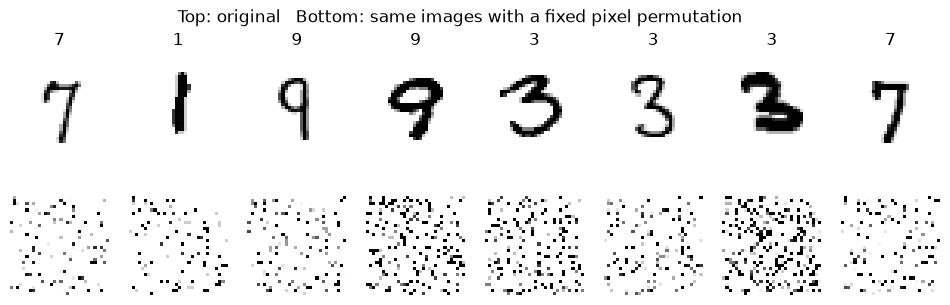

In [33]:
# 打亂像素：每張影像（32×32 = 1,024 個位置）套用「同一個」固定的排列，用同樣的設定重新訓練 LeNet 與 MLP
perm_px = np.random.default_rng(0).permutation(32 * 32)


def permute_pixels(X: np.ndarray) -> np.ndarray:
    """(n, 1, 32, 32) → 同 shape，每張影像的 1,024 個像素依 perm_px 重新排列。"""
    return X.reshape(len(X), -1)[:, perm_px].reshape(X.shape)


X_tr_perm, X_va_perm = permute_pixels(X_tr), permute_pixels(X_va)
perm_rows = {}
for name, make, cfg, ref in [
    (
        "LeNet",
        lambda: make_lenet(channels=CHANNELS),
        dict(
            lr=float(best_cfg["lr"]),
            weight_decay=float(best_cfg["weight_decay"]),
            n_epochs=MAX_EPOCHS,
        ),
        float(best_cfg["val_acc@best"]),
    ),
    ("MLP", make_mlp, MLP_CFG, hist_mlp["val_acc"][hist_mlp["best_epoch"] - 1]),
]:
    set_seed(0)
    h = train_torch(
        make(),
        X_tr_perm,
        y_tr,
        X_va_perm,
        y_va,
        restore_best=True,
        verbose=False,
        **cfg,
    )
    perm_rows[name] = {
        "original pixels": ref,
        "permuted pixels": h["val_acc"][h["best_epoch"] - 1],
    }
display(pd.DataFrame(perm_rows).T)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for j in range(8):
    axes[0, j].imshow(X_tr[j, 0], cmap="gray_r")
    axes[1, j].imshow(X_tr_perm[j, 0], cmap="gray_r")
    axes[0, j].set_title(str(y_tr[j]))
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Top: original   Bottom: same images with a fixed pixel permutation")
plt.show()

shift (px),-5,-4,-3,-2,-1,0,1,2,3,4,5
MLP,0.2581,0.4000,0.5869,0.8250,0.9644,0.9813,0.9693,0.8603,0.6362,0.3838,0.1921
LeNet (no aug),0.5666,0.7563,0.9139,0.9724,0.9894,0.9928,0.9887,0.9756,0.9166,0.7304,0.4755
LeNet + RandomAffine,0.9740,0.9871,0.9914,0.9928,0.9924,0.9932,0.9922,0.9913,0.9903,0.9870,0.9748


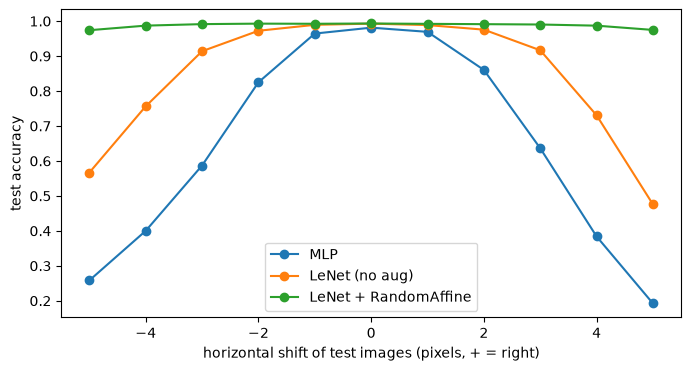

In [34]:
# 平移測試影像：往左／右平移 d 格（空出來的欄補背景），三個只在 50,000 筆上訓練的模型
shift_models = {
    "MLP": mlp_base,
    "LeNet (no aug)": net_noaug,
    "LeNet + RandomAffine": net_aug,
}
shifts = list(range(-5, 6))
shift_acc = pd.DataFrame(
    {
        name: [
            accuracy_score(
                y_test,
                predict_proba_torch(net, shift_right(X_test, d, fill=BG)).argmax(1),
            )
            for d in shifts
        ]
        for name, net in shift_models.items()
    },
    index=pd.Index(shifts, name="shift (px)"),
)
display(shift_acc.round(4).T)

fig, ax = plt.subplots(figsize=(8, 4))
for name in shift_acc.columns:
    ax.plot(shifts, shift_acc[name], "o-", label=name)
ax.set_xlabel("horizontal shift of test images (pixels, + = right)")
ax.set_ylabel("test accuracy")
ax.legend()
plt.show()

### TODO 17（問答）本章總結

> **(1)** 混淆矩陣
>
> **(a)** LeNet 在測試集錯了幾筆？MLP 呢？錯最多的是哪幾對（真實 → 預測）？跟第 1 課 MLP 的 4 ↔ 9、7 → 2 比，一樣嗎？

LeNet 69 筆、MLP 187 筆；這邊認錯的組別最多的是 (3, 5)，次之的是 (2, 8) 這組。

- 錯誤筆數 ✓（第 1 課調參後的 MLP 是 157 筆，LeNet 少了一半以上）。
- **修正**（方向）：要寫成「真實 → 預測」：最多的是 **5 → 3**（7 筆）、其次 **8 → 2**（5 筆），接著是 6 → 0、2 → 7、9 → 4、4 → 9、8 → 5、7 → 2（各 4 筆）。
- 跟第 1 課 MLP 比：4 ↔ 9 從 15 筆降到 8 筆、7 → 2 從 8 筆降到 4 筆 —— MLP 最常錯的那幾組，LeNet 大幅減少；剩下的錯誤分散在各組，沒有明顯集中。

> **(b)** 「兩個模型都錯」的有幾筆？看最有把握地錯的 24 張：其中有多少張你自己也認不太出來、或標籤看起來有問題？這對「MNIST 準確率的上限」代表什麼？

42 筆。有超過一半人眼也辨識困難。MNIST 準確率的上限等同人類真的能正確區分的準確率吧，以這個問題來說，畢竟 label 是人類標注的。

✓。補充：

- 只有 LeNet 錯的 27 筆、只有 MLP 錯的 145 筆：LeNet 修正了 MLP 大部分的錯，剩下的錯誤大多是**兩個模型都錯**的那 42 筆 —— 這些多半是寫法本身就模糊、甚至標籤有問題的影像。
- 上限來自**標籤本身的模糊與錯誤**：常被引用的人類錯誤率約 0.2%。當模型的錯誤率接近 0.7%（本章 99.31%），剩下的錯誤裡模糊樣本的比例越來越高，每再進步一點都更難。

> **(2)** 第一層的濾波器與特徵圖
>
> **(a)** conv1 的濾波器（紅正藍負）看起來像什麼？對照前置複習 1 的 $[1, 0, -1]$（偵測左右亮度變化）：有沒有濾波器在偵測某個方向的邊緣（一邊紅、一邊藍）？

墨水濃度嗎？不太清楚你的問題。

**補寫**（題目沒說清楚要看哪裡，以本章的圖說明）：

- **filter 7**：上半部紅、下半部藍 → 偵測「上面有墨水、下面沒有」的**水平邊緣**；它的特徵圖 map 7 只在數字 7 的**那一橫**上亮。
- **filter 1**：幾乎全藍 → 對墨水是負的反應；map 1 變成背景黑、數字白，等於把影像反轉。
- 其他濾波器也多半是「一邊紅、一邊藍」的形狀，只是方向不同 —— 這就是前置複習的 $[1, 0, -1]$（左減右）在二維、不同方向上的版本，而且是**訓練自己學出來的**，不是人設計的。

> **(b)** 同一張輸入的不同 conv1 特徵圖，亮的地方各在哪裡？為什麼同一個濾波器能在影像的任何位置偵測到同一種筆畫？

還是沒看懂問題。

**補寫**：比較同一張「7」的 8 張 conv1 特徵圖：

- map 3 只在**斜線**那一段亮；map 7 只在**上方的橫線**亮；map 4 亮在斜線的**兩側邊緣**。**每個濾波器各自負責一種筆畫**，所以 6（或 12）張特徵圖把影像拆成了「哪裡有橫線、哪裡有斜線、哪裡有邊緣」。
- conv2 更明顯：conv2 0、2、8 只對斜線反應，conv2 3、4、6 只對上方的橫線反應，conv2 7、9 對轉角反應 —— 比 conv1 更「整段筆畫」。
- 同一個濾波器能在任何位置偵測同一種筆畫，是因為**權重共享**：同一組 5×5 權重滑過整張圖，在每個位置做同樣的計算（TODO 12 (1)：平移等變性）。斜線寫在左邊或右邊，都是同一個「斜線偵測器」在反應。

> **(c)** conv2 的特徵圖只有 10×10，比 conv1 抽象很多。conv2 的一格「看到」輸入的多大範圍？（提示：conv2 的一格看 pool1 的 5×5；pool1 的一格對應 conv1 的 2×2；conv1 的一格看輸入的 5×5 → 一路推回去）

conv2 能看到的一格有 5×5 個像素格子。

**修正**：conv2 的一格看的是 **pool1** 的 5×5，不是輸入的 5×5 個像素。一路推回輸入：

| 層 | 一格對應的範圍 |
| --- | --- |
| conv2 | pool1 的 5×5 |
| pool1 | conv1 的 $5 \times 2 = 10$，即 10×10 |
| conv1 | 輸入的 $10 + 5 - 1 = 14$，即 **14×14** |

一格看到約 14×14 的輸入（數字本身約 20×20），所以 conv2 能偵測「整段筆畫」與「轉角」這種較大的結構；conv1 只看 5×5，只能偵測短短一段邊緣。這就是**感受野**隨深度變大（TODO 12 (2)(c) 的 pool2 是 16×16）。

> **(3)** 打亂像素（對照 TODO 2 (2)(a) 你的預測）
>
> **(a)** 打亂前後，LeNet 與 MLP 的 validation accuracy 各是多少？

打亂前後 MLP 的表現幾乎相同，但是 LeNet 就銳減 3% 左右。

✓。數字：

| | 原始像素 | 打亂像素 |
| --- | --- | --- |
| LeNet | 0.9905 | 0.9674（**−2.3**） |
| MLP | 0.9816 | 0.9831（+0.15，在雜訊範圍內） |

對照 TODO 2 (2)(a) 的預測「accuracy 暴跌、學不到東西」：方向對，但只掉了 2.3 個百分點，不是跌到亂猜（0.1）。LeNet 的 fc1 有 4.8 萬個參數，它跟 MLP 一樣能直接從 400 個特徵學分類；卷積層雖然失去了意義，仍然像一組「隨機的局部組合」，把資訊傳下去。

> **(b)** 為什麼 MLP 完全不受影響（第 1 課 TODO 18 (3)：第一層 $xW + b$，打亂 $x$ 等於打亂 $W$ 的列）、LeNet 卻明顯變差？打亂之後，LeNet 的 5×5 濾波器看到的「相鄰像素」還相鄰嗎？TODO 1 (2) 的「相鄰像素高度相關」還成立嗎？

MLP 不學局部特徵，它是每一個格子分開學，實際上打亂之後對於 MLP 來說是一樣的；但是對於 LeNet 會學局部特徵的模型來說就會有差異。

✓。更精確的說法：

- MLP：打亂輸入的像素 = 把第一層 $W$ 的列換順序，能表示的函數集合**完全一樣**，訓練起來也統計等價。
- LeNet：打亂後，5×5 視窗裡的 25 個像素來自影像上隨機的位置，**彼此不再相鄰**，TODO 1 (2) 的「相鄰像素高度相關」不成立。局部連接的假設錯了；權重共享則在共享「沒有意義的圖樣」—— 隨機一組像素的組合，在不同位置代表完全不同的東西。

> **(c)** 打亂後 LeNet 跟 MLP 誰比較好？這呼應 TODO 16 (2)(c) 的哪個說法？

打亂後 MLP 的表現比較好。

✓（0.9831 vs 0.9674）。呼應「**歸納偏置是雙面刃**」：假設對了（原始影像），LeNet 用 1/8.6 的參數贏過 MLP；假設錯了（打亂像素），內建的假設變成限制，反而輸給什麼都沒假設的 MLP。

> **(4)** 平移測試影像（對照 TODO 2 (2)(b) 你的預測）
>
> **(a)** 平移 2、3、5 格時，三個模型的 test accuracy 各是多少？

看圖吧，或是你製表，手打很難打出來。

**補寫**（從輸出表整理）：

| 平移（往右） | 0 | 2 | 3 | 5 |
| --- | --- | --- | --- | --- |
| MLP | 0.9813 | 0.8603 | 0.6362 | **0.1921** |
| LeNet（無資料增強） | 0.9928 | 0.9756 | 0.9166 | 0.4755 |
| LeNet ＋ RandomAffine | 0.9932 | 0.9913 | 0.9903 | **0.9748** |

（往左平移的結果類似：平移 5 格時 MLP 0.258、LeNet 0.567、LeNet ＋ 資料增強 0.974。）

對照 TODO 2 (2)(b) 的預測「MLP 不會有太大變化，LeNet 會變低」：結果**正好相反** —— MLP 掉得最快，平移 5 格只剩 19%，比亂猜好不了多少。

> **(b)** MLP 掉得最快的原因？（TODO 1 (1)：像素空間裡平移 2–3 格就比「別人寫的同一個數字」還不像自己）

MLP 掉最快的原因是，如果今天數字沒有出現在中間，比如在邊緣的地方，學到的東西會被其他數字在正中間的圖片給平均掉，所以偏移越多掉得越快。

**修正**（方向接近，但機制不是「被平均掉」）：

- MNIST 的數字都放在中央，所以 MLP 第一層**靠邊緣的那些權重，訓練時幾乎從來沒看過墨水** —— 它們的梯度（$x_j \cdot \text{dout}$，$x_j$ 是背景值）幾乎不帶資訊，等於沒被訓練過。數字一平移，墨水落在這些「沒學過」的權重上，輸出就變成接近隨機的結果。
- 即使還在中央附近，MLP 對每個位置也是**分別**學的：平移 3 格後，在像素空間裡跟原圖的相似度只剩 0.38（TODO 1 (1)），對 MLP 來說就是一張沒看過的圖。
- LeNet 的濾波器在每個位置都一樣，筆畫移到哪裡都會被偵測到（等變性），再加上池化的部分不變性，所以掉得慢很多。

> **(c)** 沒有資料增強的 LeNet 比 MLP 穩，但平移大了還是會掉（TODO 12：不變性是部分、近似的）。加上 RandomAffine 之後呢？資料增強與「把不變性寫進模型結構」是兩種不同的做法，各自的優缺點？（提示：哪一種需要訓練時多花計算？哪一種不管訓練資料長怎樣都保證成立？）

加上資料增強之後有變好。資料增強可以讓模型辨認更多種可能的狀況，而不變性是為了讓模型學會一種模式，兩者目的不相同。

- 「變好」✓：平移 5 格仍有 97.5%。
- **修正**「兩者目的不相同」：目的**相同**（都是讓模型對平移、旋轉等變換不敏感），差別在**怎麼做到**：

| | 寫進結構（卷積＋池化） | 資料增強 |
| --- | --- | --- |
| 怎麼來 | 結構本身保證 | 從資料中學會 |
| 適用的變換 | 只有設計好的那種（平移），而且只是部分不變 | 想加什麼都行（旋轉、縮放、粗細……） |
| 訓練成本 | 不用多花 | 本章每個 epoch 慢約 7 倍 |
| 保證 | 不管訓練資料長怎樣都成立（等變性是數學上的） | 只在看過的範圍內有效（例如沒練過平移 10 格就不保證） |

兩者是**互補**的：結構提供免費、保證的部分；資料增強補上結構沒涵蓋的變換與範圍。本章最好的模型兩者都用。

> **(5)** 一句話總結：卷積層的「局部連接」「權重共享」與池化，分別換到了什麼？代價（假設不成立時）是什麼？

局部連接可以學到相對位置的關係，權重共享可以辨認出相對位置，池化的部分可以把特定位置的特徵放大出來讓模型學習。代價是如果出現沒有被模型內建的特殊處理出現時，模型的表現會瞬間變得很差。

代價的方向 ✓，但「瞬間變得很差」太強（打亂像素只掉 2.3 個百分點，仍比大部分舊方法好）。**修正**前半：

| 設計 | 換到什麼 | 假設 |
| --- | --- | --- |
| **局部連接** | 學**局部特徵**（一段邊緣、一個轉角）；參數少約 39 倍（TODO 10 (2)） | 有用的資訊來自相鄰的像素 |
| **權重共享** | 同一個偵測器用在每個位置 → **平移等變性**；參數再少 784 倍；每筆資料訓練到的濾波器「乘上位置數」，省資料（TODO 16 (2)） | 同一種圖樣出現在哪裡都一樣 |
| **池化** | **丟掉**小範圍內的位置資訊（不是放大）→ 對小幅平移不敏感；特徵圖變小，計算量下降、感受野變大 | 特徵挪動一兩格，意義不變 |

**代價**：這些假設不成立時（打亂像素），內建的結構變成限制，表現輸給沒有假設的 MLP（0.967 vs 0.983）。

---
## 8. 本章小結

### 方法與結果

MNIST（補邊成 32×32；train 50,000／validation 10,000／test 10,000，切分與第 1 課相同；最終模型在 train + validation 共 60,000 筆上 refit）。val 為各模型在 validation 上的成績；test 只評估一次。

| 方法 | 做法 | 關鍵性質 | 參數 | val acc | test acc | test log loss |
| --- | --- | --- | --- | --- | --- | --- |
| Dummy prior | 輸出類別比例 | log loss $= \ln 10$ | — | 0.112 | 0.114 | 2.301 |
| MLP 1024–512–10（PyTorch） | 第 1 課的最佳設定（lr 0.3、wd 1e-4、15 epochs） | 240 個邊框像素的權重全部浪費 | 529,930 | 0.982 | 0.981 | 0.061 |
| LeNet-5 ReLU＋max（手寫 NumPy） | `Conv2d`／池化手寫 forward、backward；SGD lr 0.05、5 epochs | 梯度檢查 ~1e-10；與 autograd 差 ~1e-15 | 61,706 | 0.981 | 0.981 | 0.061 |
| LeNet-5 ReLU＋max（PyTorch） | `nn.Conv2d`、`nn.MaxPool2d`；lr 0.1、10 epochs | 預設初始化；MPS 比 CPU 快 10 倍 | 61,706 | 0.988 | 0.989 | 0.034 |
| LeNet-5 調參後（PyTorch） | 通道 (12, 32)、lr 0.1、wd 5e-4、`RandomAffine`、15 epochs、refit 60,000 筆 | 寬度、lr × wd 搜尋；資料增強改善超過 1 個 seed 標準差 | 117,078 | 0.992 | **0.993** | **0.021** |

其他實驗（validation）：

| 實驗 | 結果 |
| --- | --- |
| 1998 風格 vs 現代（10 epochs） | tanh＋avg 0.982、tanh＋max 0.986、ReLU＋avg 0.983、ReLU＋max 0.988；epoch 1 時差距 4.2 個百分點，主要來自池化 |
| 學習曲線（錯誤率） | 1,000 筆：LeNet 6.2% vs MLP 10.7%；5,000 筆：2.6% vs 5.4%；50,000 筆：0.95% vs 1.84%。MLP 約需 4–5 倍資料 |
| 打亂像素 | LeNet 0.9905 → 0.9674；MLP 0.9816 → 0.9831 |
| 測試影像右移 5 格 | MLP 0.19、LeNet 0.48、LeNet＋資料增強 0.97 |

- 測試集錯誤：LeNet（調參後）69 筆、MLP 187 筆；兩者都錯的 42 筆，多為寫法模糊或標籤可疑的影像。最多的是 5 → 3（7 筆）、8 → 2（5 筆）。

### 核心觀念

1. **卷積 = 局部連接 ＋ 權重共享**：$\text{out}_{ifrs} = \sum_c\sum_p\sum_q X_{i,c,r+p,s+q}\,W_{fcpq} + b_f$。一個濾波器 $(C, k, k)$ 滑過所有位置，每個位置算出一個「像不像這個圖樣」的分數，排成一張**特徵圖**；$F$ 個濾波器 → $F$ 張特徵圖。下標分工：**$f$ 選濾波器，$(r, s)$ 選位置，位置決定蓋住哪個 patch**。深度學習的「卷積」不翻轉濾波器（嚴格說是互相關）。
2. **形狀與參數**：$S_\text{out} = S_\text{in} - k + 1$（一般式 $\lfloor(S + 2P - k)/\text{stride}\rfloor + 1$）；卷積層參數 $= F(Ck^2) + F$，**與影像大小無關**；fan_in $= Ck^2$。輸出通道數只看 $F$，輸入通道 $C$ 只出現在參數量裡。$(n, 28, 28) \to (n, 1, 32, 32)$ 多出的通道軸只是陣列的排列方式（軸），不是特徵的個數（降維說的維度），資料量不變。
3. **參數量 vs 計算量**：MACs ≈ 權重個數 × 每個權重被用幾次。Linear 每個權重用 1 次（MACs ≈ 參數）；卷積每個權重用 $S_\text{out}^2$ 次。LeNet 參數 95.8% 在全連接層，計算 86% 在卷積層。時間還取決於實作：同樣 24 萬次乘加，einsum 有沒有 `optimize=True`（轉成矩陣乘法）差 34 倍。
4. **卷積的反向傳播**（同一個參數被用了好幾次，梯度就相加）：
   - $\partial L/\partial W_{fcpq} = \sum_{i,r,s}\text{dout}_{ifrs}\,X_{i,c,r+p,s+q}$（沿樣本**與位置**加總 —— 權重共享）；$\partial L/\partial b_f = \sum_{i,r,s}\text{dout}_{ifrs}$。
   - $\partial L/\partial X$：對每格權重 $(p, q)$，`dX[:, :, p:p+S_out, q:q+S_out] += Σ_f dout · W[f, :, p, q]`；切片長度是 $S_\text{out}$（不是 $k$），重疊處要累加；等價於「補 0 的 dout」與**翻轉的濾波器**做 full convolution。
   - 偏微分每次只對一個變數，其他當常數：對 $w$ 微分剩 $x$，對 $x$ 微分剩 $w$。
5. **池化**：沒有參數。平均池化的梯度平均分給 4 格（dout/$k^2$）；最大池化整個交給最大的那格。用 6 維視圖 `reshape(n, C, S/2, 2, S/2, 2)` 實作（只適用 stride = $k$、不重疊）。
6. **等變性 vs 不變性**：權重共享 ⇒ 卷積層**平移等變**（$f(Tx) = Tf(x)$，實驗誤差剛好 0）；stride 2 的池化只對偶數格平移保持等變。池化丟掉小範圍位置資訊、感受野隨深度變大（conv2 一格看 14×14、pool2 一格看 16×16）、全連接層再合併所有位置 → 越深越接近**不變**，但只是部分、近似的（右移 3 格預測不變 83%、4 格只剩 53%）。
7. **歸納偏置**（模型在看資料前就內建的假設）：局部連接（相鄰像素才相關，EDA：相關係數 4–5 格內 > 0）、權重共享（同一圖樣到處一樣）、池化（小幅平移不改意義）。假設對 → 用 1/8.6 的參數、1/4–1/5 的資料就勝過 MLP，資料少時差距最大；假設錯（打亂像素）→ 反而輸給 MLP。**用「假設」換「資料」**。
8. **為什麼 MLP 怕平移**：像素空間裡平移 3 格的相似度（0.38）已經跟「另一個數字」（0.38）差不多；MLP 每個位置用不同的權重，邊緣位置的權重訓練時幾乎沒看過墨水。
9. **1998 風格 vs 現代**：同一個 lr 下，平均池化稀釋梯度（每格 1/4）、有效步伐較小 → 收斂慢；預設初始化很小時 tanh ≈ 恆等，激活函數的影響反而不大。差距隨訓練縮小（主要差在速度，不是能力）。比較兩個因素時一次只變一個。
10. **PyTorch**：`nn.Conv2d` 的 weight $(F, C, k, k)$ 與手寫版同順序，不用轉置（`nn.Linear` 是 $(d_\text{out}, d_\text{in})$ 才要轉置）—— 要不要轉置只看「同一個權重的下標順序一不一樣」。裝置要實測：本機 MPS 比 CPU 快 10 倍。
11. **`DataLoader` ＋ transform**：逐筆處理（`__getitem__`、collate、每個 batch 搬到 GPU）比資料整批放在 GPU 上慢（2.4 倍，加 RandomAffine 7.4 倍）；必要時機是**每個 epoch 要新的隨機版本**（資料增強）或資料放不進記憶體。transform 作用在 uint8、標準化之前（補的 0 才是背景）。
12. **資料增強**：屬於正則化（乾淨訓練集上的 loss 變高、val 變好）；只能用**不改變標籤**、真實資料裡會出現的變換（手寫數字：平移、小角度旋轉；不能水平翻轉）。它與「把不變性寫進結構」目的相同、做法互補：結構免費且保證成立但只涵蓋設計好的變換；資料增強彈性大但要多花訓練時間、只在看過的範圍內有效。
13. **調參細節**：比較時**單位要一致**（val loss 的標準差不能拿來減 accuracy）；1-SE rule 在門檻內選**最簡單的**；最佳值落在搜尋邊界（本章的 weight decay 5e-4）要擴大範圍；weight decay 在模型開始過擬合時才有作用（lr 0.3 時最低點之後的上升被大幅壓住）。
14. **符號 → 程式的翻譯流程**：中文句子 → 每個下標配名字 → 決定保留／加總 → 寫成 `einsum` 字串 → 用最小例子與梯度檢查驗證。einsum 適合多軸的「相乘再加總」；單純加總用 `sum(axis=(...))`，逐元素用運算子，max／argmax 用一般函數。

### 待補強（之後回來可以學）

**架構與理論**
- ☐ LeNet-5 原版細節：C3 的手工連接表、可學係數的 subsampling、RBF 輸出層與它的 loss、縮放的 tanh $1.7159\tanh(\tfrac23 a)$
- ☐ 感受野的一般計算公式（含 stride、padding、dilation）與「有效感受野」
- ☐ 等變性的群論觀點；旋轉等變的 CNN（group-equivariant CNN）
- ☐ stride／池化造成的混疊（aliasing）與 anti-aliased CNN（為什麼平移 1 格就破壞等變性）
- ☐ 重疊池化（stride < k）的 backward；global average pooling（第三章）
- ☐ 卷積 = 稀疏、權重相等的矩陣乘法（Toeplitz 矩陣）的觀點

**數值與工程**
- ☐ im2col 與 `np.einsum(optimize=True)` 的實際運算路徑；用 `as_strided` 與 `np.add.at` 寫 col2im
- ☐ 卷積的 backward 寫成 full convolution（翻轉濾波器）並驗證
- ☐ FFT 卷積、Winograd 等快速卷積演算法
- ☐ 第一層不需要 $\partial L/\partial X$：在手寫版跳過，量測省下的時間
- ☐ `DataLoader(num_workers > 0)`：把 `Dataset` 寫進模組檔，在 macOS 上平行準備資料
- ☐ GPU 上的批次資料增強（例如 `torch.roll` 或 `F.grid_sample` 整批隨機平移）取代逐筆的 `RandomAffine`

**訓練與調參**
- ☐ 擴大 weight decay 的搜尋範圍（1e-3、2e-3）；資料增強 ＋ 更多 epoch（本章 best epoch 落在最後一個）
- ☐ tanh ＋ 平均池化在較大 lr 或更多 epoch 下能否追上
- ☐ 用更多 seed 估計標準差（3 個 seed 的標準差本身不準）
- ☐ 比較不同的資料增強組合（只平移、只旋轉、彈性變形 elastic distortion）

**評估與分析**
- ☐ 兩個模型都錯的 42 筆：逐一檢查是否為標籤錯誤
- ☐ McNemar 檢定比較 LeNet 與 MLP（同一個測試集上）
- ☐ 視覺化更深層的特徵：用梯度上升找出讓某個 conv2 單元反應最大的輸入
- ☐ 遮擋實驗（occlusion）：遮住影像的不同區域，看預測如何改變

### 問答 TODO 的筆記

各題的作答與批改已轉成 markdown，保留在各節原本的位置：TODO 1（EDA）、2（Baseline）、4（卷積的反向傳播推導）、10（形狀與參數量）、11（成本）、12（等變性與不變性）、14（PyTorch）、15、16（調參、資料增強、學習曲線）、17（總結）。